# Objectif 

Date de création : 22/04/2026

Mise en œuvre d'un filtrage dans le plan (f, k) dans le but d'extraire les composantes de grandes longueurs d'onde du rapport de fonction de transfert. 

Il s'agit ici, après l'étude dans un guide d'onde idéal, de tester l'approche par filtrage en nombre d'onde sur un cas réel d'un passage de bateau passif. 


In [1]:
# %matplotlib ipympl
import os
import sys
import numpy as np
import xarray as xr
import scipy.signal as sp
import matplotlib.pyplot as plt

from scipy.fft import rfft, rfftfreq
from scipy.signal import find_peaks


sys.path.append(r"C:\Users\baptiste.menetrier\Desktop\devPy\phd")

# from propa.rtf.rtf_utils import D_hermitian_angle_fast
from real_data_analysis.fiberscope_groix.src.localisation.rtf.sensibility.simu.sensi_simu_utils import (
    run_full_study,
    compute_rtf_dataset,
    plot_intensity,
    plot_tl_pi_frequency_range_plan
)
import source.global_constants as g
from publication.publication_figure import (
    PubFigure,
    LargeFigure,
    SmallFigure,
    color,
    set_subfigures_abc_labels,
)


from real_data_analysis.fiberscope_groix.src.localisation.rtf.rtf_mfp import (
    RTF_MFP_Processor,
)
from misc import progression_bar

from real_data_analysis.fiberscope_groix.src.localisation.rtf.sensibility.sensibility_study_utils import *

In [2]:
project_root = os.path.abspath(
    os.path.join(os.path.dirname(os.getcwd()), "..", "..", "..", "..", "..")
)
root_groix_data = os.path.join(project_root, "data", "fiberscope_groix_oct_2025")
root_groix_wav = os.path.join(root_groix_data, "wav")
root_groix_metadata = os.path.join(root_groix_data, "metadata")

root_folder = os.path.join(project_root, "real_data_analysis", "fiberscope_groix")
data_folder = os.path.join(root_folder, "data")
img_folder = os.path.join(root_folder, "img")

sensibility_img_folder = os.path.join(img_folder, "rtf_mfp", "sensibility")

In [3]:
sensibility_img_folder

'c:\\Users\\baptiste.menetrier\\Desktop\\devPy\\phd\\real_data_analysis\\fiberscope_groix\\img\\rtf_mfp\\sensibility'

# Étape 1 : chargement de la données 

In [4]:
# Load GPS dataset for station coordinates
ds_gps = xr.open_dataset(os.path.join(data_folder, "gps.nc"))

# Load arrivals dataset
fpath = os.path.join(
    data_folder,
    f"processed_arrivals.nc",
)
ds_arr = xr.open_dataset(fpath)
df_arr = ds_arr.to_dataframe()

## Calcul / chargement de la grandeur signante

On calcule les vecteurs de RTFs pour deux trajectoires de navires qui s'intersectent à proximité du réseau. 


In [5]:
root_data = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data"
root_img = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\img\rtf_mfp"
ref_rcv_id = 1
rtf_estimator = "cs-evd"

tau_ir_hat = 0.2  # estimated impulse response duration from sequence 144
tau_ir_hat *= 2  # To ensure we include the entire response


fsm_active_kwargs = {
    "bandfilter": None,
    "tau_ir": tau_ir_hat,
    "process_pulse_one_by_one": True,
    "estimate_ir_duration": False,
}
fsm_passive_kwargs = {
    "analysis_segment_duration": 5,
    "analysis_segment_alpha_overlap": 0.9,
}

fsm_props = {
    "fs": 2000,
    # "tau_rtf_analysis": 3,
    # "alpha_overlap": 0.5,
    # From the sensibility study
    "tau_rtf_analysis": 3.0,
    "alpha_overlap": 0.9,
}

rtf_mfp_processor = RTF_MFP_Processor(
    root_data=root_data,
    root_img=root_img,
    reference_receiver_id=ref_rcv_id,
    rtf_estimator=rtf_estimator,
    fsm_props=fsm_props,
    fsm_active_kwargs=fsm_active_kwargs,
    fsm_passive_kwargs=fsm_passive_kwargs,
    mode="overwrite",
    plot_replicas_features=False,
    verbose=True,
)

In [6]:
###########################
# Compute sequence replicas
###########################

id_library = 12
active_replicas_args = {
    "replica_sequence_ids": [],
    "replica_pulse_slice": [],
    "load_precomputed_feature": False,
}
passive_replicas_args = {
    "start_datetimes": [
        # datetime(year=2025, month=10, day=14, hour=19, minute=58, second=00),  # OK (1)
        datetime(year=2025, month=10, day=14, hour=1, minute=41, second=00),  # OK
        # datetime(year=2025, month=10, day=15, hour=10, minute=16, second=00),  # OK
    ],
    "end_datetimes": [
        # datetime(year=2025, month=10, day=15, hour=20, minute=20, second=00),  # OK (1)
        datetime(year=2025, month=10, day=14, hour=1, minute=46, second=00),  # OK
        # datetime(year=2025, month=10, day=14, hour=20, minute=3, second=00),  # OK
    ],
    "load_precomputed_feature": False,
}

rtf_mfp_processor.compute_library(
    active_feature_args=active_replicas_args,
    passive_feature_args=passive_replicas_args,
    id=id_library,
)


Deriving features for active source...

Deriving replicas for passive source...

RTF processing of passive recording
RTF feature estimation...
Progress: ████████████████████████████████████████████████████████████████████████████████████████████████████ 100%Using first vessel in list (default behavior) : mmsi=227315990
A library dataset with ID 12 already exists in C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\library. This library dataset will be overwritten.
Dataset (library) saved at C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\library\library_12.nc.


In [7]:
###########################
# Event computation
###########################

# Derive event
id_event = 12
active_feature_args = {
    "replica_sequence_ids": [],
    "load_precomputed_feature": False,
}
target_mmsi = None
passive_feature_args = {
    "start_datetimes": [
        # datetime(year=2025, month=10, day=14, hour=16, minute=40, second=0), # (1)
        datetime(year=2025, month=10, day=14, hour=16, minute=44, second=0),  # (2)
    ],
    "end_datetimes": [
        # datetime(year=2025, month=10, day=14, hour=16, minute=44, second=0), # (1)
        datetime(year=2025, month=10, day=14, hour=16, minute=49, second=0), # (2)
    ],
    "load_precomputed_feature": False,
}

rtf_mfp_processor.compute_event(
    active_feature_args=active_feature_args,
    passive_feature_args=passive_feature_args,
    id=id_event,
    target_mmsi=target_mmsi,
)


Deriving features for active source...

Provided pulse slices dont match number of pulses in sequence, no slice applied.

Deriving replicas for passive source...

RTF processing of passive recording
RTF feature estimation...


Progress: ████████████████████████████████████████████████████████████████████████████████████████████████████ 100%Using first vessel in list (default behavior) : mmsi=226340000
A event dataset with ID 12 already exists in C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\event. This event dataset will be overwritten.
Dataset (event) saved at C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\event\event_12.nc.


In [8]:
fpath = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\library\library_12.nc"
ds_lib = xr.open_dataset(fpath)
ds_lib

<xarray.Dataset> Size: 68MB
Dimensions:       (h_index: 3, f_rtf: 4097, replica_id: 590)
Coordinates:
  * h_index       (h_index) int64 24B 1 2 3
  * f_rtf         (f_rtf) float32 16kB 0.0 0.2441 0.4883 ... 999.5 999.8 1e+03
  * replica_id    (replica_id) int64 5kB 0 1 2 3 4 5 ... 584 585 586 587 588 589
Data variables:
    rtf_amp       (h_index, f_rtf, replica_id) float32 29MB ...
    rtf_phase     (h_index, f_rtf, replica_id) float32 29MB ...
    feature_psd   (f_rtf, replica_id) float32 10MB ...
    e_replica     (replica_id) float32 2kB ...
    n_replica     (replica_id) float32 2kB ...
    u_replica     (replica_id) float32 2kB ...
    replica_type  (replica_id) int64 5kB ...
Attributes: (12/16)
    reference_receiver_id:  1
    rtf_estimator:          cs-evd
    replica_type_1:         active
    replica_type_2:         passive
    description:            Library dataset containing RTF-MFP features for a...
    type:                   library
    ...                     ...
    obs2_n_apriori:         0.0
    obs2_u_apriori:         0.0
    obs3_e_apriori:         418.25417297268984
    obs3_n_apriori:         850.5744968832777
    obs3_u_apriori:         -7.991059774156952
    id:                     12

In [9]:
fpath = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\event\event_12.nc"
ds_event = xr.open_dataset(fpath)
ds_event

<xarray.Dataset> Size: 68MB
Dimensions:       (h_index: 3, f_rtf: 4097, replica_id: 590)
Coordinates:
  * h_index       (h_index) int64 24B 1 2 3
  * f_rtf         (f_rtf) float32 16kB 0.0 0.2441 0.4883 ... 999.5 999.8 1e+03
  * replica_id    (replica_id) int64 5kB 0 1 2 3 4 5 ... 584 585 586 587 588 589
Data variables:
    rtf_amp       (h_index, f_rtf, replica_id) float32 29MB ...
    rtf_phase     (h_index, f_rtf, replica_id) float32 29MB ...
    feature_psd   (f_rtf, replica_id) float32 10MB ...
    e_replica     (replica_id) float32 2kB ...
    n_replica     (replica_id) float32 2kB ...
    u_replica     (replica_id) float32 2kB ...
    replica_type  (replica_id) int64 5kB ...
Attributes: (12/16)
    reference_receiver_id:  1
    rtf_estimator:          cs-evd
    replica_type_1:         active
    replica_type_2:         passive
    description:            Event dataset containing RTF-MFP features for act...
    type:                   event
    ...                     ...
    obs2_n_apriori:         0.0
    obs2_u_apriori:         0.0
    obs3_e_apriori:         418.25417297268984
    obs3_n_apriori:         850.5744968832777
    obs3_u_apriori:         -7.991059774156952
    id:                     12

In [10]:
fmin = 100
fmax = 900
dist_args = {
    "fmin": fmin,
    "fmax": fmax,
    "dist_type": "hermitian_angle",
    "use_weighted_mean": False,
}

In [11]:
# ###########################
# # Matching library and event features
# ###########################
# rtf_mfp_processor.match(ds_library=ds_lib, ds_event=ds_event, dist_args=dist_args)

In [12]:
fig_folder = os.path.join(
    rtf_mfp_processor.root_results_fig, f"library_{id_library}_event_{id_event}"
)

In [13]:
# fpath = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\sequences\passive\sequence_passive_2025-10-15_10-14-00_to_2025-10-15_10-18-00_rtf.nc"
# fpath = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\sequences\passive\sequence_passive_2025-10-14_16-45-00_to_2025-10-14_16-50-00_rtf.nc"

root_sig = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\sequences\passive"
fpath_event = os.path.join(
    root_sig,
    f"sequence_passive_{passive_feature_args['start_datetimes'][0].strftime('%Y-%m-%d_%H-%M-%S')}_to_{passive_feature_args['end_datetimes'][0].strftime('%Y-%m-%d_%H-%M-%S')}_rtf.nc",
)
ds_sig_event = xr.open_dataset(fpath_event)

fpath_lib = os.path.join(
    root_sig,
    f"sequence_passive_{passive_replicas_args['start_datetimes'][0].strftime('%Y-%m-%d_%H-%M-%S')}_to_{passive_replicas_args['end_datetimes'][0].strftime('%Y-%m-%d_%H-%M-%S')}_rtf.nc",
)
ds_sig_lib = xr.open_dataset(fpath_lib)

# ds_sig = xr.open_dataset(fpath)
# ds_sig

## Visualisation des signaux 

In [14]:
# Load wav data and plot the corresponding sequence
ds_wav = xr.open_dataset(os.path.join(data_folder, "channel_H_wav.nc"))


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\sensibility\sensibility_study_utils.py:328: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 30.
  plt.setp(axs[-1].get_xticklabels(), rotation=15, ha="right")
C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\sensibility\sensibility_study_utils.py:344: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 30.
  plt.savefig(fpath, bbox_inches="tight")


c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 30.
  fig.canvas.print_figure(bytes_io, **kw)


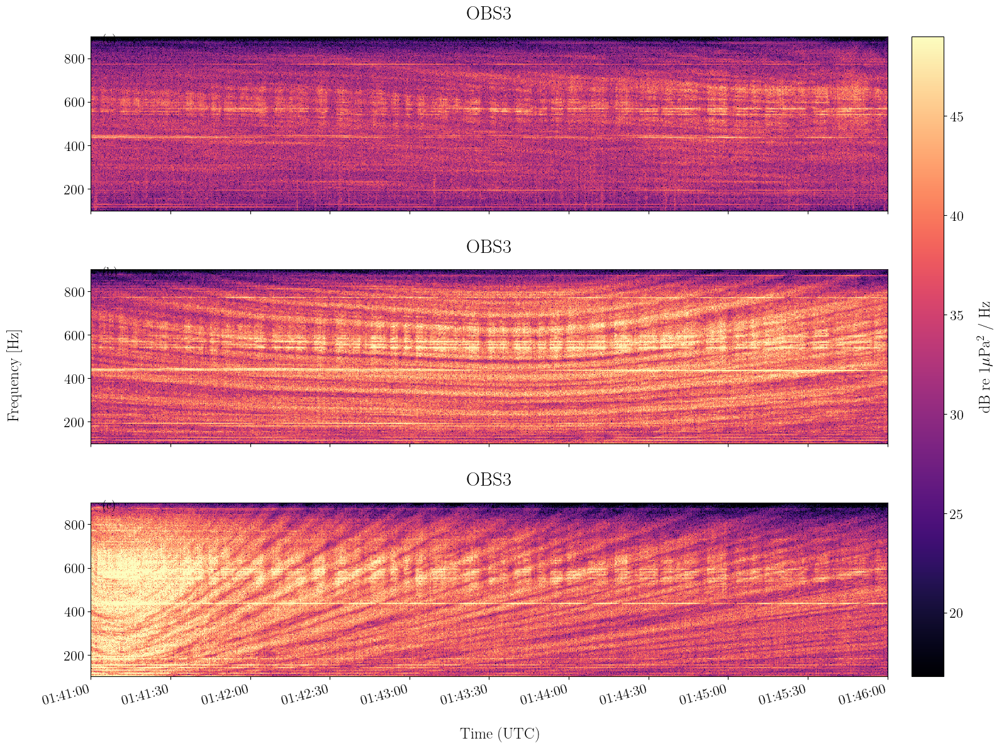

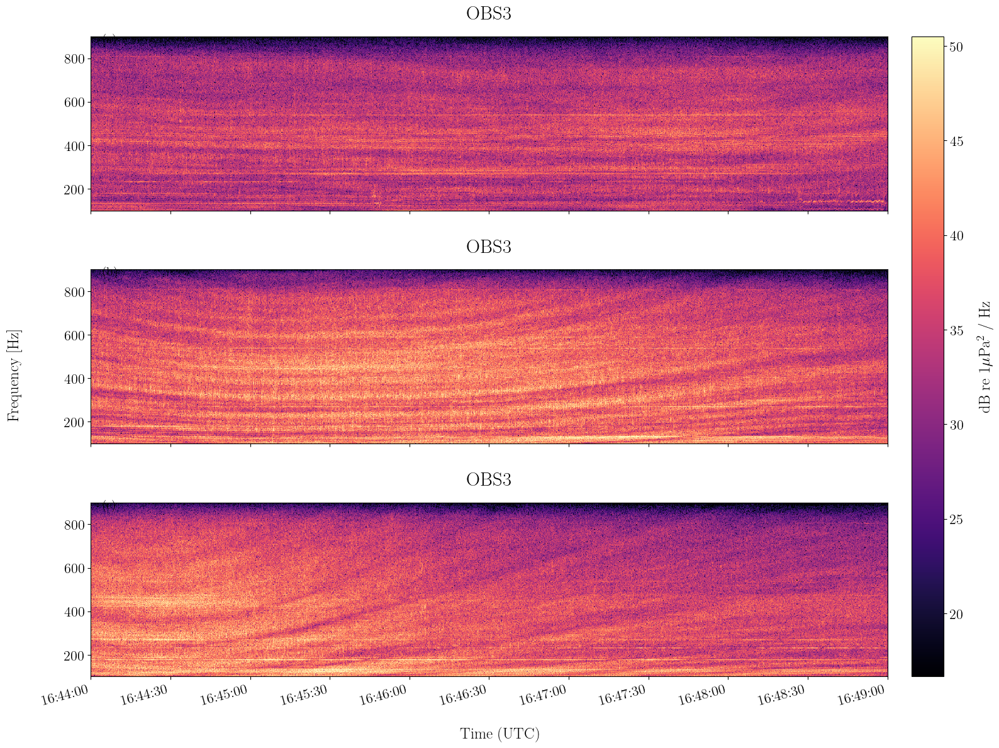

In [15]:
start_dt = passive_replicas_args["start_datetimes"][0]
ds_sig_lib.attrs["start_datetime"] = start_dt.strftime(ds_sig_lib.datetime_format)

plot_sequence_spectrogram(
    ds_sig_lib, ds_wav, fig_folder, nperseg=2**10, noverlap=2**9, fmin=fmin, fmax=fmax, fname="library_signal_spectrogram.png"
)

start_dt = passive_feature_args["start_datetimes"][0]
ds_sig_event.attrs["start_datetime"] = start_dt.strftime(ds_sig_event.datetime_format)
plot_sequence_spectrogram(
    ds_sig_event, ds_wav, fig_folder, nperseg=2**10, noverlap=2**9, fmin=fmin, fmax=fmax, fname="event_signal_spectrogram.png"
)

# Étape 2 : étude de la grandeur signante 

## Variations du module de $\Pi$ dans le plan (f, pos)


On s'intéresse aux variations de $\lvert \Pi \rvert$ dans le plan (f, numéro de réplique).

In [16]:
dist_rcv = get_dist_to_rcv(ds_lib)
obs_cpa_idx = np.argmin(dist_rcv, axis=1).flatten()
reps = ds_lib.replica_id.values

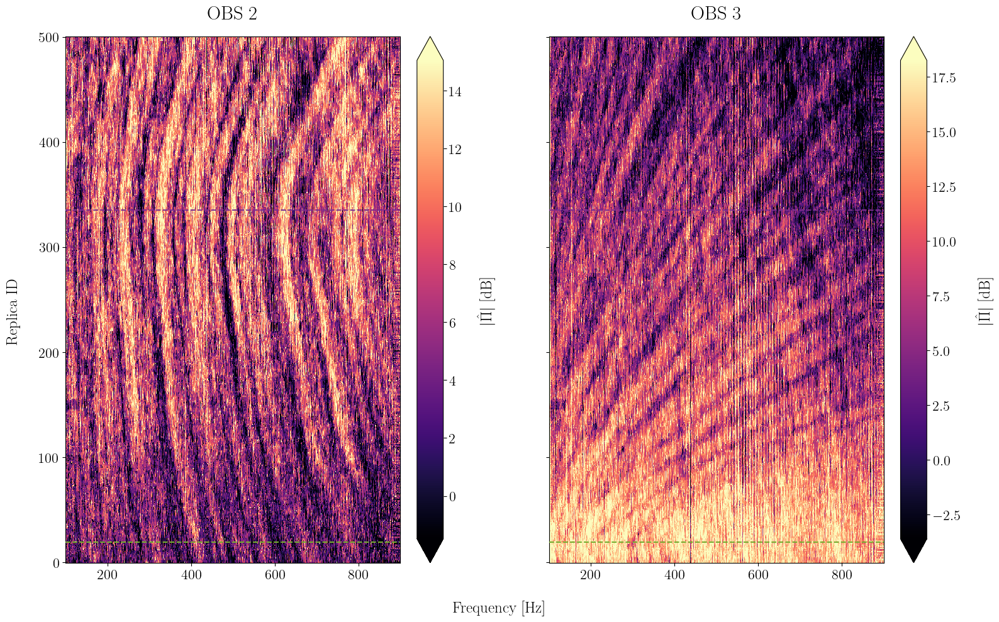

In [17]:
plot_rtf_mod_along_sequence(
    ds_lib,
    dist_rcv,
    obs_cpa_idx,
    reps,
    fig_folder,
    replica_id_slice=slice(0, 500),
    fmin=fmin,
    fmax=fmax,
    fname="library_rtf_mod_along_sequence.png",
)

In [18]:
dist_rcv = get_dist_to_rcv(ds_event)
obs_cpa_idx = np.argmin(dist_rcv, axis=1).flatten()
reps = ds_lib.replica_id.values

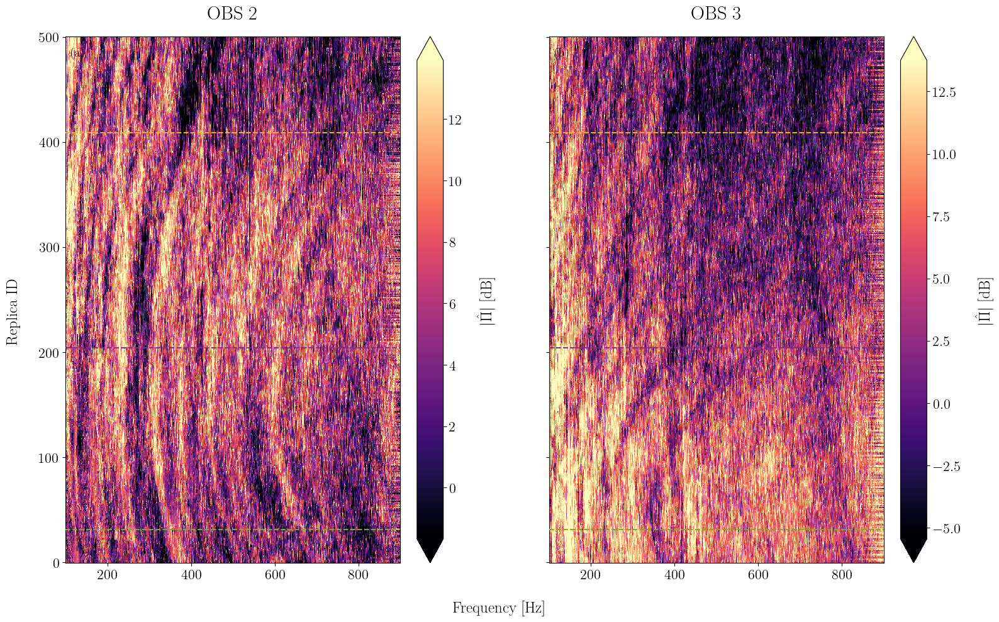

In [19]:
plot_rtf_mod_along_sequence(
    ds_event,
    dist_rcv,
    obs_cpa_idx,
    reps,
    fig_folder,
    replica_id_slice=slice(0, 500),
    fmin=fmin,
    fmax=fmax,
    fname="event_rtf_mod_along_sequence.png",
)

# Filtrage dans le plan (f, k)


L'objectif est d'extraire l'information associée aux interférences modales de grandes longueurs d'ondes (i.e à des petits $\Delta_{k{mn}}$) afin d'obtenir un lobe principal plus large permettant la mise en œuvre, en pratique de la méthode.

Pour se faire on applique une transformée de Fourier le long de l'axe r et on applique un filtre passe bas dans le domaine des nombres d'ondes. La distance $\theta$ est ensuite calculée sur les signaux filtrés. 

## Filtrage glissant 

Dans la suite : 

* La séquence entière est découpée en $Q$ fenêtres notées $\left ( I_q \right )_{q \in [0, Q-1]}$.
* Chaque fenêtre $I_q$ contient les estimations de $2P + 1$ vecteurs de RTF (correspondant ici à $2P + 1$ positions $r_p$ successives).
* Le recouvrement entre les fenêtres $I_q$ est de $2P$ positions $r_p$ de sorte que la fenêtre glisse d'une unique position lorsque q augmente de 1.  

In [20]:
def get_bootstrap_dist(ds, test_replica_id):
    # Select one replica_id to compare using bootstrap
    test_replica = ds.sel(replica_id=test_replica_id)
    # Remove from the rest of the features for bootstraping
    # bootstrap_replica = ds.drop_sel(replica_id=test_replica_id)
    bootstrap_replica = ds

    # Test RTF
    test_replica_rtf = test_replica.rtf_amp * np.exp(1j * test_replica.rtf_phase)

    # Other RTFs
    bootstrap_replica_rtfs = bootstrap_replica.rtf_amp * np.exp(
        1j * bootstrap_replica.rtf_phase
    )

    # Reshape to 4D array to be able to apply distance function : (n_rcv, n_freq, n_segment_dt) -> (n_rcv, n_freq, n_segment_dt, 1)
    bootstrap_replica_rtfs = bootstrap_replica_rtfs.values[..., np.newaxis]

    # # Compute dist
    dist_kwargs = {"ax_rcv": 0, "ax_f": 1, "apply_mean": True}
    # dist = D_hermitian_angle_fast(
    #     rtf_ref=test_replica_rtf.values,
    #     rtf=bootstrap_replica_rtfs,
    #     **dist_kwargs,
    # )

    rtf_ref = np.abs(test_replica_rtf.values)
    rtf = np.abs(bootstrap_replica_rtfs)
    dist = D_hermitian_angle_fast(
        rtf_ref=rtf_ref,
        rtf=rtf,
        **dist_kwargs,
    )

    # # EUCLIDEAN distance
    # d_rcv_1 = np.linalg.norm(
    #     np.abs(test_replica_rtf.sel(h_index=1).values)[:, np.newaxis]
    #     - np.abs(bootstrap_replica_rtfs[0, ...]), axis=0
    # )
    # d_rcv_2 = np.linalg.norm(
    #     np.abs(test_replica_rtf.sel(h_index=2).values)[:, np.newaxis]
    #     - np.abs(bootstrap_replica_rtfs[1, ...]),
    #     axis=0,
    # )
    # d_rcv_3 = np.linalg.norm(
    #     np.abs(test_replica_rtf.sel(h_index=3).values)[:, np.newaxis]
    #     - np.abs(bootstrap_replica_rtfs[2, ...]),
    #     axis=0,
    # )
    # dist = 1 / 3 * (d_rcv_1 + d_rcv_2 + d_rcv_3)

    # # # Compute dist
    # dist_kwargs = {"ax_rcv": 0, "ax_f": 1, "apply_mean": True}
    # dist = D_euclidian(
    #     rtf_ref=np.abs(test_replica_rtf.isel(h_index=slice(0, 1)).values),
    #     rtf=np.abs(bootstrap_replica_rtfs[0:1, ...]),
    #     **dist_kwargs,
    # )

    # # Expand rtf_ref along the necessary axes for broadcasting
    # rtf_ref_expanded = cast_matrix_to_target_shape(rtf_ref, rtf.shape)

    # # Calculate euclidian distance
    # # d_euc = np.sqrt(np.sum(np.abs(rtf_ref_expanded - rtf) ** 2, axis=1))
    # dist = np.linalg.norm(rtf_ref_expanded - rtf, axis=1)

    return dist 

In [21]:
def get_bootstrap_dist_matrix(ds):
    dist_mat = []
    for i, id in enumerate(ds.replica_id.values): 
        dist_id = get_bootstrap_dist(ds=ds, test_replica_id=id)
        # dist_id = np.concatenate([dist_id[0:i], np.array([0]), dist_id[i:]])       # Add 0 on diagonal 
        dist_mat.append(dist_id)

    dist_mat = np.array(dist_mat)
    return dist_mat

In [22]:
def get_dist_to_rcv(ds):
    e = ds["e_replica"].values
    n = ds["n_replica"].values

    rep_pos = np.column_stack((e, n))
    dist_to_rcv = []
    for i_rcv in ds.h_index.values:
        e_rcv = ds.attrs[f"obs{i_rcv}_e_apriori"]
        n_rcv = ds.attrs[f"obs{i_rcv}_n_apriori"]
        rcv_pos = np.column_stack((e_rcv, n_rcv))

        spatial_dist = cdist(rep_pos, rcv_pos, metric="euclidean")
        dist_to_rcv.append(spatial_dist)

    return np.array(dist_to_rcv)


In [23]:
def process_bootstrap(ds, root_img):
    theta_mat = get_bootstrap_dist_matrix(ds=ds)
    plt.figure()
    cpa_idx = []
    for i, i_rcv in enumerate(ds.h_index.values):
        plt.plot(dist_rcv[i, :], label=f"OBS{i_rcv}", color=color(i))

        cpa_rcv_idx = np.argmin(dist_rcv[i, :])
        plt.axvline(cpa_rcv_idx, linestyle="--", color=color(i))
        cpa_idx.append(cpa_rcv_idx)

    plt.ylabel(f"Distance [m]")
    plt.xlabel("Replica index")

    vmax = np.nanpercentile(theta_mat, 75)

    plt.figure()
    im = plt.pcolormesh(theta_mat, cmap="magma", vmax=vmax)
    plt.colorbar(im, label=r"$\theta$ [°]")

    # Add CPA indication
    for i, i_rcv in enumerate(ds.h_index.values):
        plt.scatter(
            cpa_idx[i],
            cpa_idx[i],
            marker="o",
            s=150,
            color=color(i),
            label=f"OBS{i_rcv}",
        )
    plt.xlabel("Bootstrap index")
    plt.ylabel("Test index")
    plt.legend()

    fpath = os.path.join(
        root_img,
        f"{ds.type}_bootstrap_Md_Mtheta_win{rtf_mfp_processor.fsm_passive_analysis_segment_duration}s_overlap{rtf_mfp_processor.fsm_passive_analysis_segment_alpha_overlap}.png",
    )
    plt.savefig(fpath)

    # Quelques lignes à la loupe
    i_ls = [200, 250, 300]
    # i_ls = [600, 640, 650, 660, 670, 700]

    # i_ls = rep_selection

    plt.figure()
    im = plt.pcolormesh(theta_mat, cmap="magma", vmax=vmax)
    for k, i_l in enumerate(i_ls):
        plt.axhline(i_l + 0.5, color=color(k), label=rf"$l_{k}$")

    plt.colorbar(im, label=r"$\theta$ [°]")
    # Add CPA indication
    for i, i_rcv in enumerate(ds.h_index.values):
        plt.scatter(
            cpa_idx[i],
            cpa_idx[i],
            marker="o",
            s=50,
            color=color(i),
            label=f"OBS{i_rcv}",
        )
    plt.xlabel("Bootstrap index")
    plt.ylabel("Test index")
    plt.legend(fontsize=16, loc="upper left")

    fpath = os.path.join(
        root_img,
        f"{ds.type}_bootstrap_Md_Mtheta_win{rtf_mfp_processor.fsm_passive_analysis_segment_duration}s_overlap{rtf_mfp_processor.fsm_passive_analysis_segment_alpha_overlap}_zoomobs3_lines.png",
    )
    plt.savefig(fpath)

    plt.figure()
    for k, i_l in enumerate(i_ls):
        plt.plot(theta_mat[i_l, :], marker="o", color=color(k), label=rf"$l_{k}$")

    plt.legend(fontsize=18)
    plt.xlabel("Index")
    plt.ylabel(r"$\theta$ [°]")

    fpath = os.path.join(
        root_img,
        f"{ds.type}_bootstrap_theta_selectedlines_win{rtf_mfp_processor.fsm_passive_analysis_segment_duration}s_overlap{rtf_mfp_processor.fsm_passive_analysis_segment_alpha_overlap}.png",
    )
    plt.savefig(fpath)

In [24]:
def process_smooth(
    ds,
    root_img, 
    P=12,
    compute_bootstrap=True,
):
    n_r = ds.replica_id.size

    # Define the size of the Iq windows
    n_overlap_I = 1
    n_I = 2 * P + 1
    # size_I_r = n_I * dr

    print(
        f"Selected window I size:  n_I = {n_I} samples"
    )

    # Compute the number of I_q windows Q
    Q = int(np.floor((n_r + n_overlap_I - n_I)/n_overlap_I))
    print(f"Number of available segments I : Q = {Q}")

    # Apply smoothing
    f = ds.f_rtf.values 
    qth = 99.5

    idx_rcvs = [
        idx
        for idx in ds.h_index.values
        if idx != ds.reference_receiver_id
    ]

    smooth_data = np.ones_like(ds.rtf_amp)
    for idx_rcv in idx_rcvs:

        rtf_mod = ds.rtf_amp.sel(h_index=idx_rcv)
        rtf_mod_smooth = rtf_mod.copy().values

        for q in range(0, Q):
            I_q_inf = q * n_overlap_I
            I_q_sup = q * n_overlap_I + n_I
            I_q_center = q * n_overlap_I + P  # P = n_I // 2
            # print(I_q_inf, I_q_sup)

            # Select I_q
            rtf_I_q = rtf_mod.isel(replica_id=slice(I_q_inf, I_q_sup))
            # Apply filter
            gamma_q = 10 * np.log10(rtf_I_q**2)
            # Apply FFT along the r dimension
            gamma_q_fft = np.fft.rfft(gamma_q, axis=1)
            gamma_q_psd = np.abs(gamma_q)

            k = np.fft.rfftfreq(gamma_q.shape[1], d=1)  #

            # Extract quantiles of the distribution and their corresponding x values
            q_th = np.percentile(gamma_q_psd, qth, axis=1)

            # # Get abcisse corresponding to the quantiles : x_q1, mu(x_q1) = q1, x_q2, mu(x_q2) = q2, x_q3, mu(x_q3) = q3
            dx_qth = np.abs(gamma_q_psd - q_th[:, np.newaxis])  #
            idx_xqth = np.argmin(dx_qth, axis=1)
            x_qth = k[idx_xqth]
            # print(x_qth)

            # Smooth with rolling average to avoid abrupt changes betweens adjacent bins
            n_roll_avg = 5
            x_qth = np.convolve(x_qth, np.ones(n_roll_avg) / n_roll_avg, mode="same")

            # TODO change this
            # x_qth[:] = 0.035
            x_qth[:] = k[0] * 0.9

            # Filter desired k
            gamma_q_fft_filt = np.copy(gamma_q_fft)  # nf, nk
            # Define dedicated mask
            kk, ff = np.meshgrid(k, f)
            mask_fk = kk > x_qth[:, np.newaxis]
            # Apply mask
            gamma_q_fft_filt[mask_fk] = 0
            gamma_q_filt = np.fft.irfft(gamma_q_fft_filt, n=rtf_I_q.shape[1], axis=1)
            rtf_mod_q_filt = 10 ** (gamma_q_filt / 20)

            if q == 0:
                q1 = np.percentile(gamma_q_psd, 25, axis=1)
                q2 = np.percentile(gamma_q_psd, 50, axis=1)
                q3 = np.percentile(gamma_q_psd, 75, axis=1)

                # Q1
                dx_q1 = np.abs(gamma_q_psd - q1[:, np.newaxis])  #
                idx_xq1 = np.argmin(dx_q1, axis=1)
                x_q1 = k[idx_xq1]
                # Q2
                dx_q2 = np.abs(gamma_q_psd - q2[:, np.newaxis])
                idx_xq2 = np.argmin(dx_q2, axis=1)
                x_q2 = k[idx_xq2]
                # Q3
                dx_q3 = np.abs(gamma_q_psd - q3[:, np.newaxis])
                idx_xq3 = np.argmin(dx_q3, axis=1)
                x_q3 = k[idx_xq3]

                plt.figure()
                plt.plot(k, gamma_q_psd[0, :])
                plt.axvline(x_q1[0], color=color(1), label="Q1")
                plt.axvline(x_q2[0], color=color(2), label="Q2")
                plt.axvline(x_q3[0], color=color(3), label="Q3")
                plt.axvline(x_qth[0], color=color(4), label="Qth")
                plt.legend()

                plt.figure()
                rtf_I_q.plot(x="replica_id", cmap="magma")

                plt.figure()
                vmin = np.percentile(gamma_q_psd, 10)
                vmax = np.percentile(gamma_q_psd, 90)
                plt.pcolormesh(f, k, gamma_q_psd.T, cmap="magma", vmax=vmax, vmin=vmin)
                plt.plot(f, x_qth, color="cyan", label="Threshold", zorder=10)
                plt.colorbar()
                plt.xlabel("f [Hz]")
                plt.ylabel("k [1/m]")
                plt.legend()

                plt.figure()
                rtf_I_q_fft_filt_psd = np.abs(gamma_q_fft_filt) ** 2
                vmin = np.percentile(gamma_q_psd, 10)
                vmax = np.percentile(gamma_q_psd, 90)
                plt.pcolormesh(
                    f, k, np.abs(rtf_I_q_fft_filt_psd).T, cmap="magma", vmax=vmax, vmin=vmin
                )
                plt.plot(f, x_qth, color="cyan", label="Threshold", zorder=10)
                plt.colorbar()
                plt.xlabel("f [Hz]")
                plt.ylabel("k [1/m]")
                plt.legend()

                plt.figure()
                rtf_I_q_filt_xr = xr.zeros_like(rtf_I_q)
                rtf_I_q_filt_xr.data = gamma_q_filt
                rtf_I_q_filt_plot = 10 * np.log10(rtf_I_q_filt_xr**2)
                rtf_I_q_filt_plot.plot(x="replica_id", cmap="magma")

                # print(I_q_center)

            # Store modified rtf
            rtf_mod_smooth[:, I_q_center] = rtf_mod_q_filt[:, P]
            # rtf_I_q_filt_P = rtf_I_q_filt[:, P]     # Center of the box
            # smooth_rtfs.append(rtf_I_q_filt_P)

        i_rcv = np.argmin(np.abs(ds_lib.h_index.values - idx_rcv))
        smooth_data[i_rcv, ...] = rtf_mod_smooth

    ds_smooth = ds.copy()
    ds_smooth.rtf_amp.data = smooth_data

    dist_rcv = get_dist_to_rcv(ds=ds)

    # Plot comparison
    # plot_gamma_along_sequence(
    #     ds,
    #     dist_rcv,
    #     obs_cpa_idx,
    #     reps,
    #     fig_folder,
    #     replica_id_slice=slice(0, 500),
    #     fmin=fmin,
    #     fmax=fmax,
    # )

    plot_gamma_along_sequence(
        ds_smooth,
        dist_rcv,
        obs_cpa_idx,
        reps,
        fig_folder,
        # replica_id_slice=slice(0, 500),
        fmin=fmin,
        fmax=fmax,
        fname=f"{ds_smooth.type}_smooth_k_P{P}_gamma_along_sequence.png",
    )

    before_smooth = 10 * np.log10(ds.rtf_amp.sel(h_index=idx_rcv))
    after_smooth = 10 * np.log10(ds_smooth.rtf_amp.sel(h_index=idx_rcv))

    sel_reps = [200, 220, 240]
    for i_rep, rep in enumerate(sel_reps):
        before_smooth_rs = before_smooth.sel(replica_id=rep, method="nearest")
        after_smooth_rs = after_smooth.sel(replica_id=rep, method="nearest")

        plt.figure()
        before_smooth_rs.plot(
            x="f_rtf", label=f"Original (rep = {before_smooth_rs.replica_id.values:.2f})"
        )
        after_smooth_rs.plot(
            x="f_rtf", label=f"Smooth (rep = {after_smooth_rs.replica_id.values:.2f})"
        )
        # plt.xscale("log")
        plt.legend()

        plt.xlim([100, 300])

    if compute_bootstrap:
        root_bootstrap = os.path.join(
            root_img,
            "bootstrap",
        )
        root_img_1 = os.path.join(
            root_bootstrap, "original"
        )
        os.makedirs(root_img_1, exist_ok=True)
        print(f"Processing bootstrap for original dataset")
        process_bootstrap(ds=ds, root_img=root_img_1)

        root_img_2 = os.path.join(
            root_bootstrap, f"smooth_k_P{P}"
        )
        os.makedirs(root_img_2, exist_ok=True)
        print(f"Processing bootstrap for smoothed dataset")
        process_bootstrap(ds=ds_smooth, root_img=root_img_2)

    return ds_smooth

In [25]:
# Load or compute
load_precomputed = False


Selected window I size:  n_I = 25 samples
Number of available segments I : Q = 566


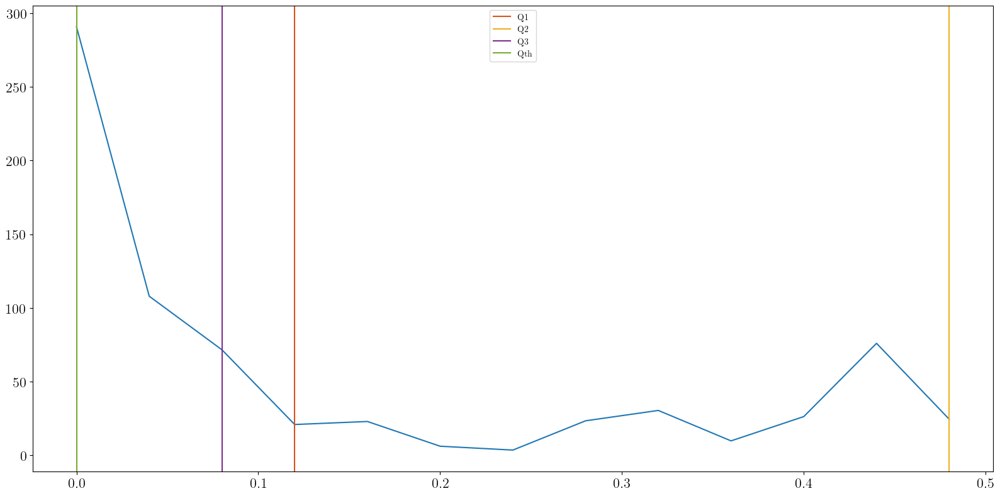

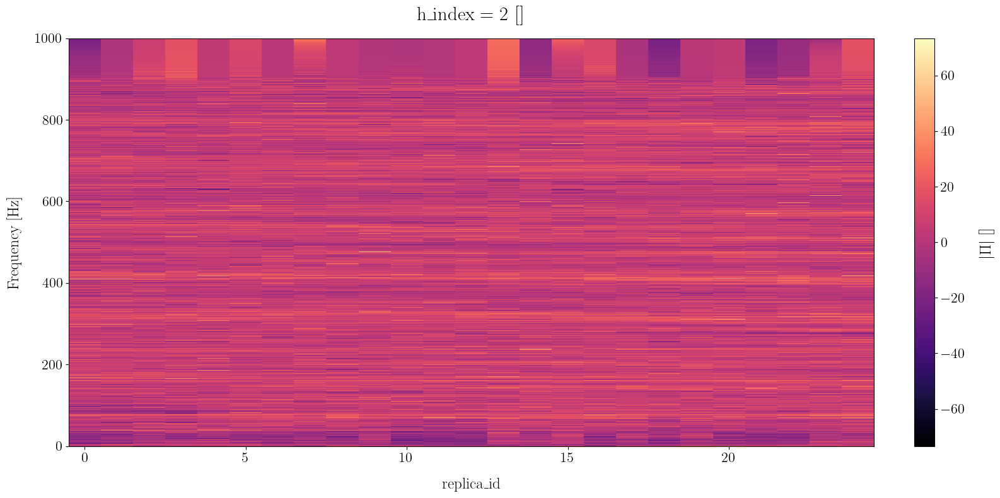

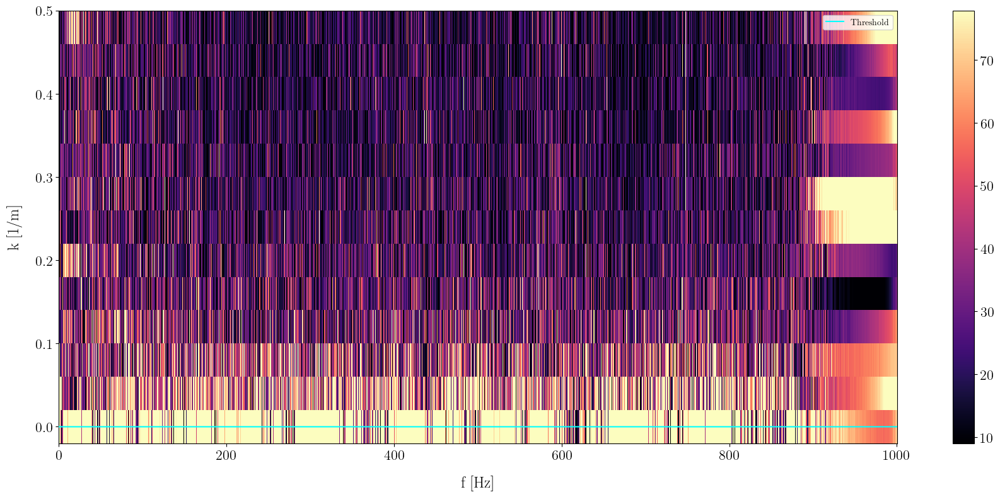

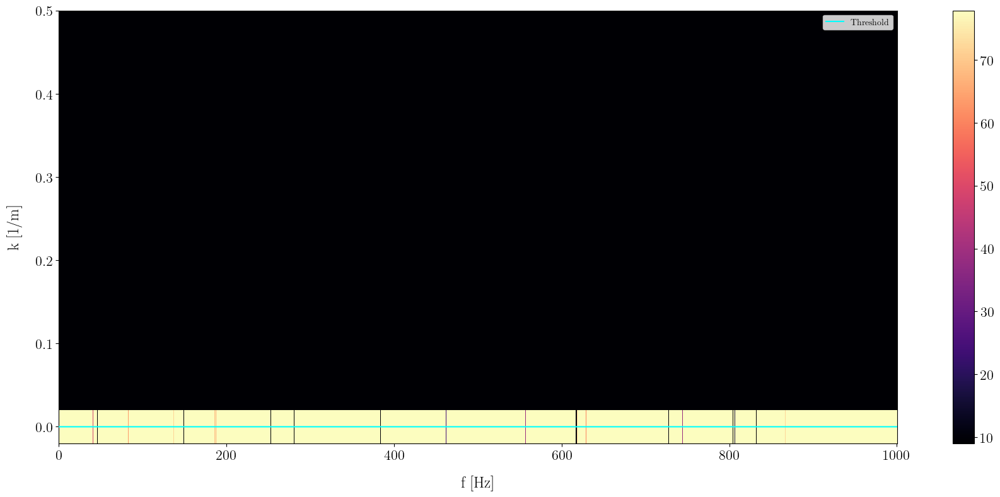

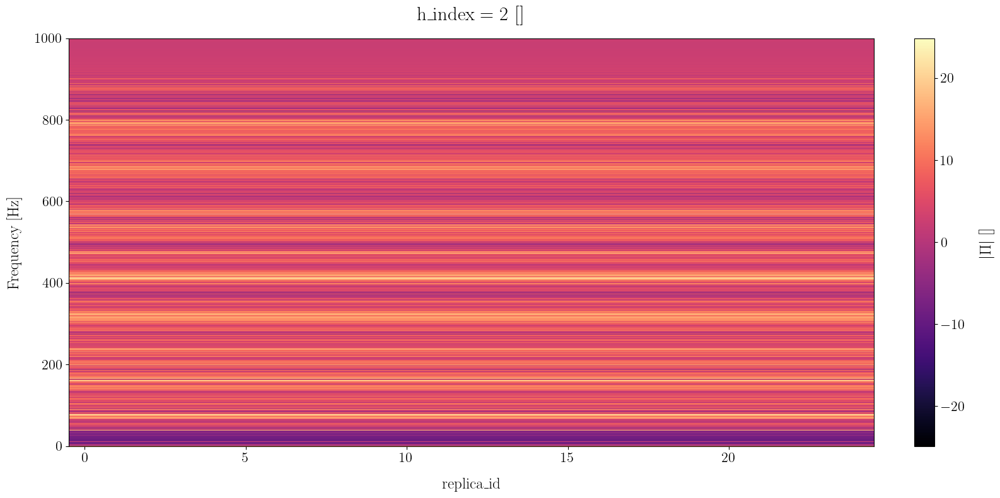

...

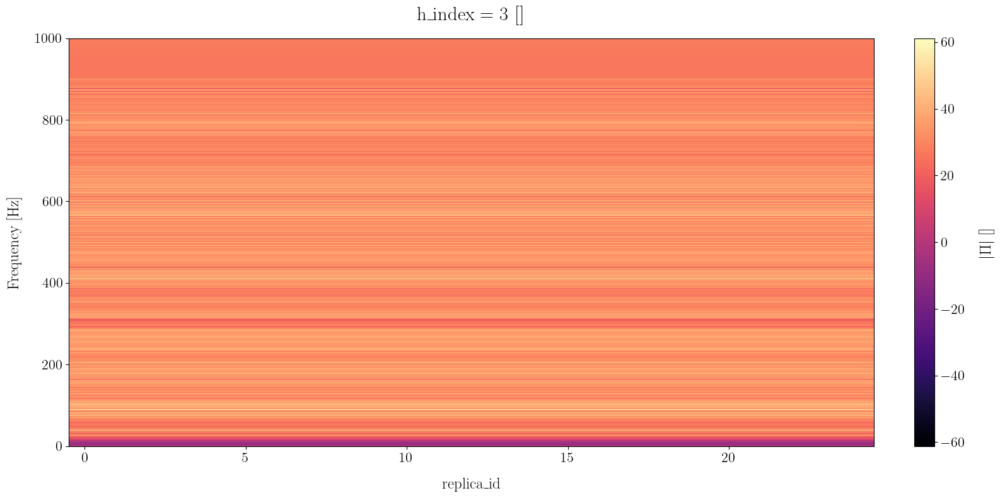

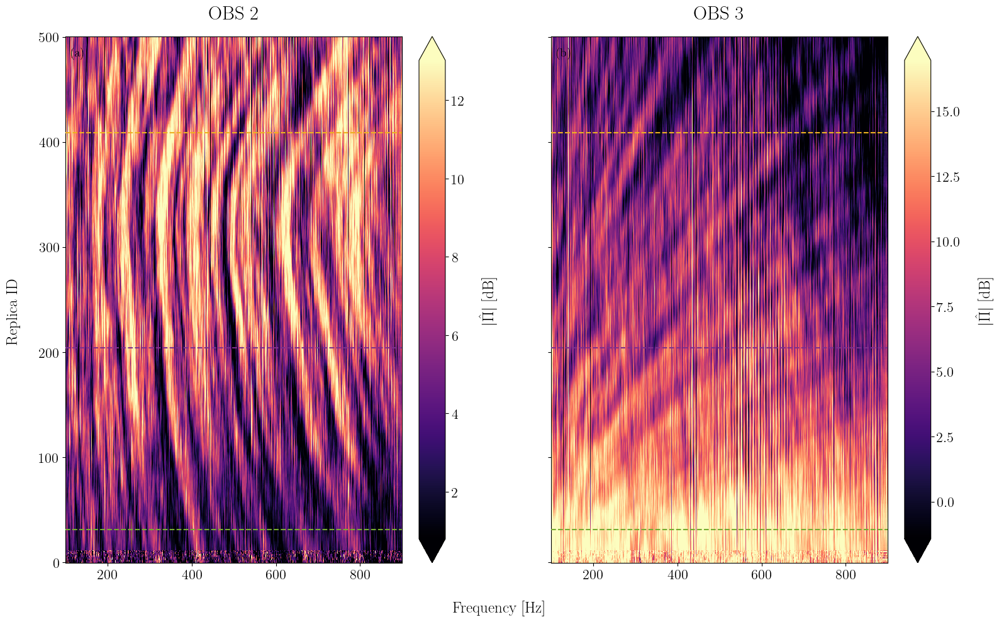

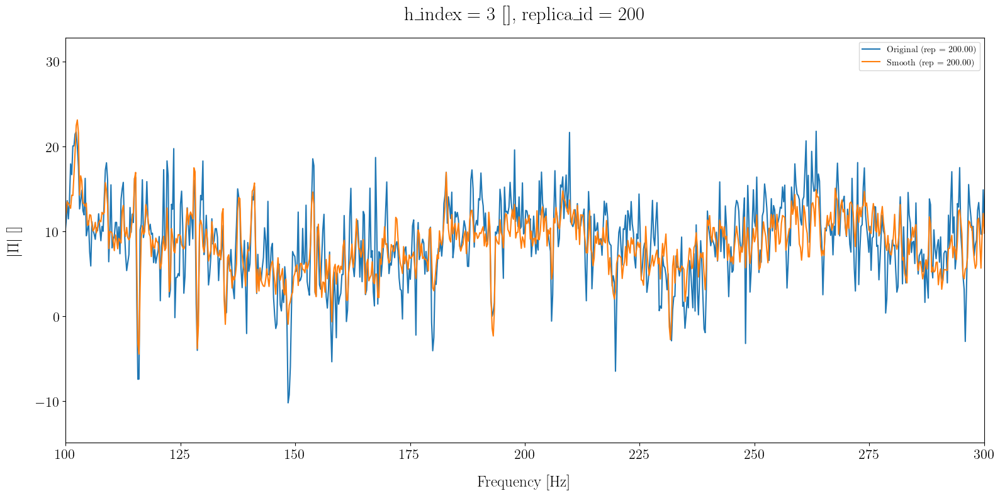

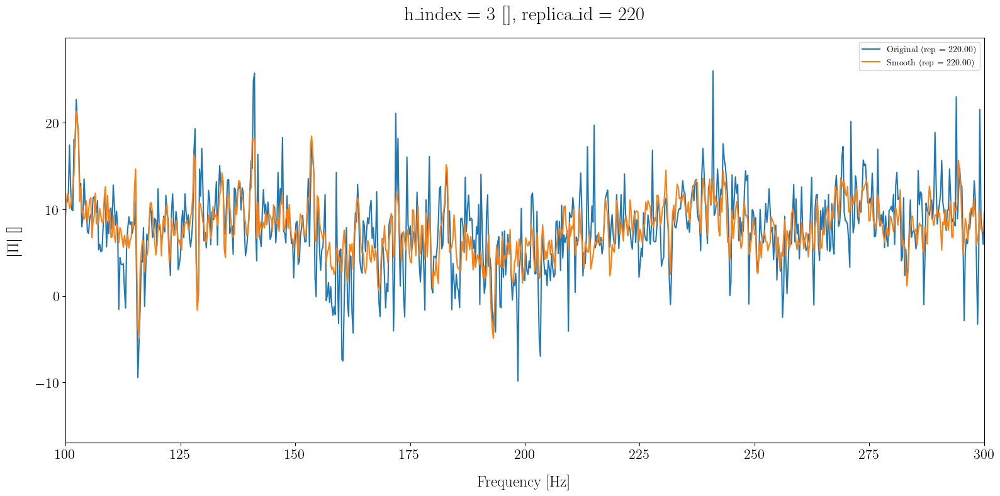

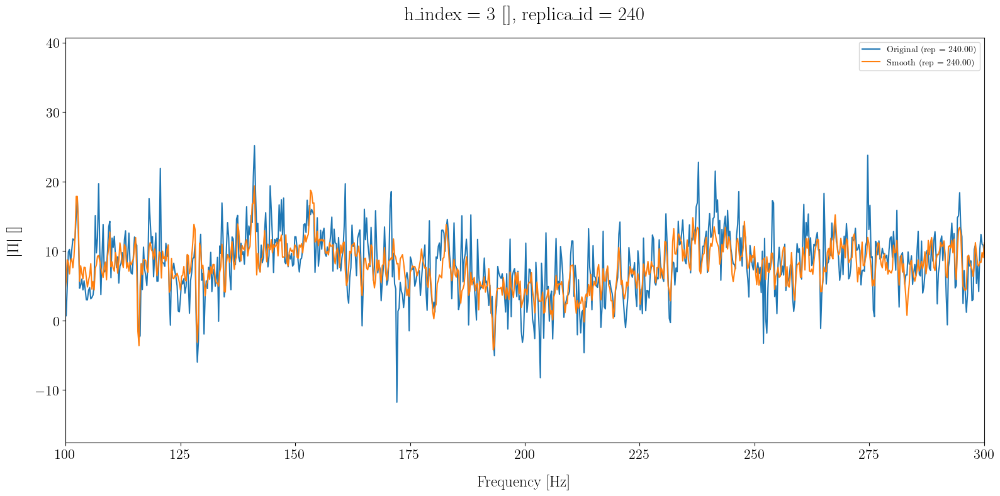

Selected window I size:  n_I = 25 samples
Number of available segments I : Q = 566


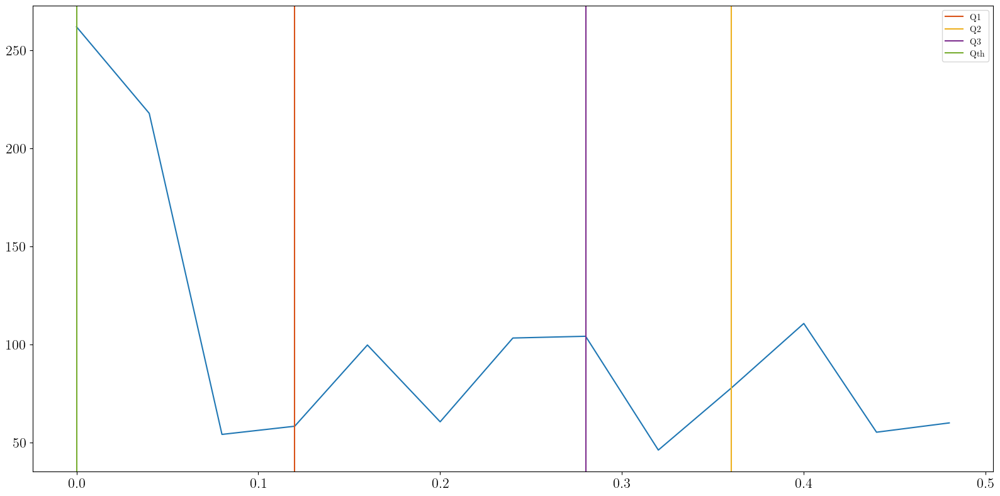

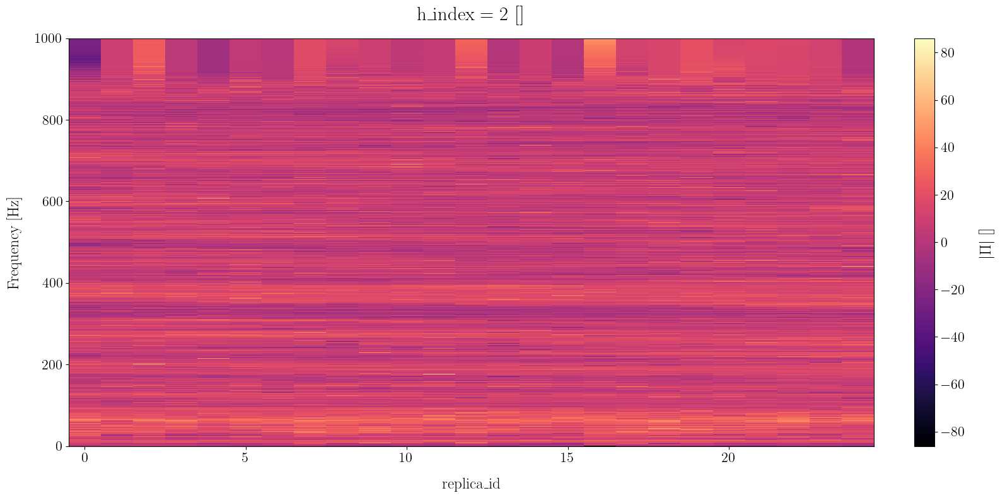

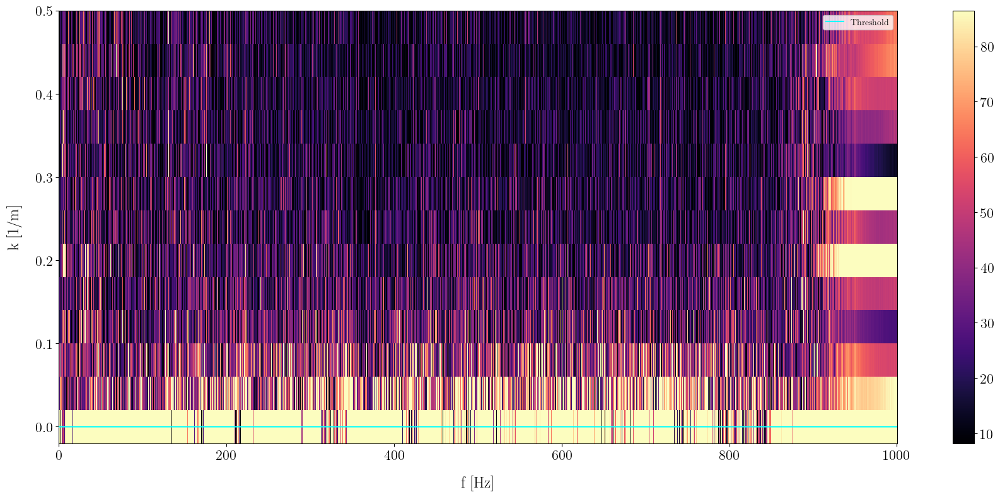

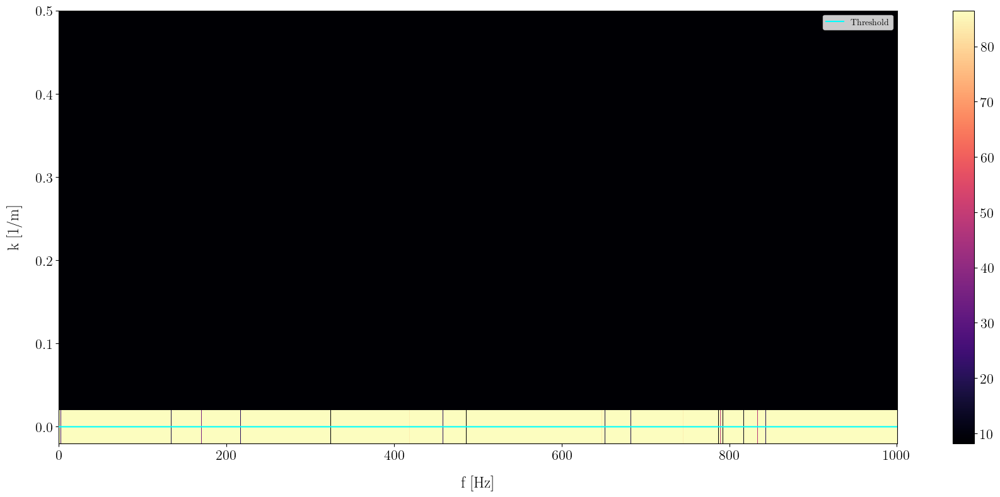

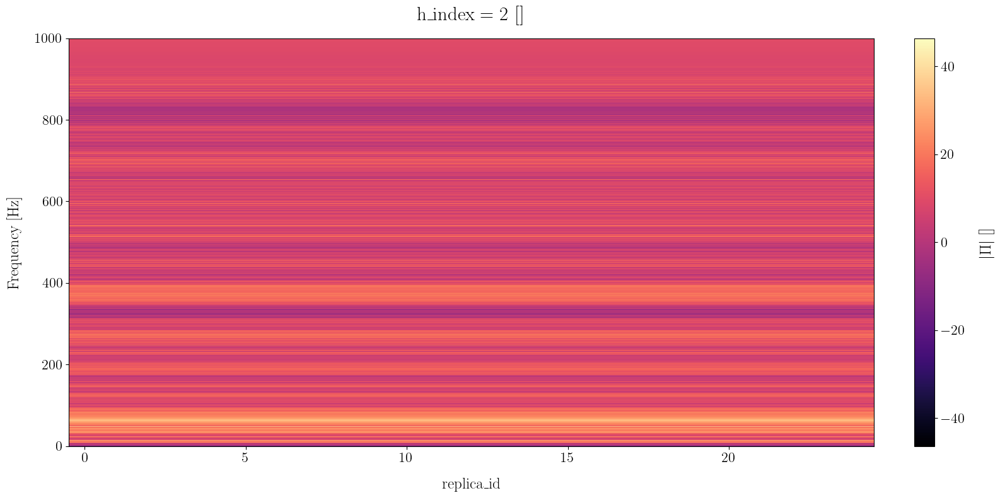

...

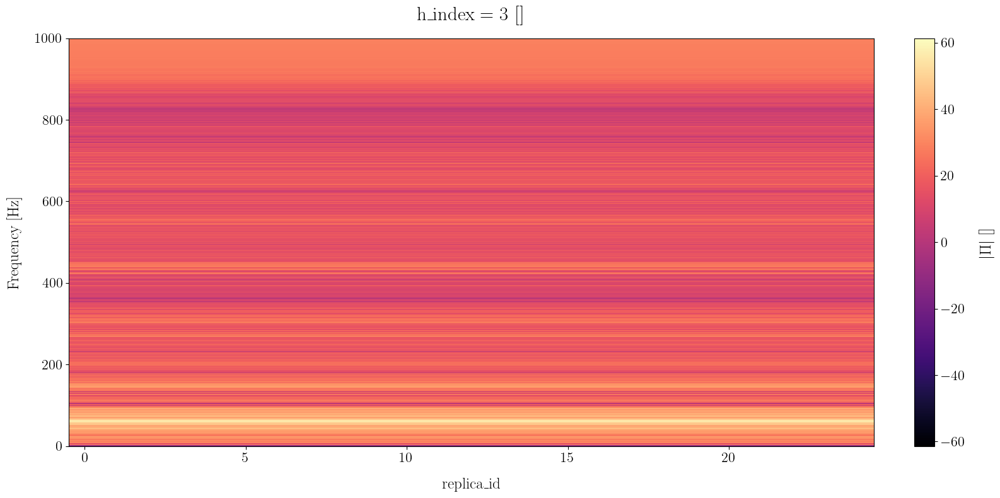

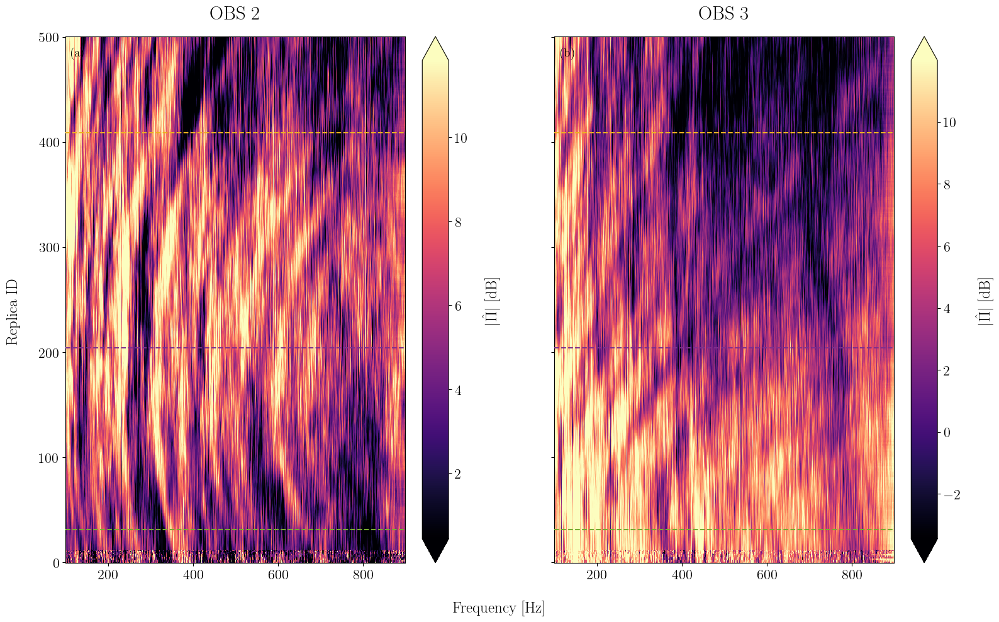

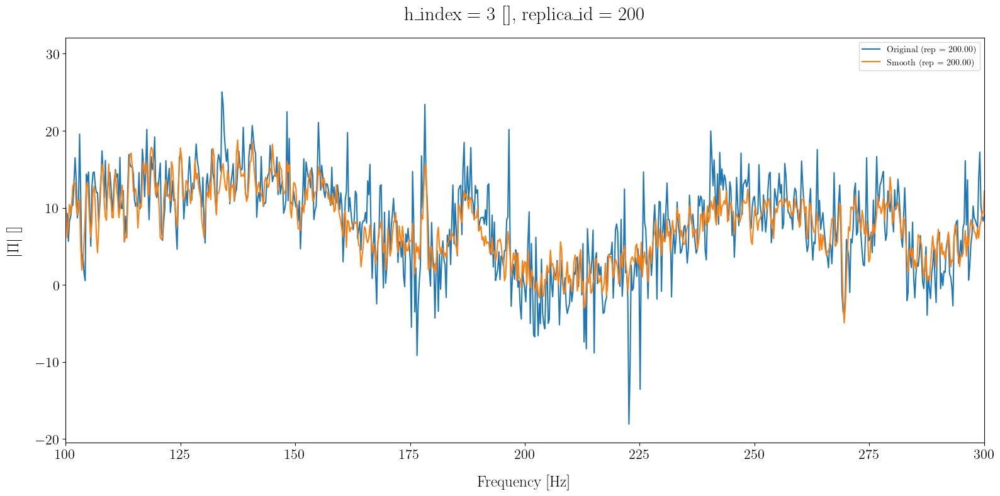

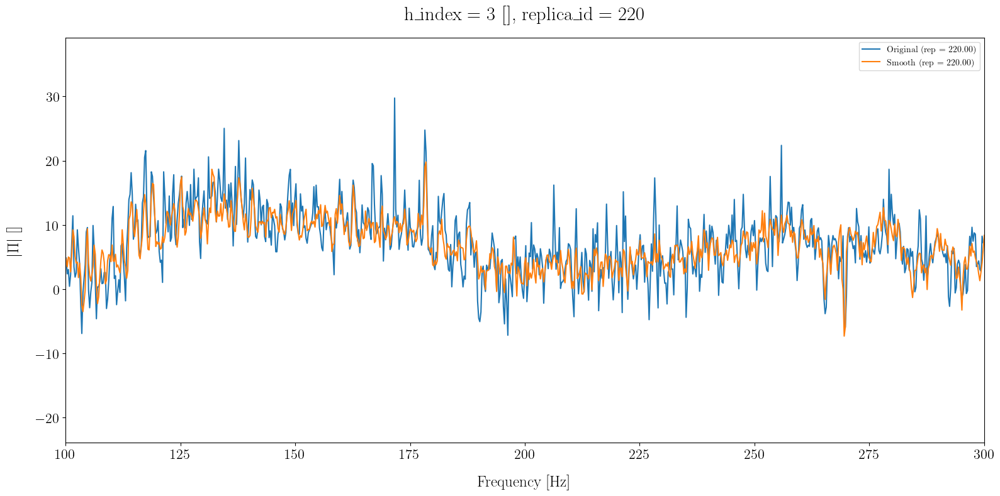

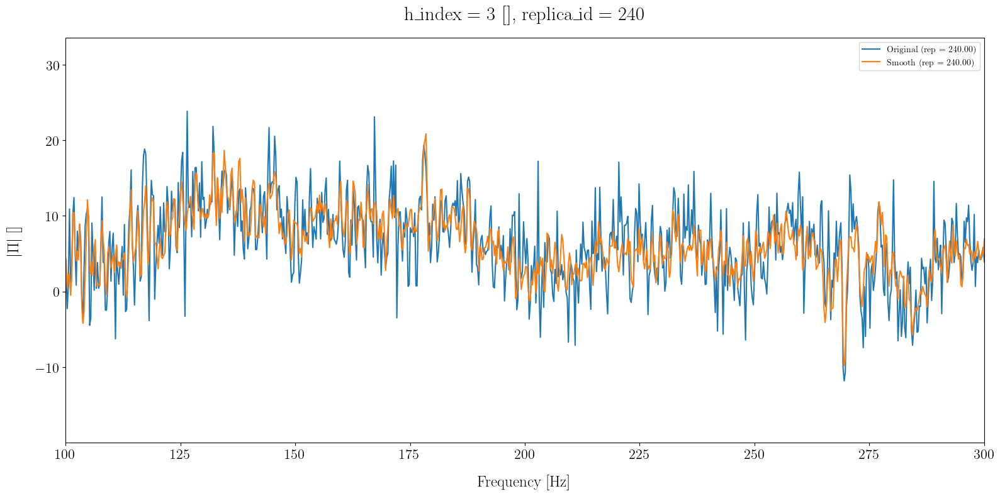

In [26]:
compute_bootstrap = False
P = 12
root_ = (
    r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data"
)

fpath_event_smooth = os.path.join(root_, "event", f"event_{ds_event.id}_smooth_P{P}.nc")
fpath_library_smooth = os.path.join(root_, "library", f"library_{ds_lib.id}_smooth_P{P}.nc")

if load_precomputed:
    ds_event_smooth = xr.open_dataset(fpath_event_smooth)
    ds_lib_smooth = xr.open_dataset(fpath_library_smooth)
else:

    ds_lib_smooth = process_smooth(ds_lib, root_img=fig_folder, P=P, compute_bootstrap=compute_bootstrap)
    plt.show()
    plt.close("all")
    ds_event_smooth = process_smooth(ds_event, root_img=fig_folder, P=P, compute_bootstrap=compute_bootstrap)
    plt.show()
    plt.close("all")
    # Save smooth
    ds_event_smooth.to_netcdf(fpath_event_smooth)
    ds_lib_smooth.to_netcdf(fpath_library_smooth)

Matching with distance: hermitian_angle
Matching original datasets
Compute distance using hermitian angle distance (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


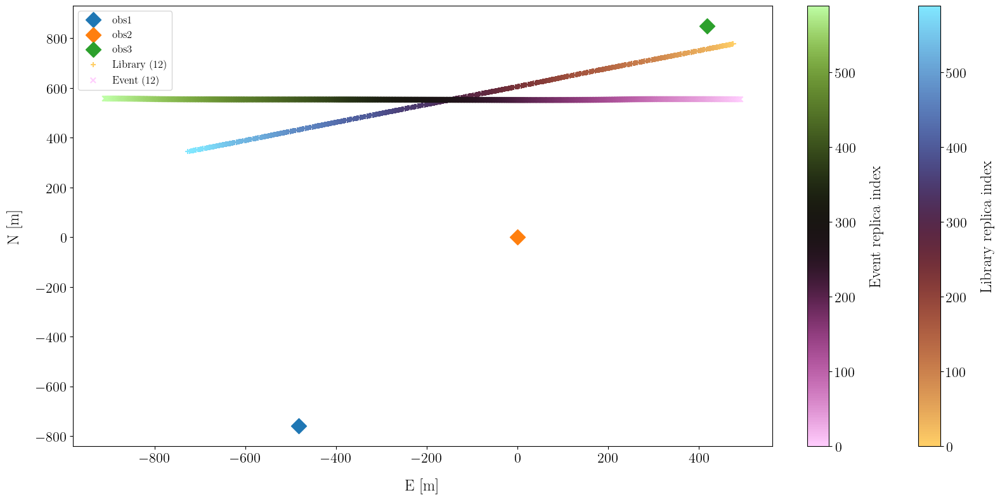

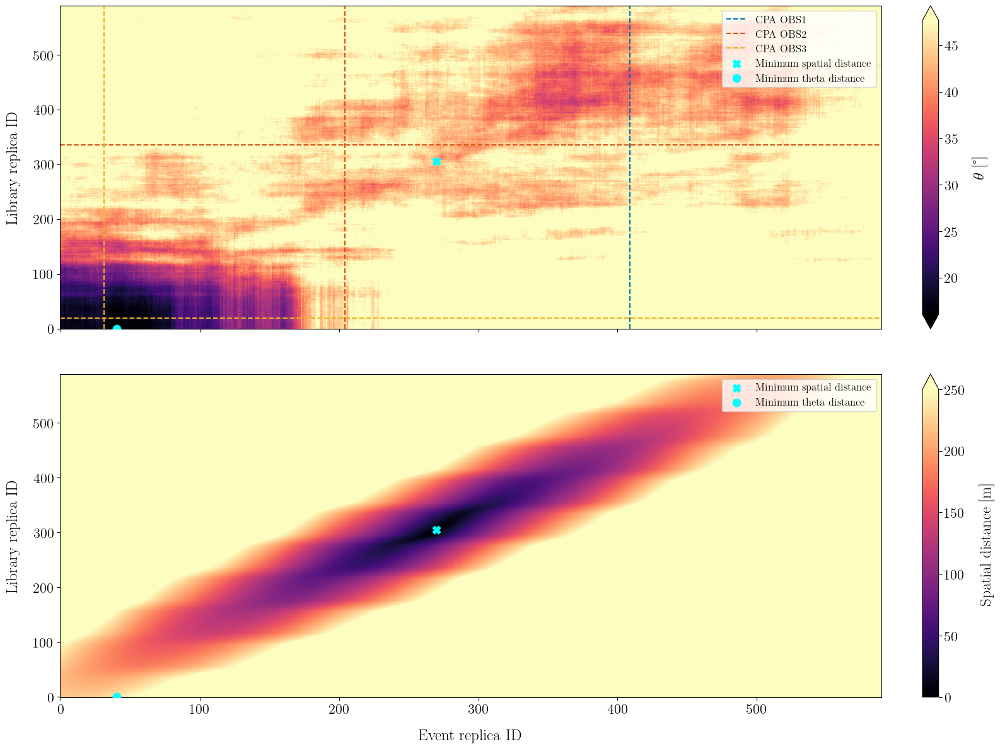

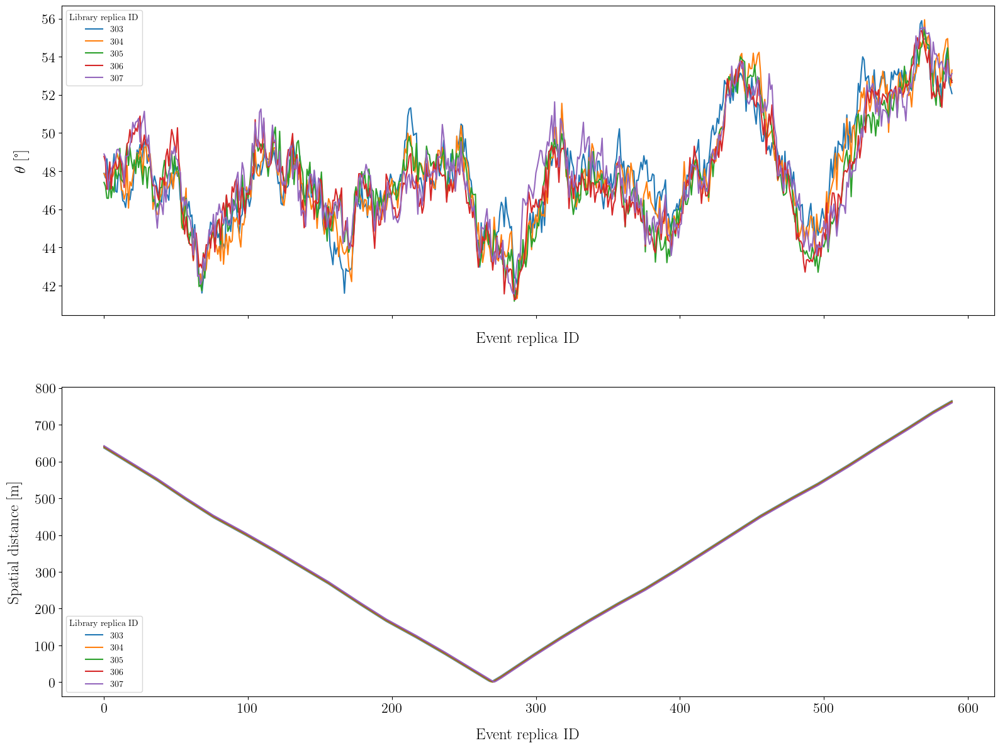

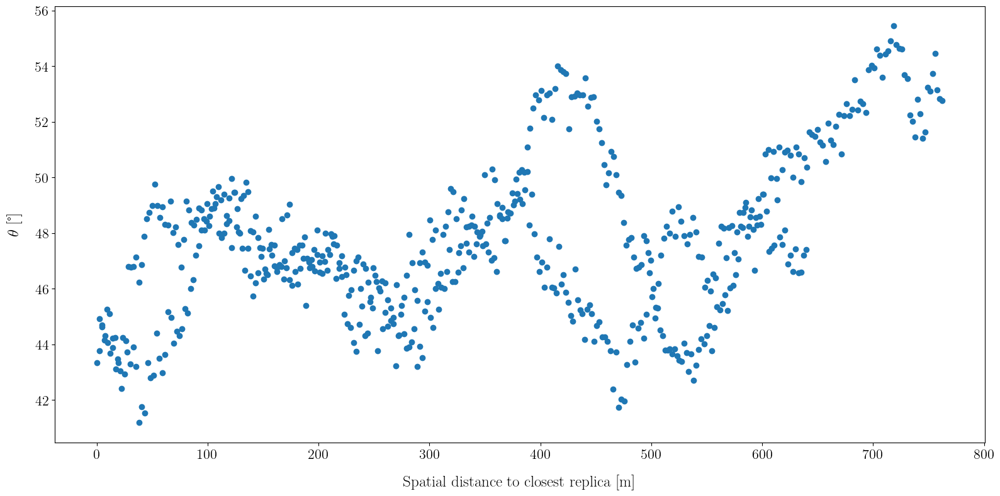

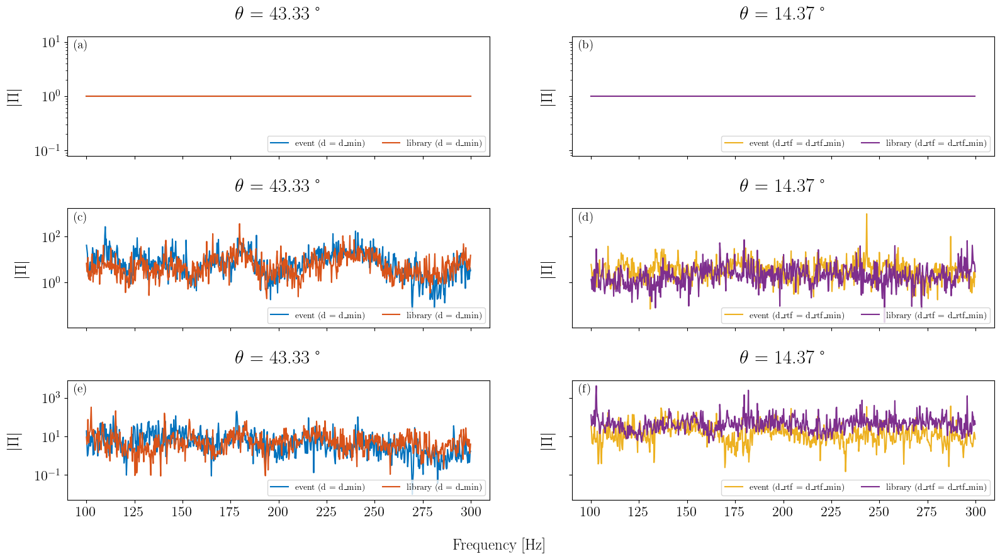

Matching smoothed datasets
Compute distance using hermitian angle distance (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


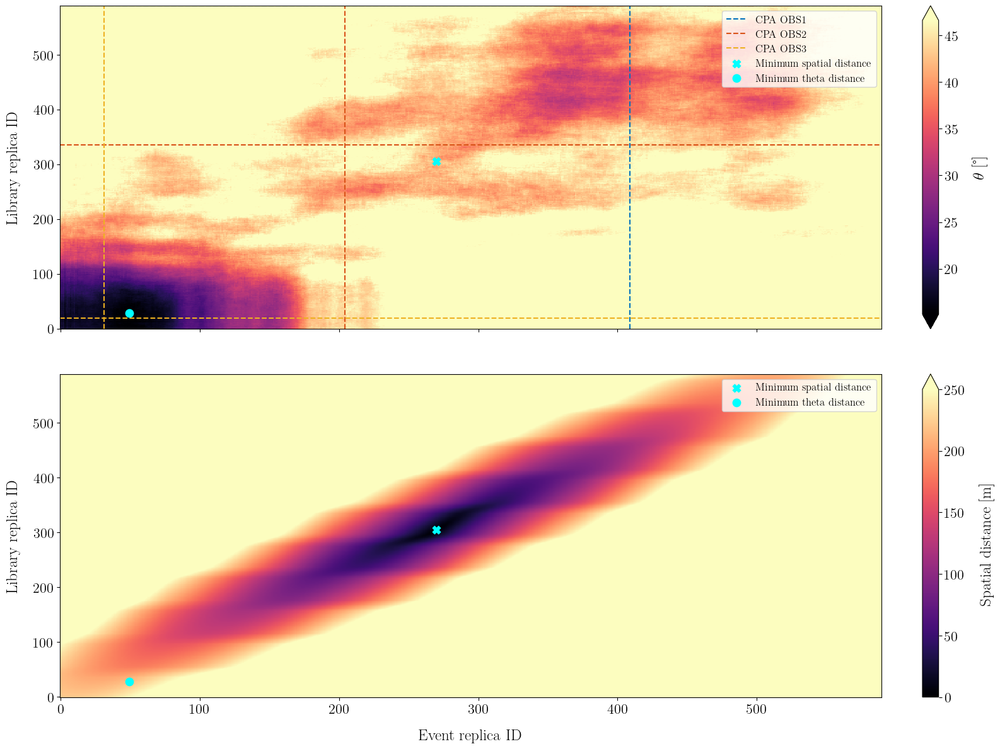

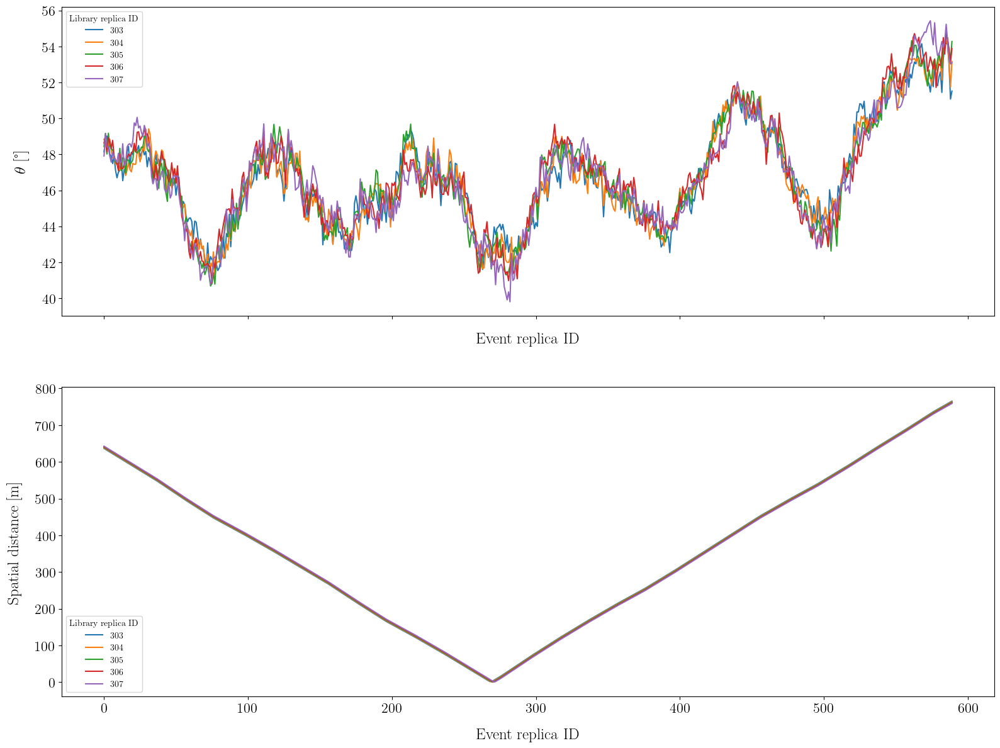

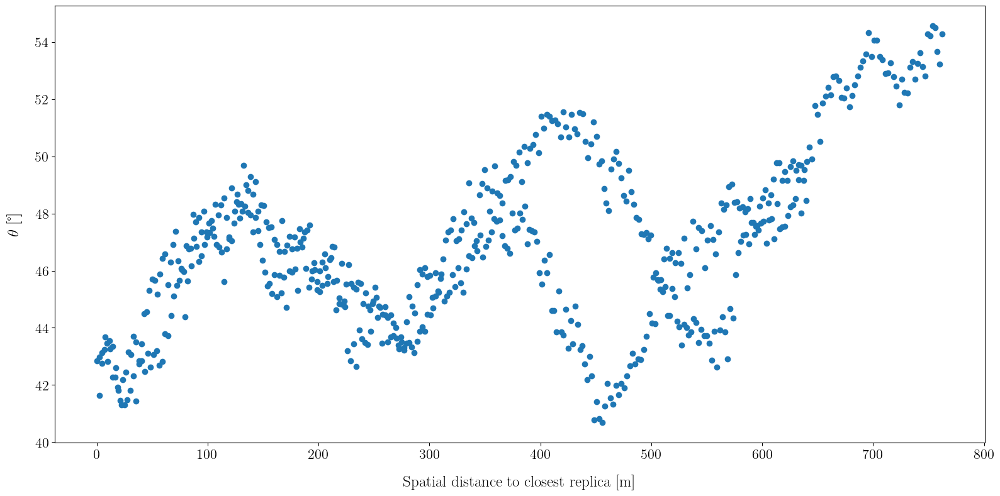

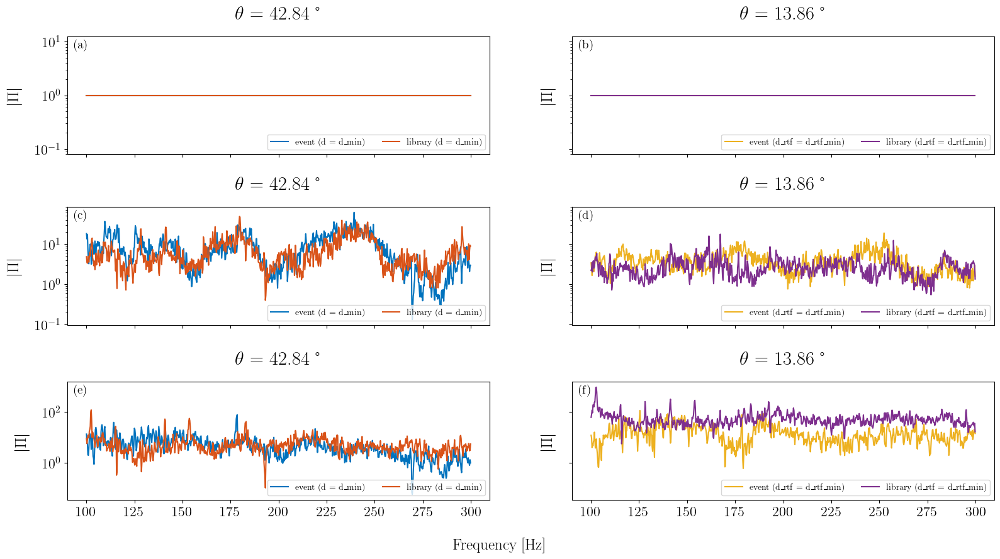

Matching with distance: hermitian_angle_module
Matching original datasets
Compute distance using euclidian angle between RTF modules (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


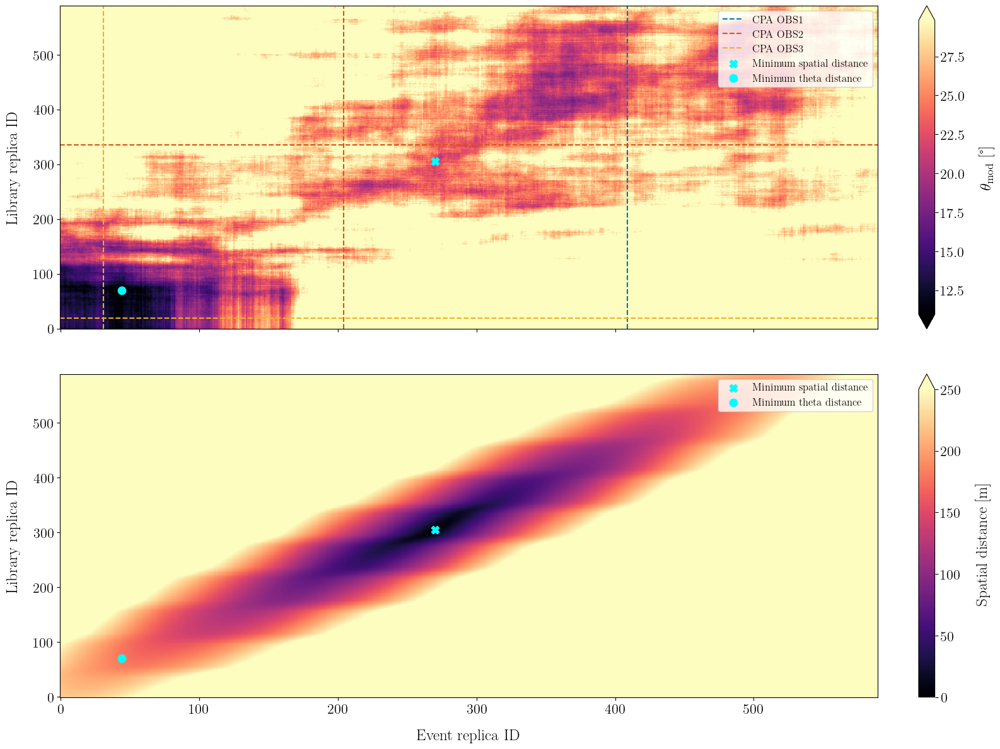

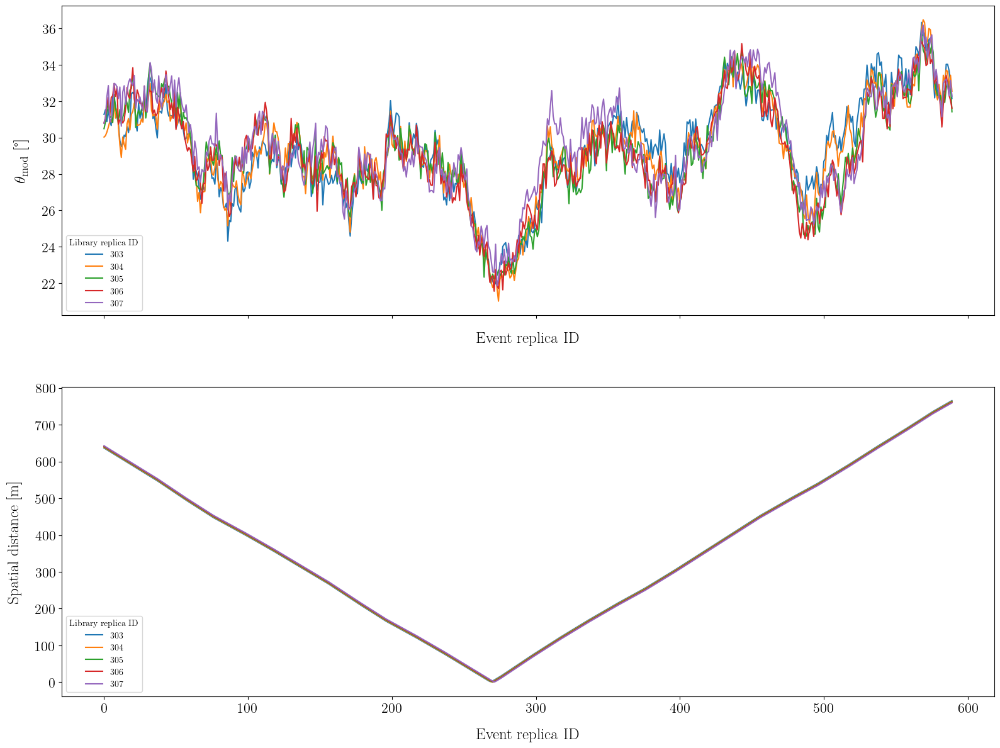

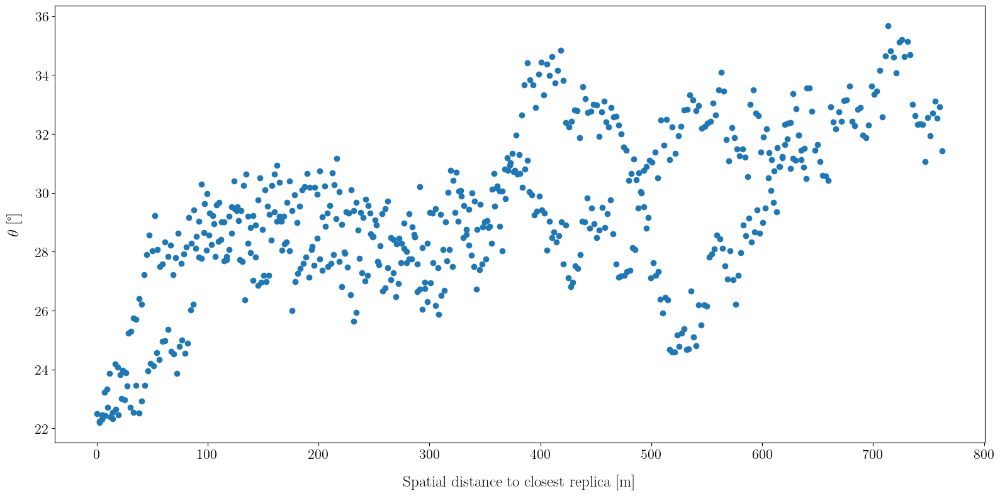

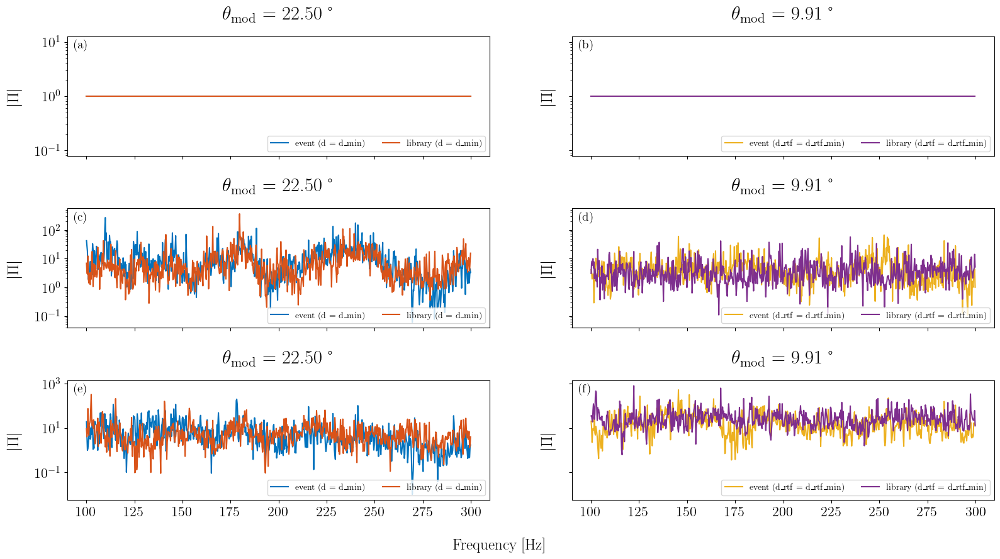

Matching smoothed datasets
Compute distance using euclidian angle between RTF modules (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


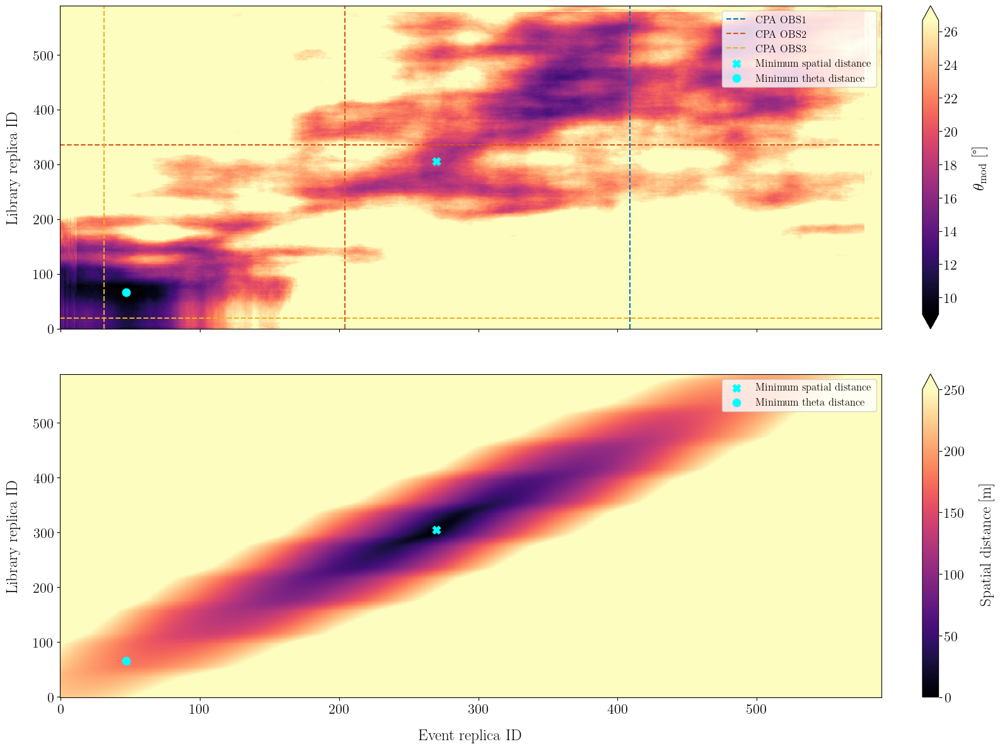

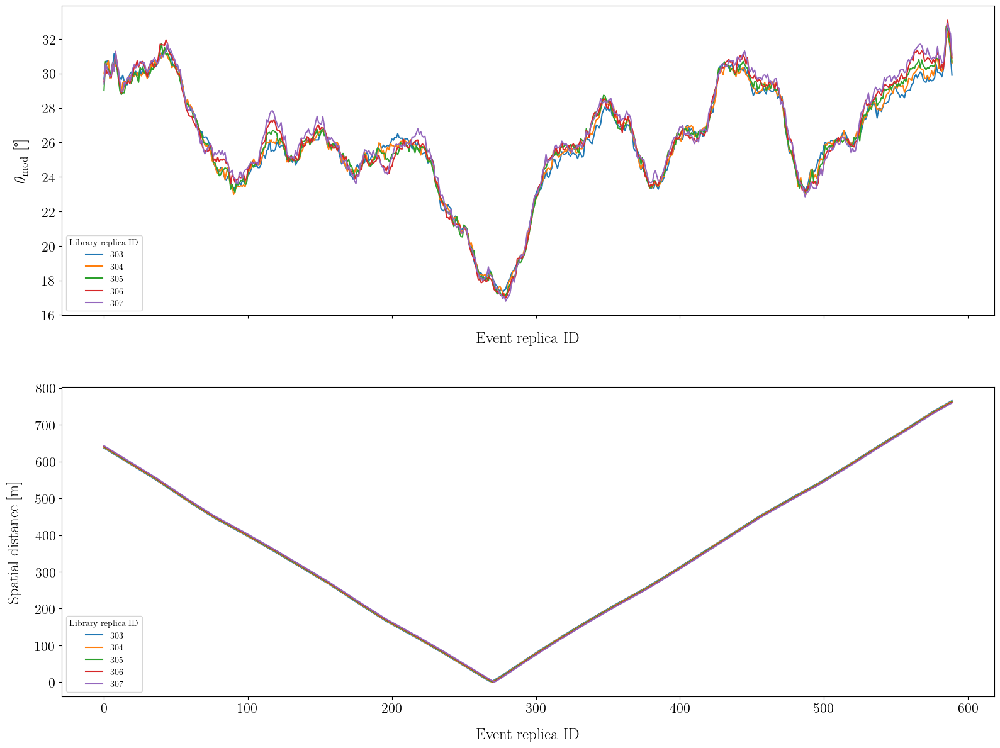

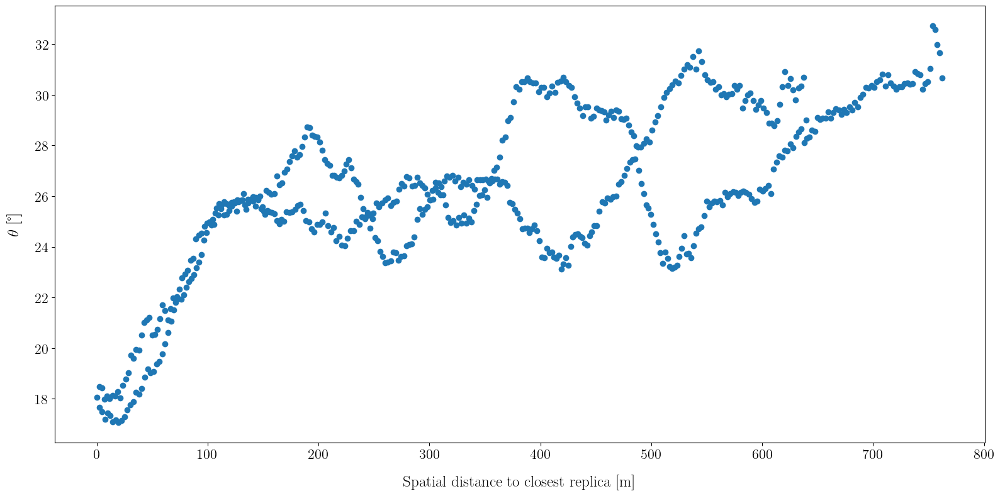

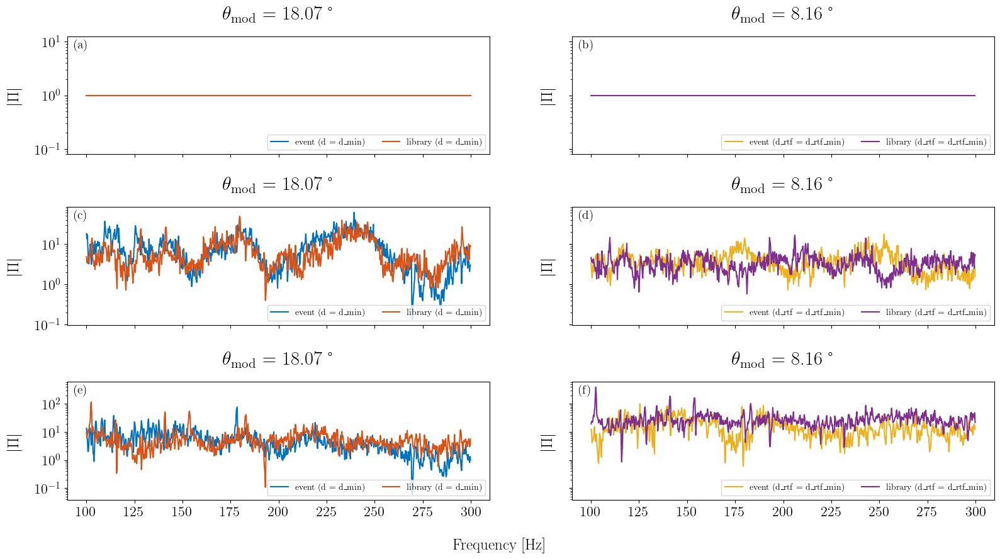

Matching with distance: hermitian_angle_along_freq
Matching original datasets
Compute distance using hermitian angle distance along frequency axis (in C^Nf)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


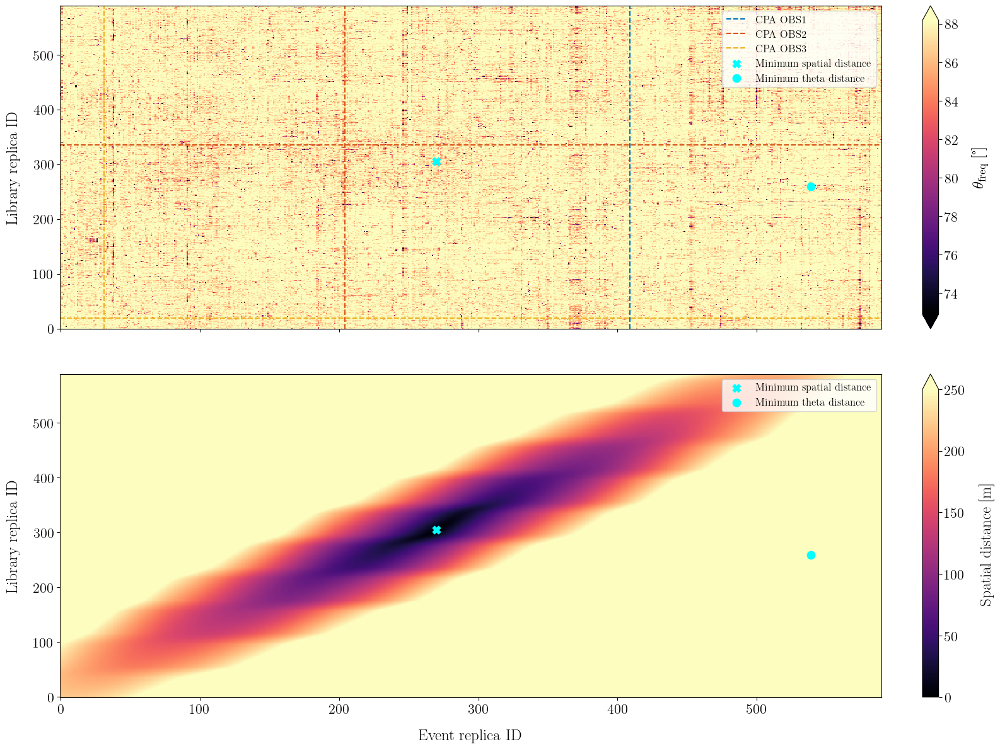

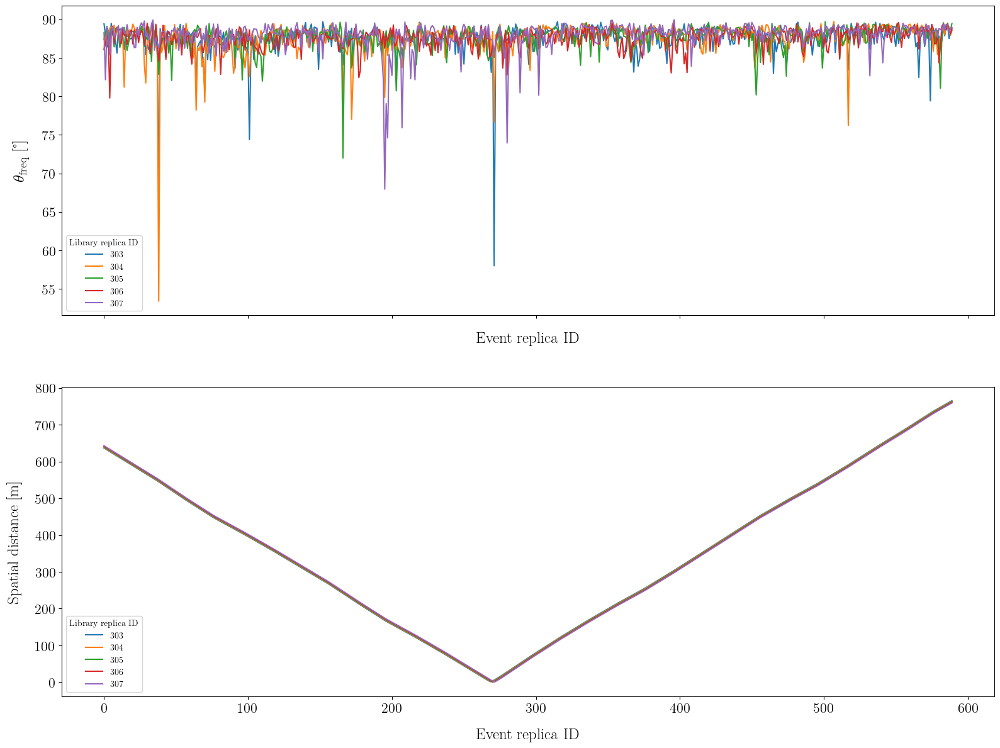

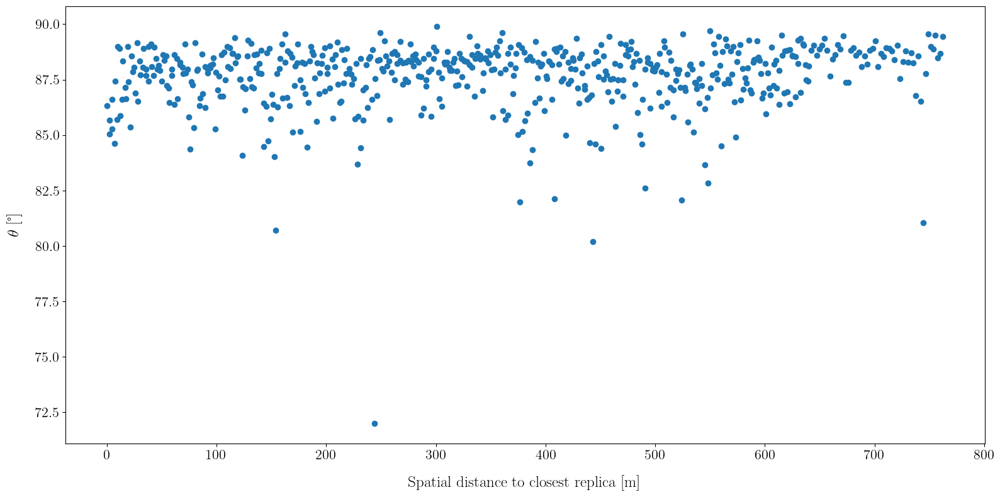

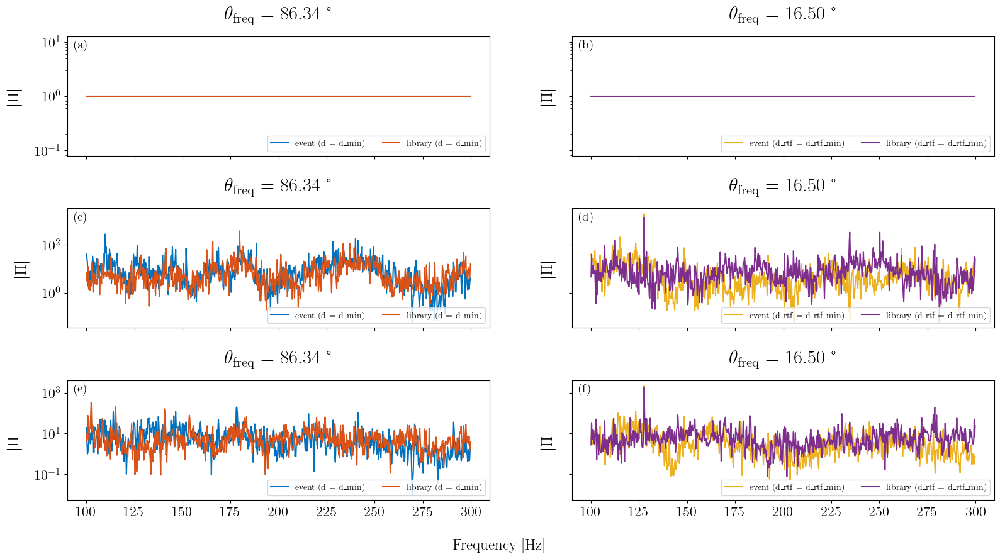

Matching smoothed datasets
Compute distance using hermitian angle distance along frequency axis (in C^Nf)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


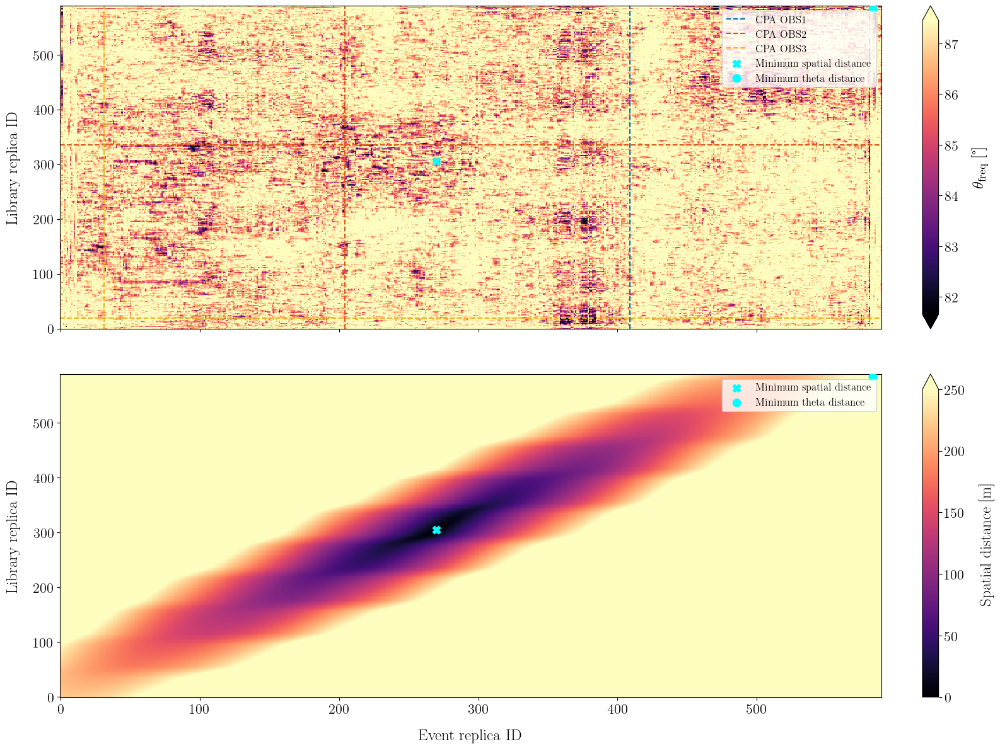

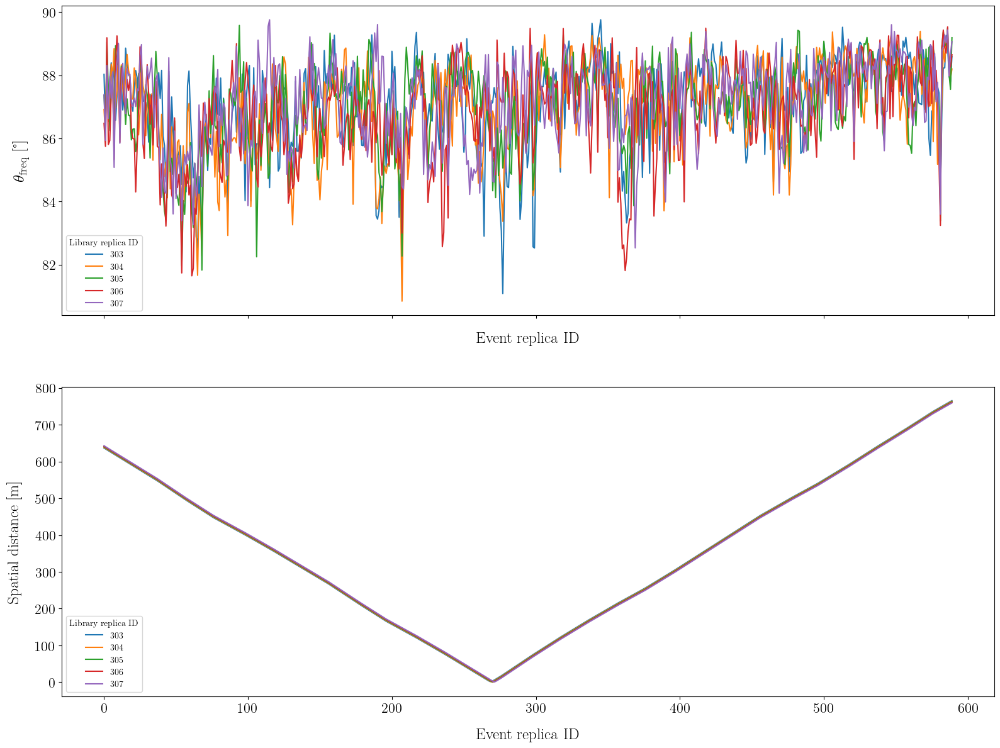

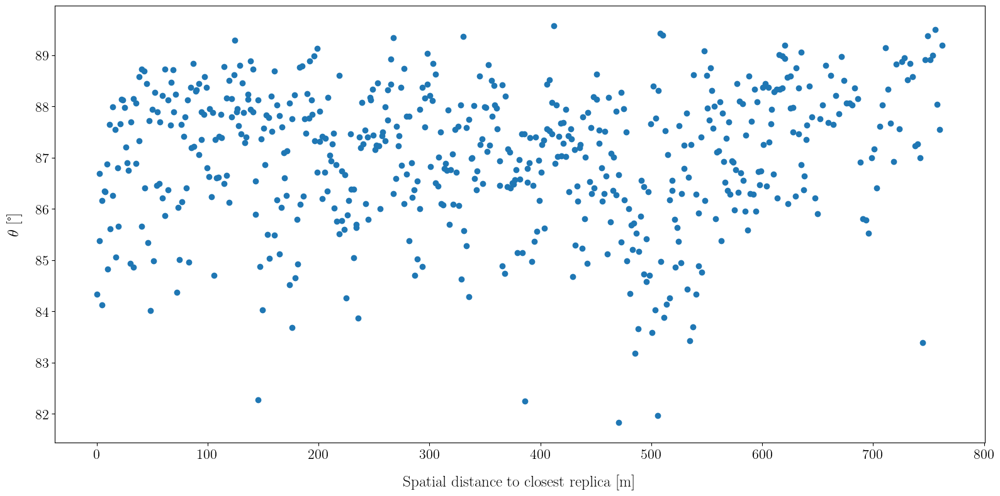

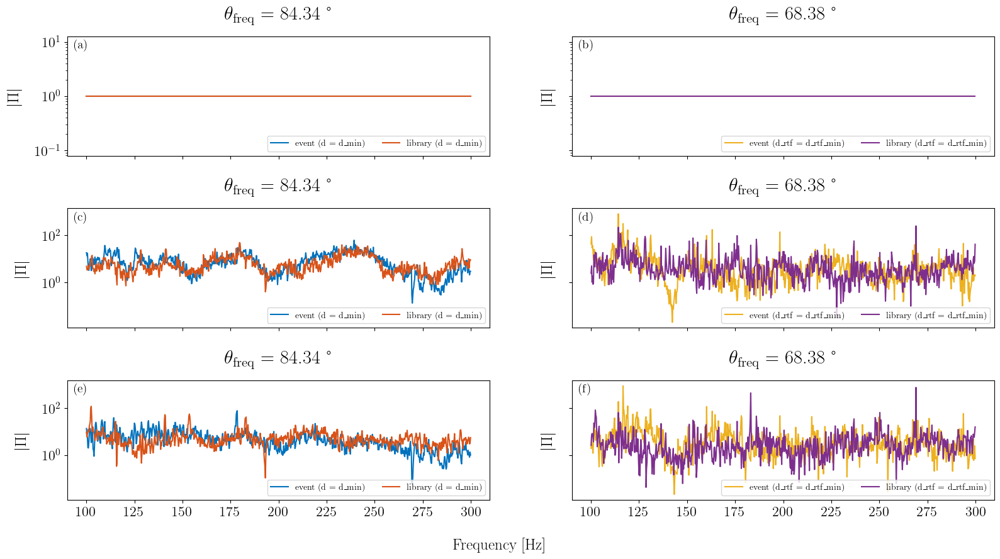

Matching with distance: norm_L1
Matching original datasets
Compute L1 norm (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


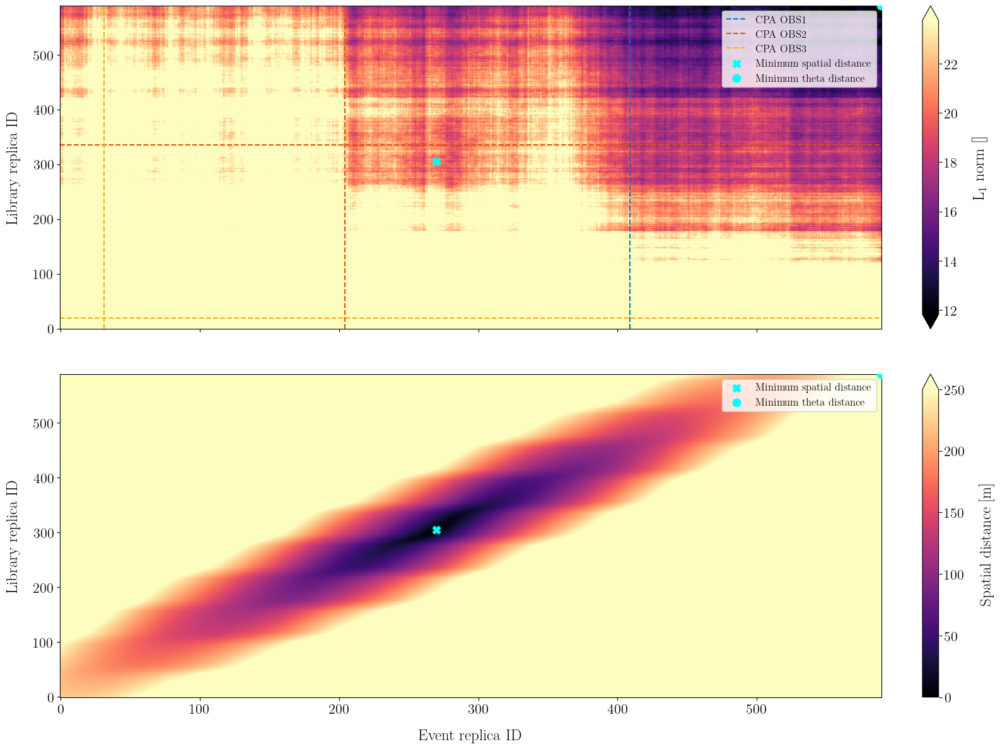

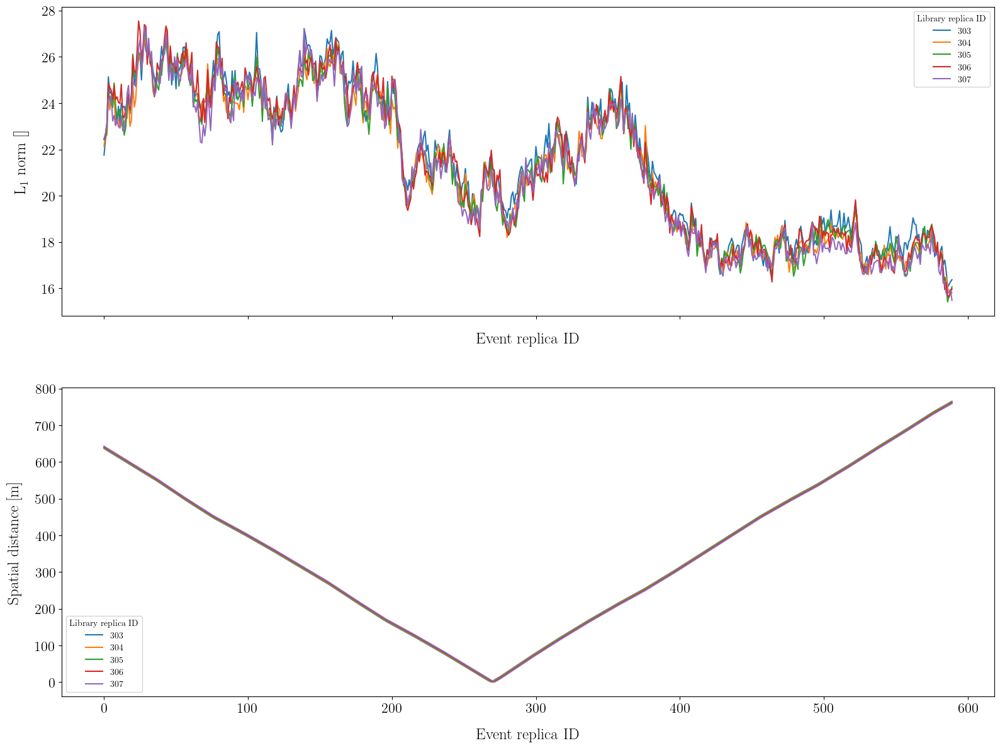

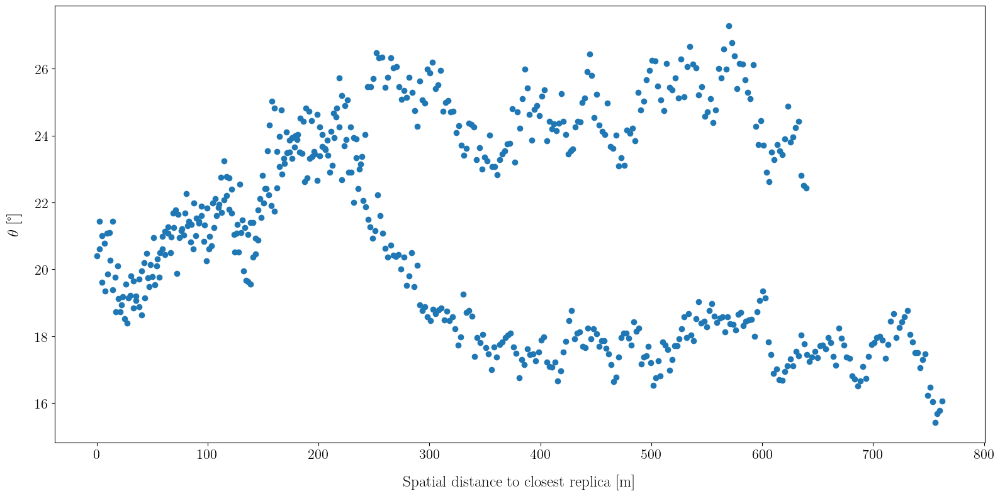

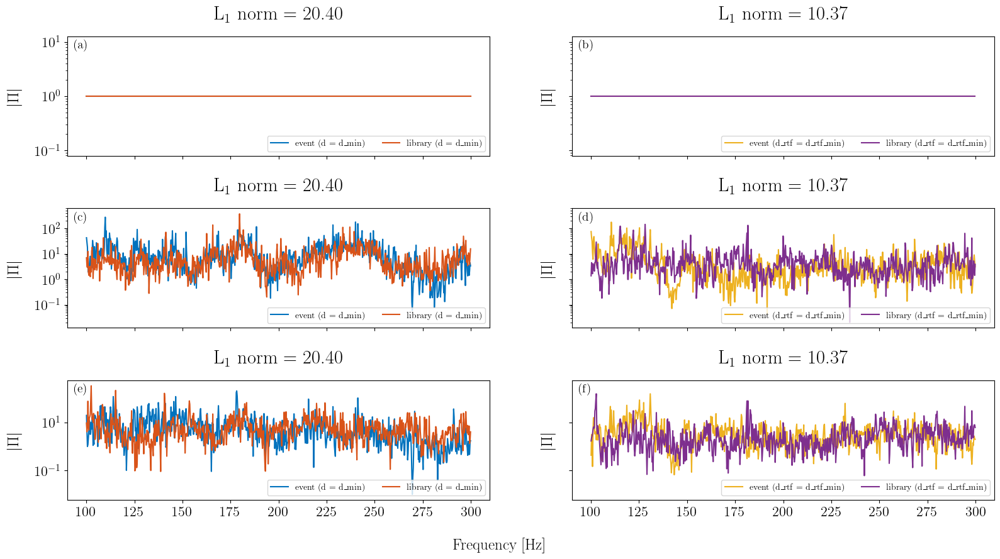

Matching smoothed datasets
Compute L1 norm (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


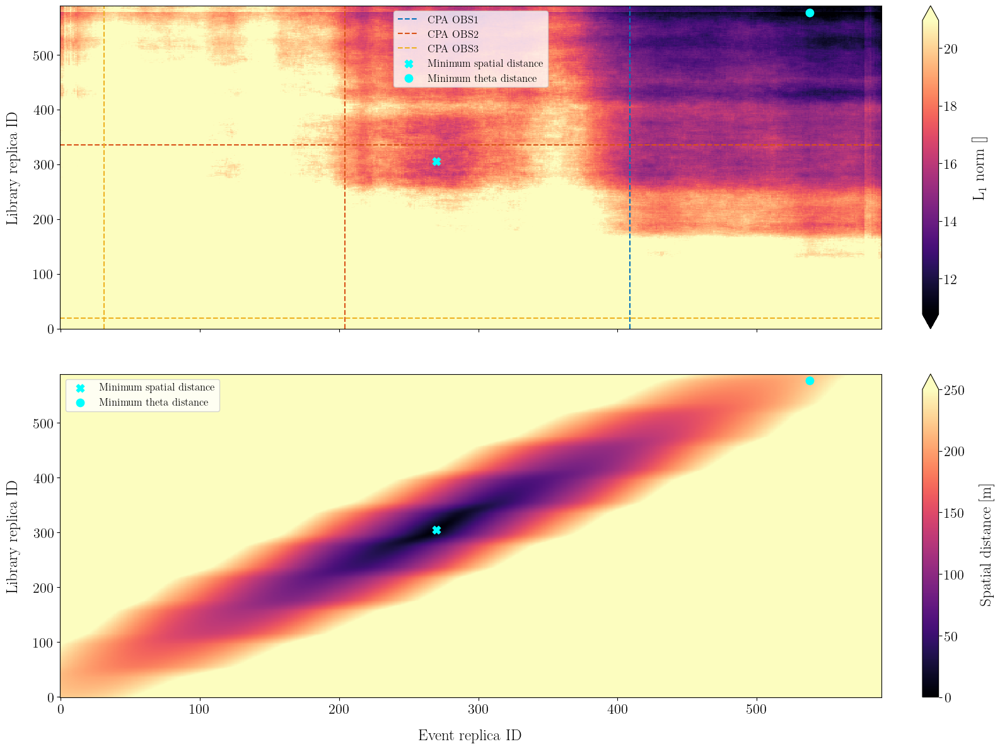

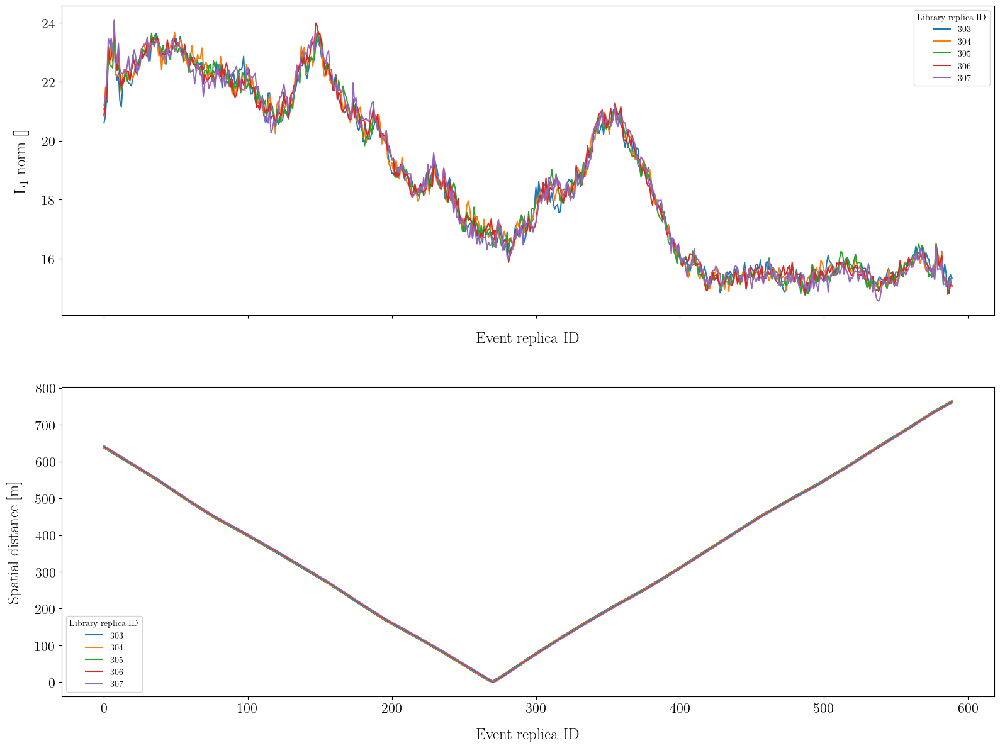

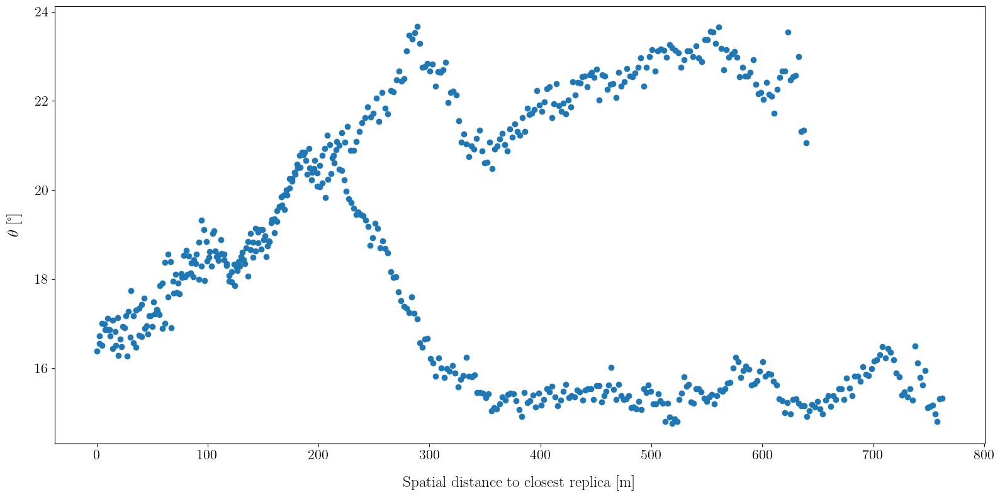

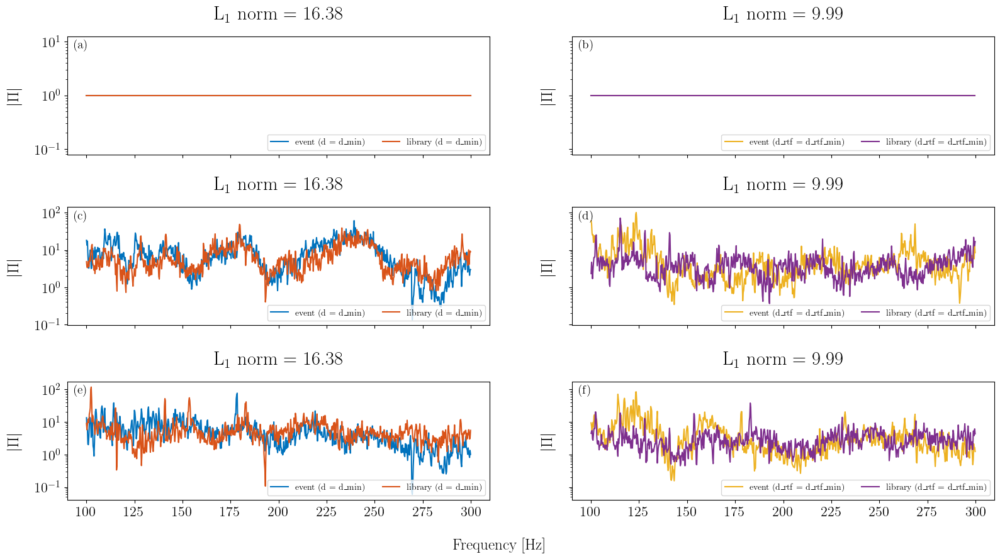

Matching with distance: norm_L1_module
Matching original datasets
Compute L1 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


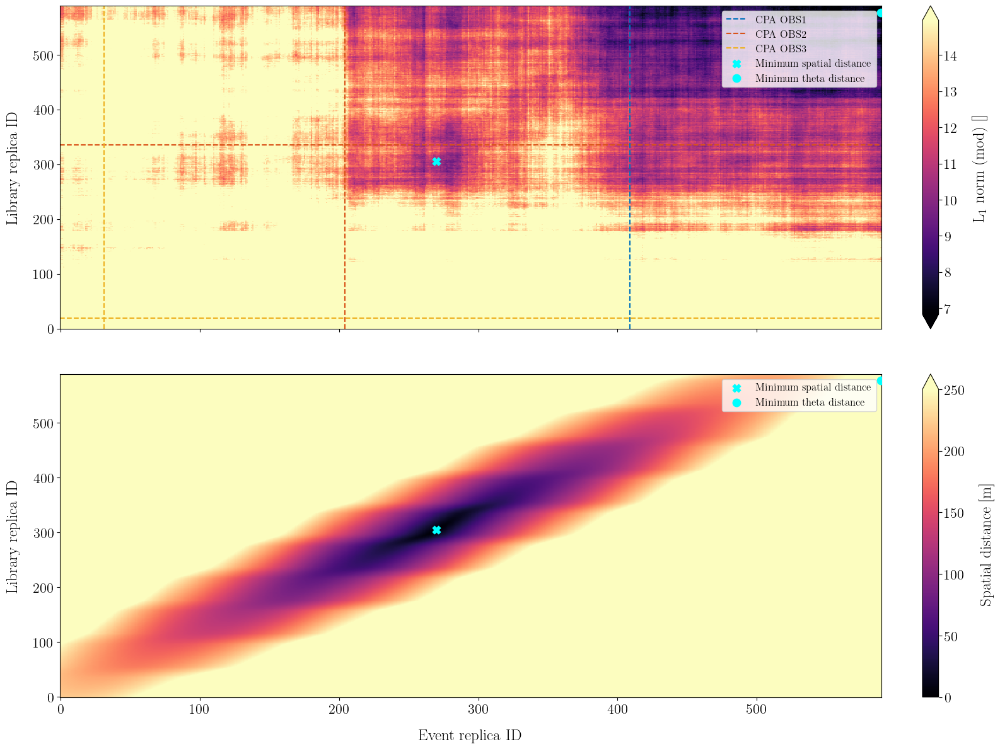

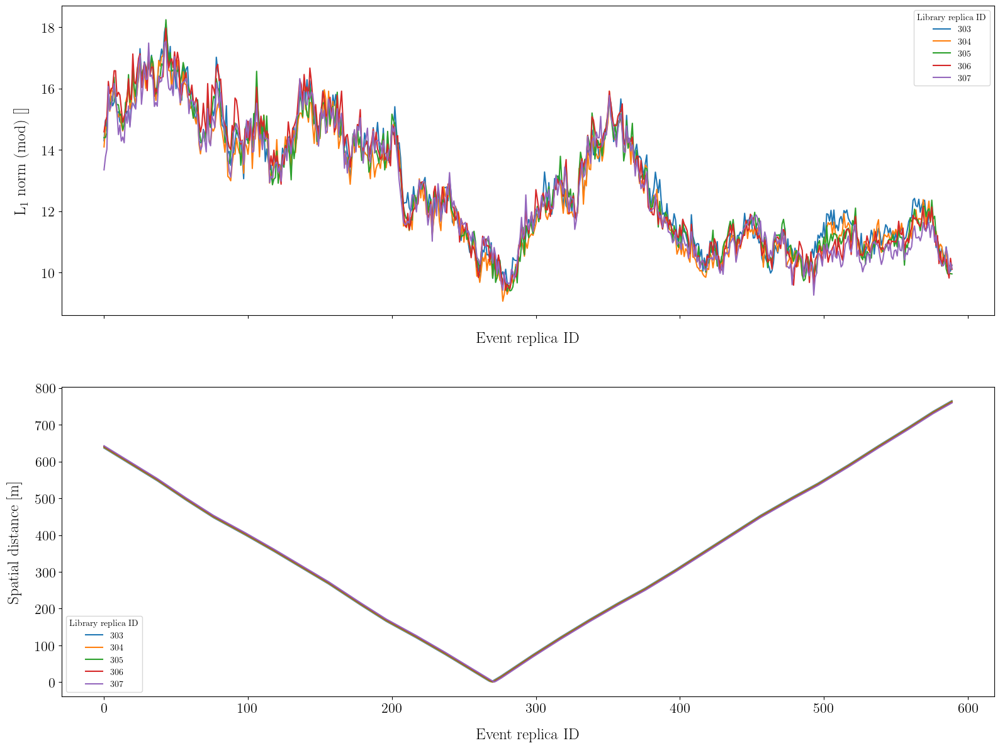

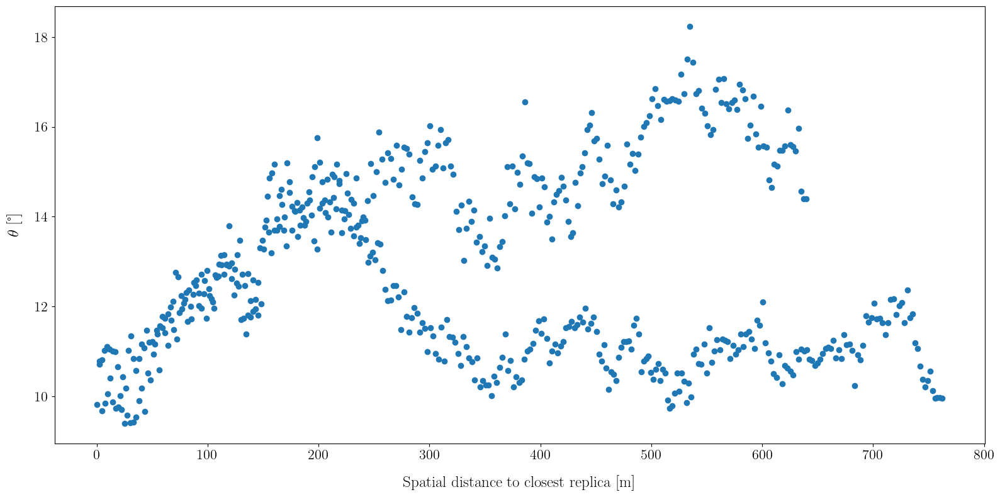

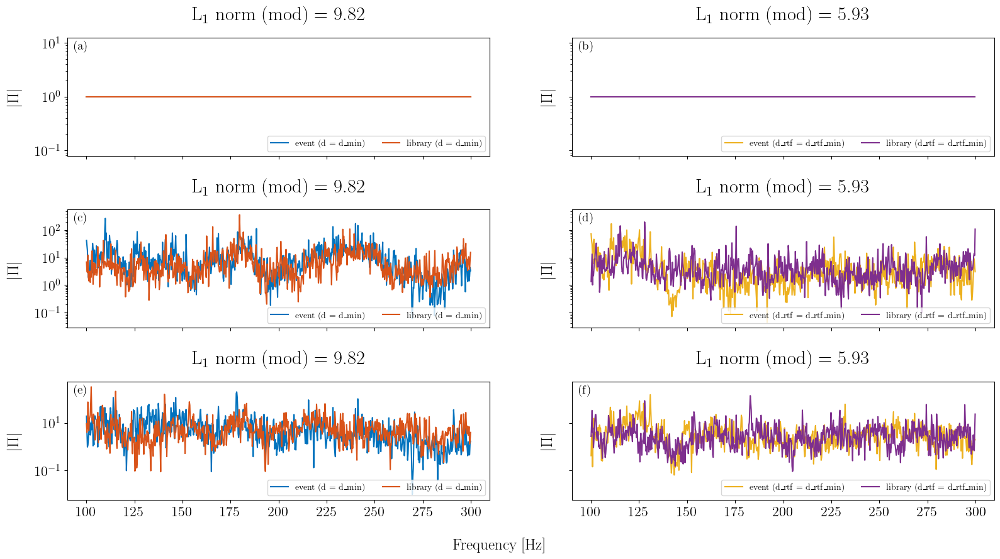

Matching smoothed datasets
Compute L1 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


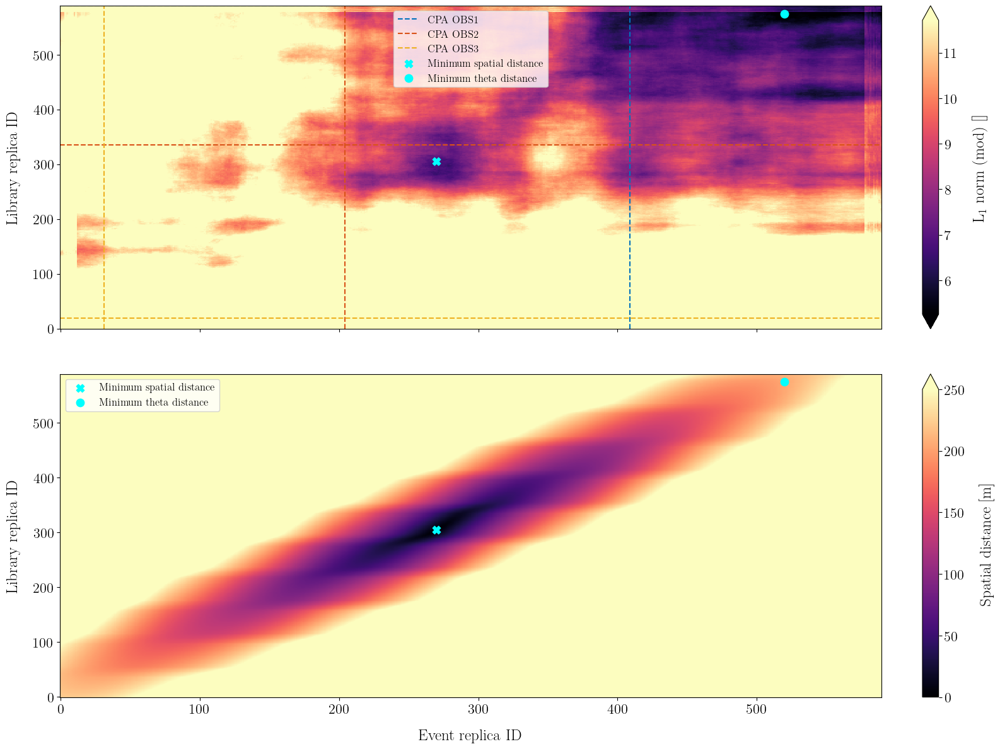

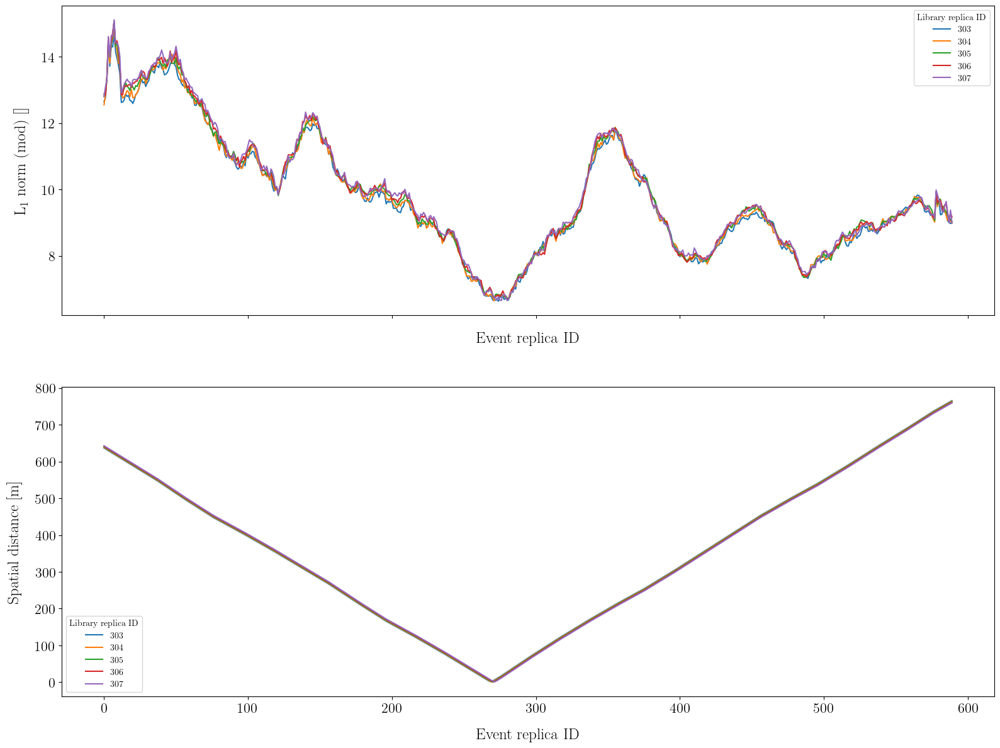

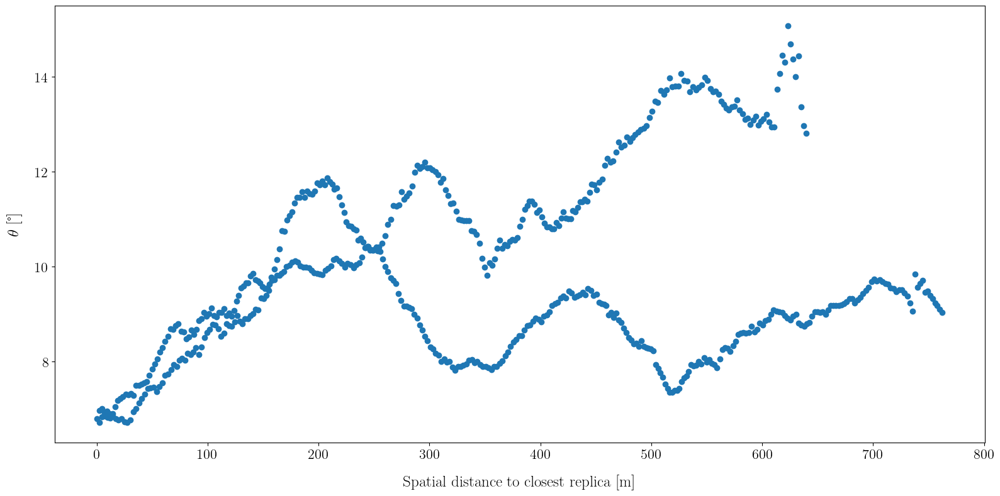

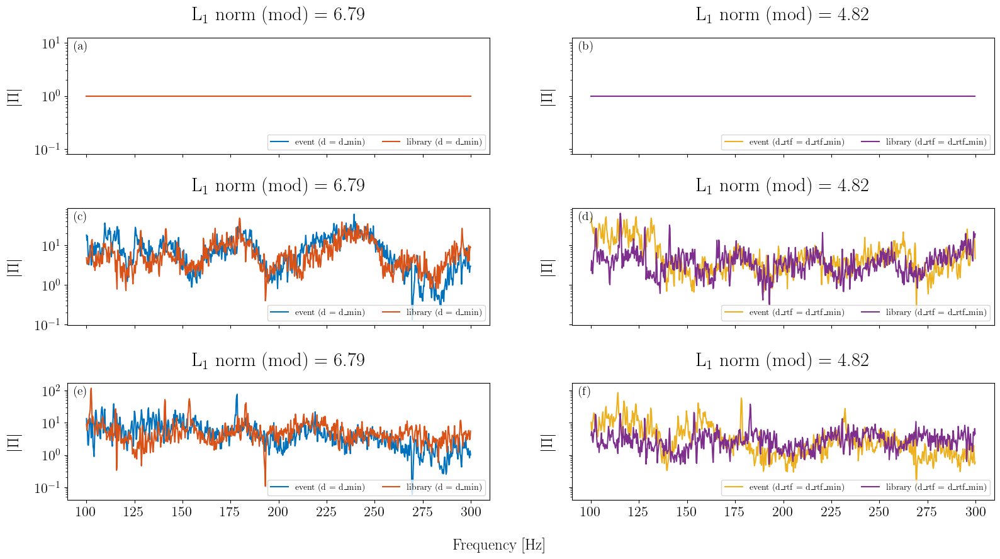

Matching with distance: norm_L2
Matching original datasets
Compute L2 norm (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


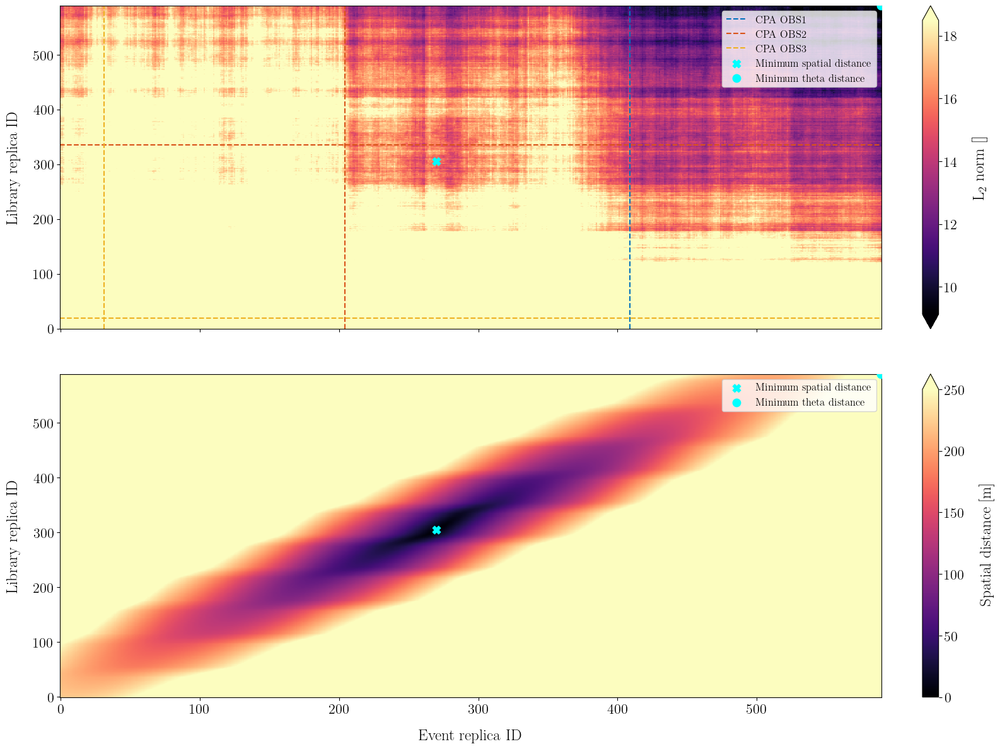

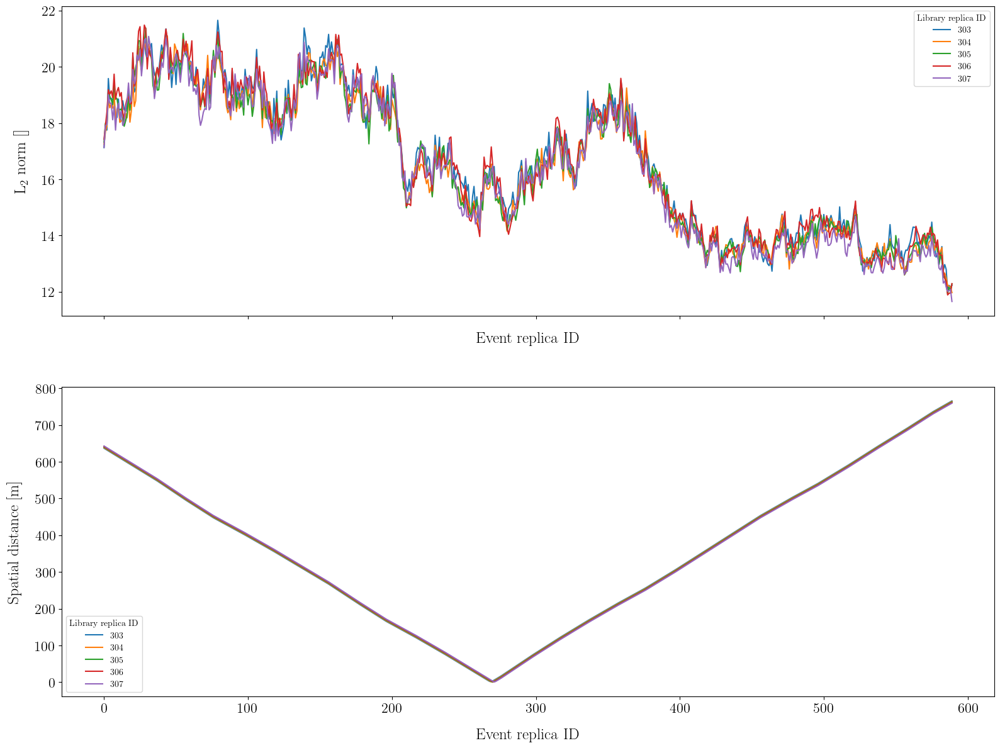

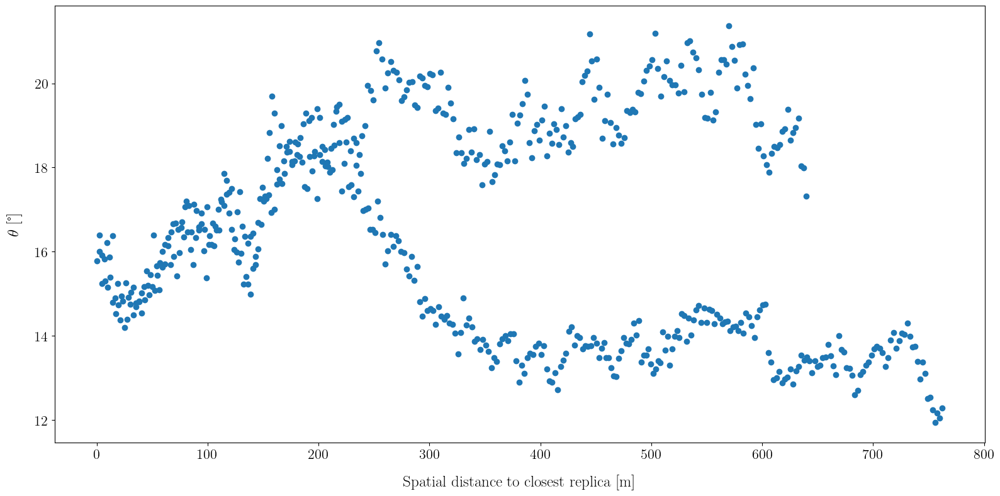

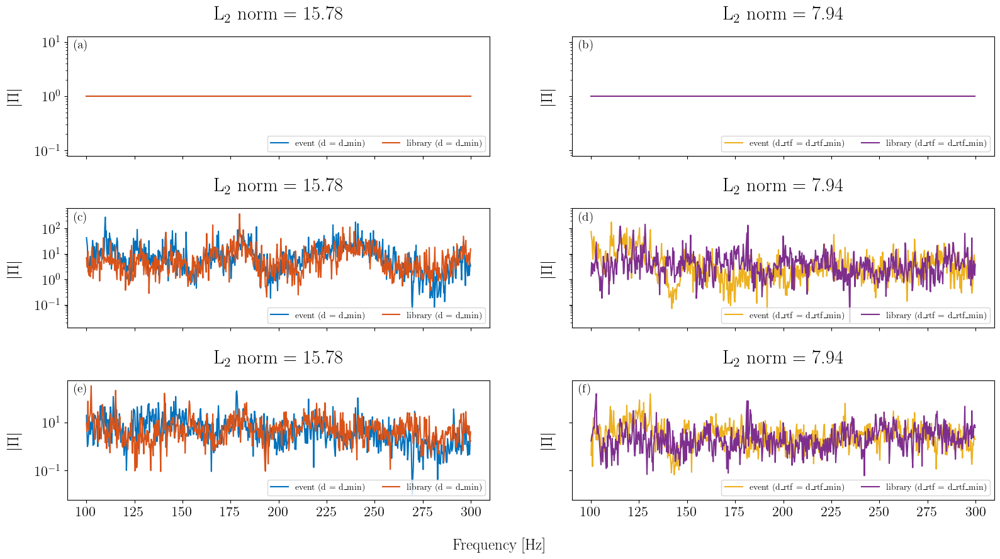

Matching smoothed datasets
Compute L2 norm (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


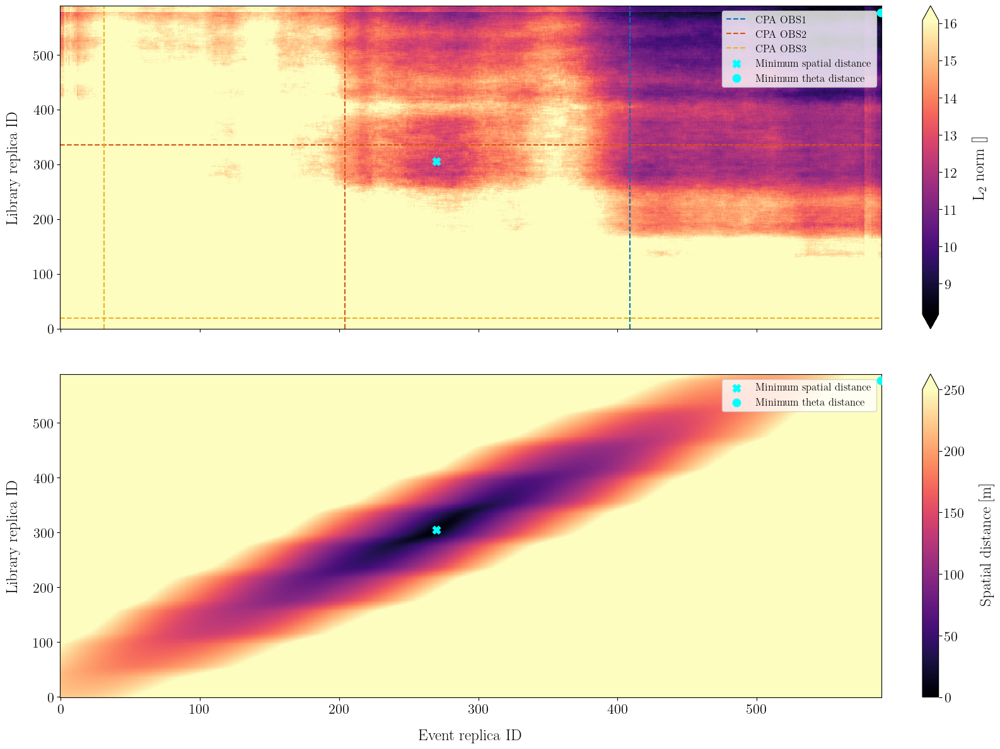

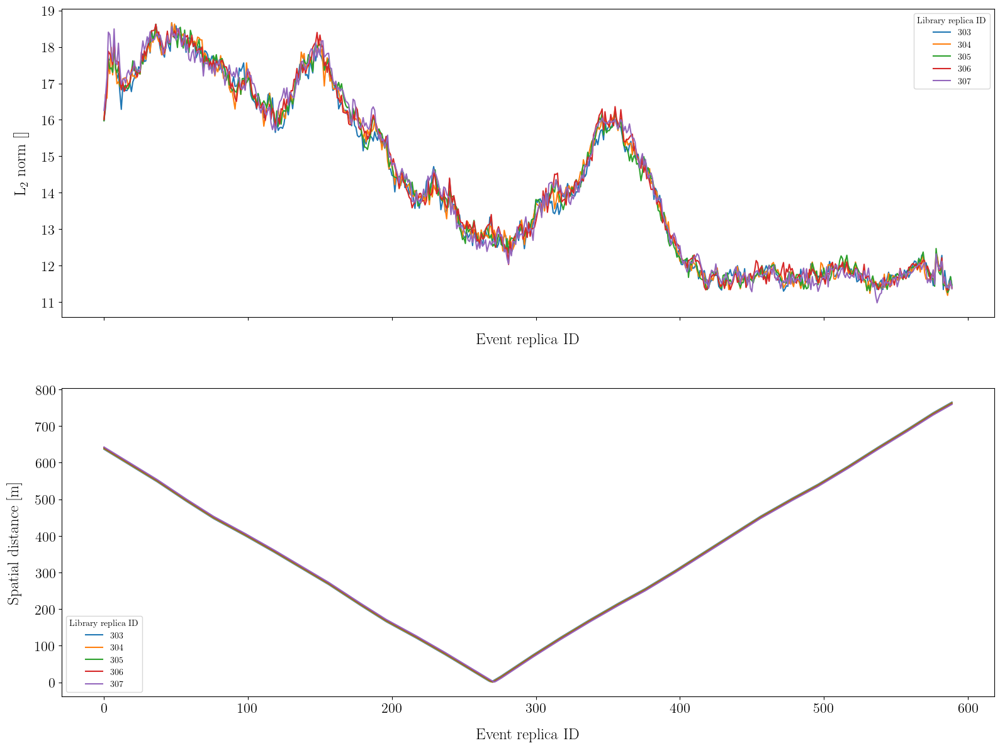

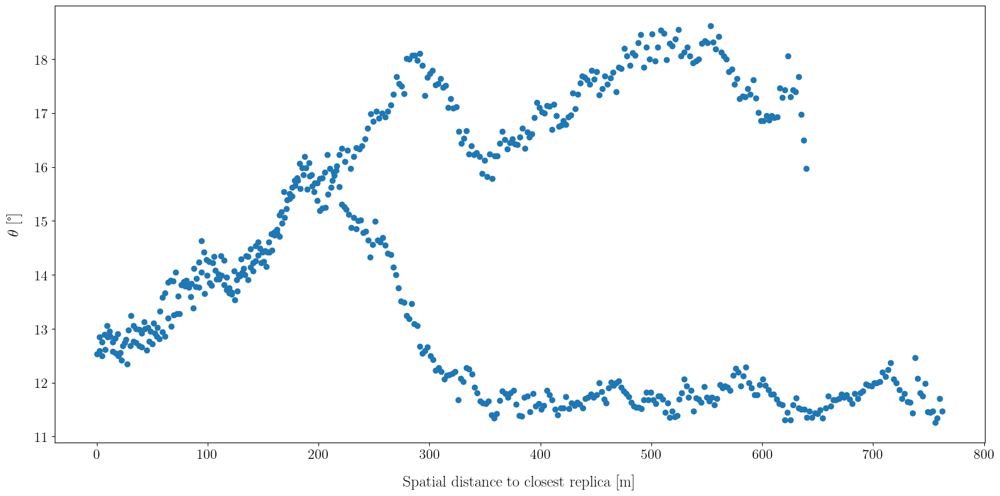

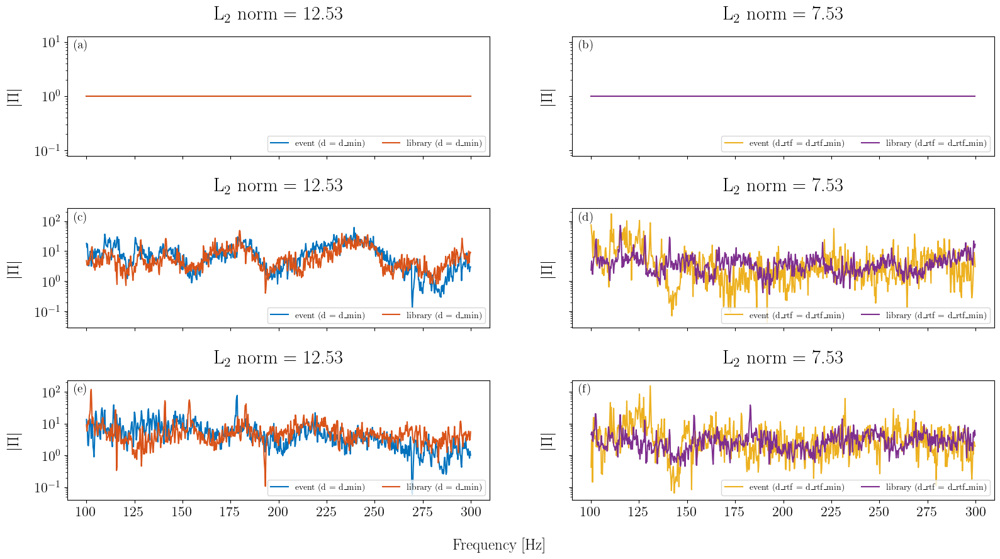

Matching with distance: norm_L2_module
Matching original datasets
Compute L2 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


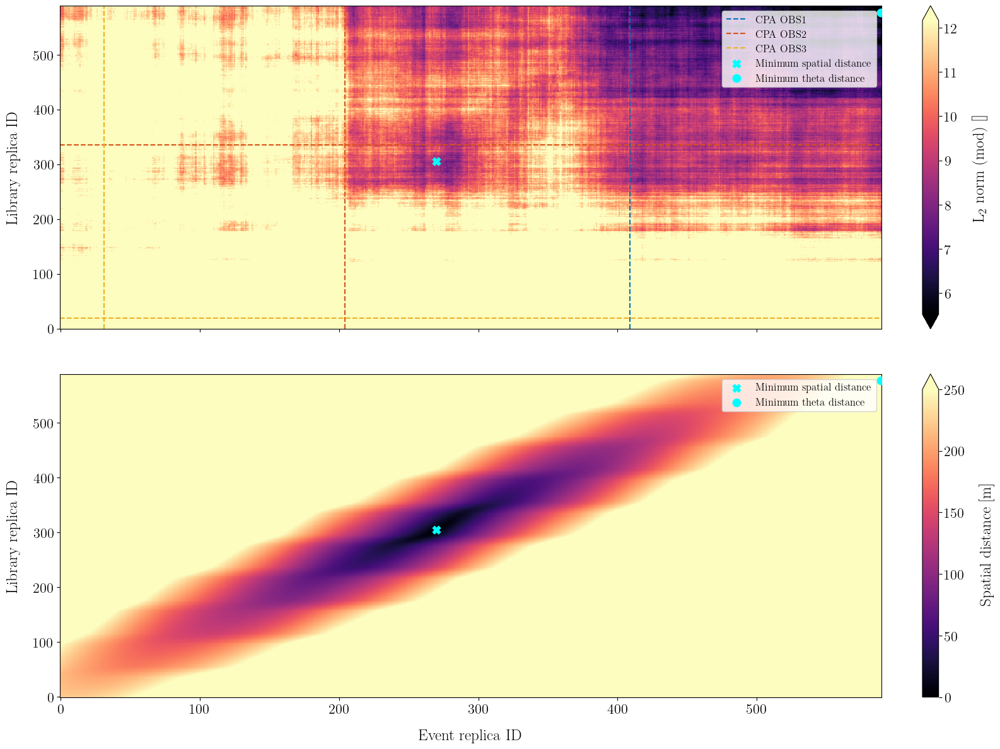

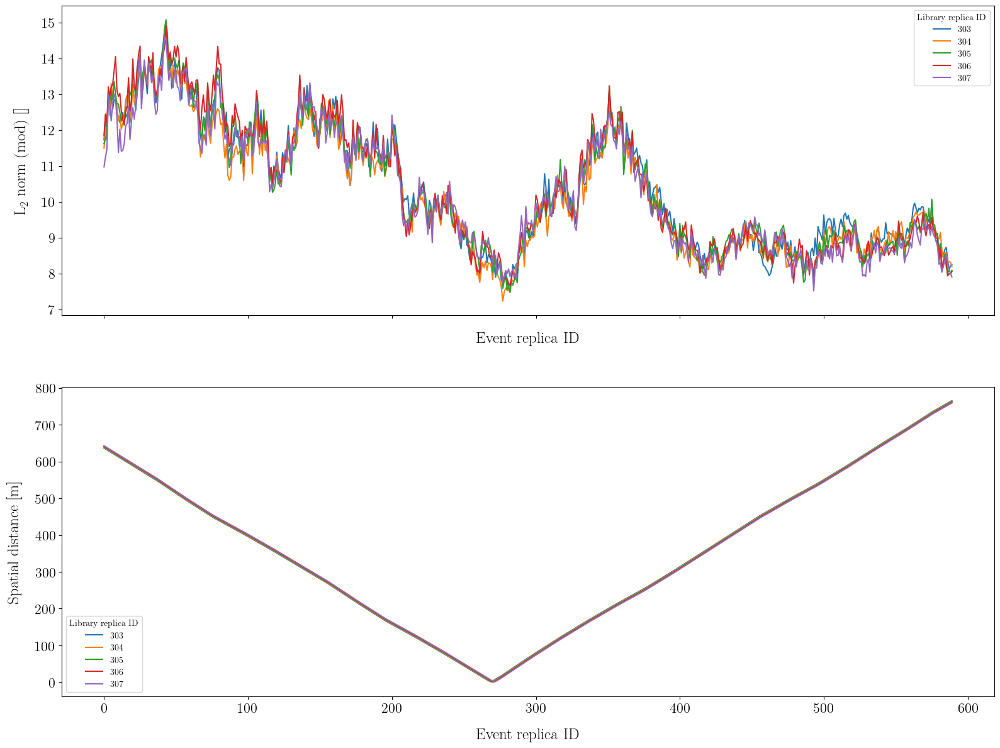

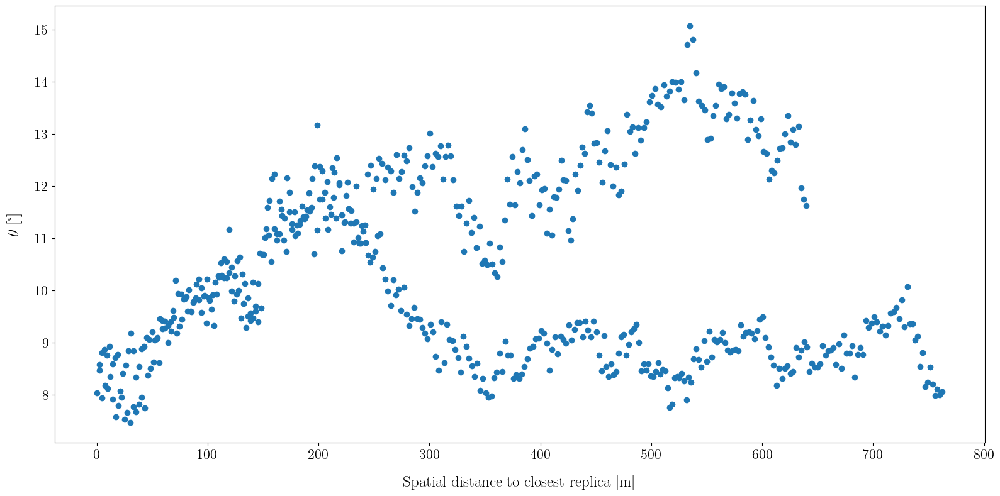

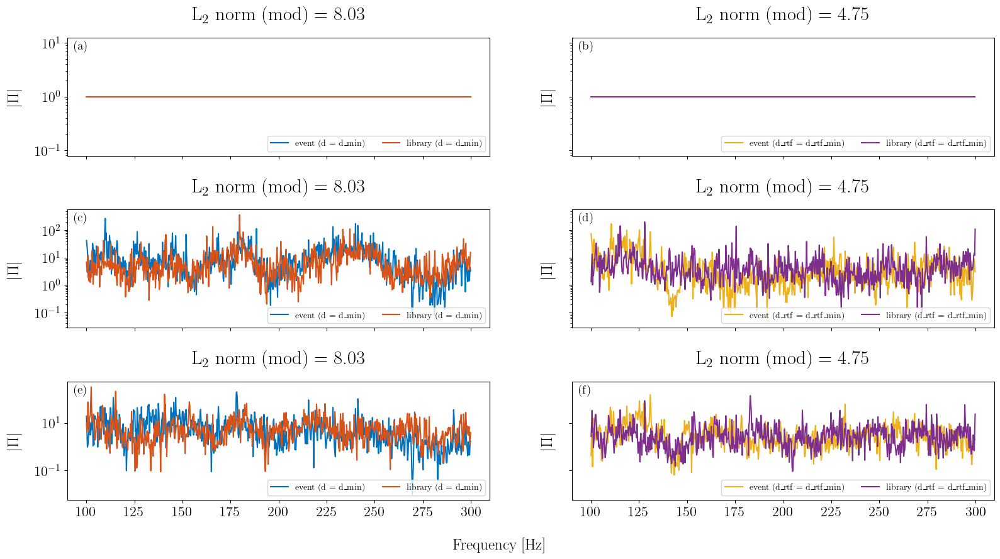

Matching smoothed datasets
Compute L2 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


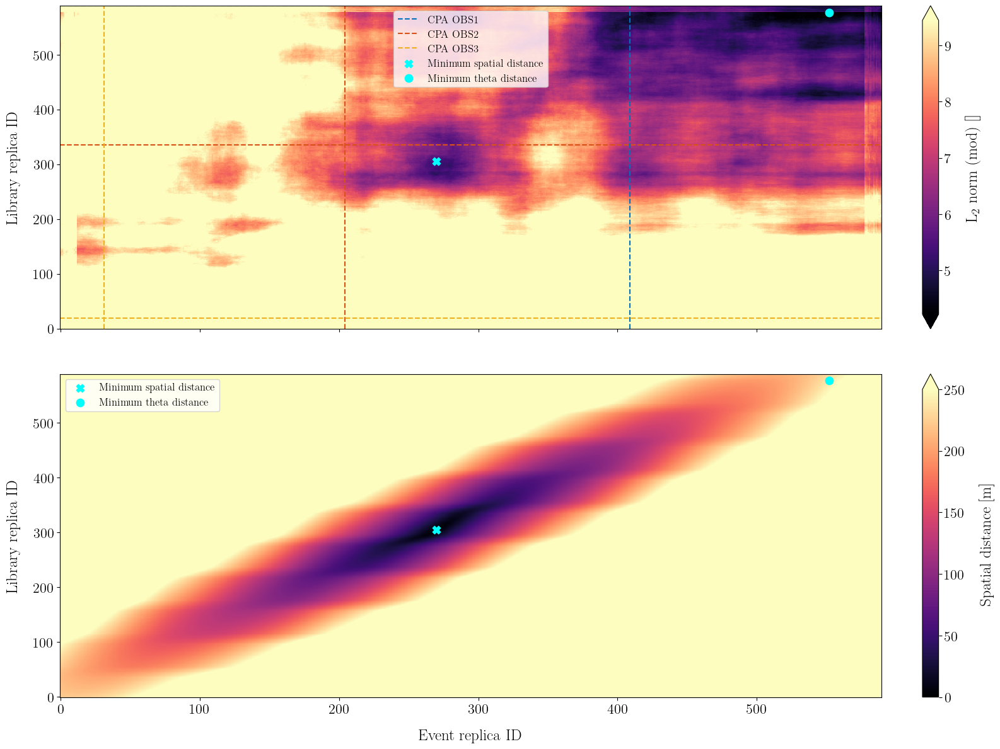

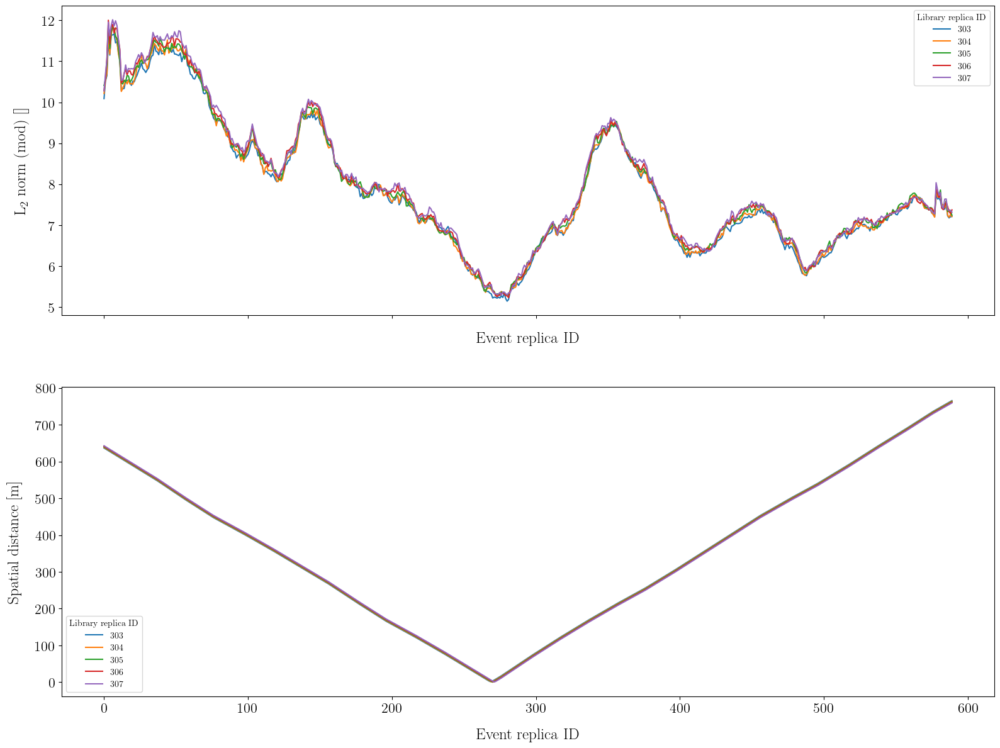

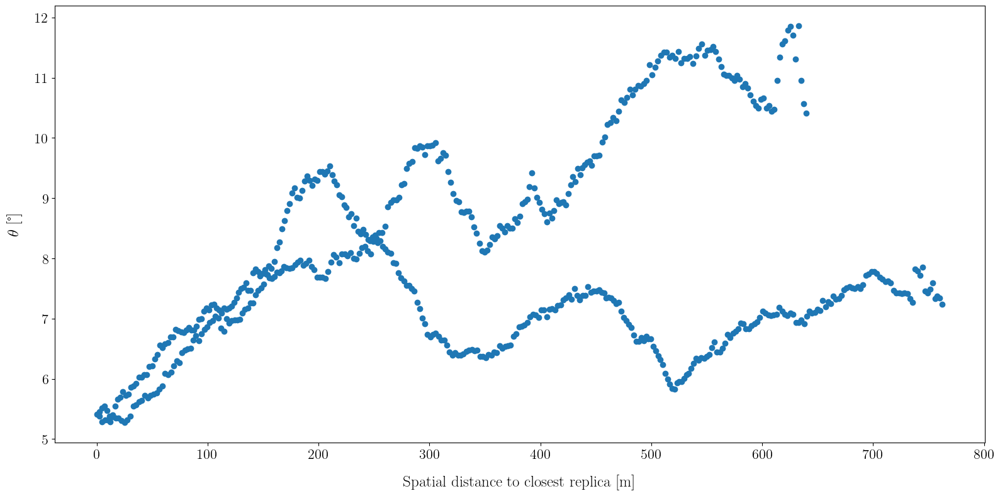

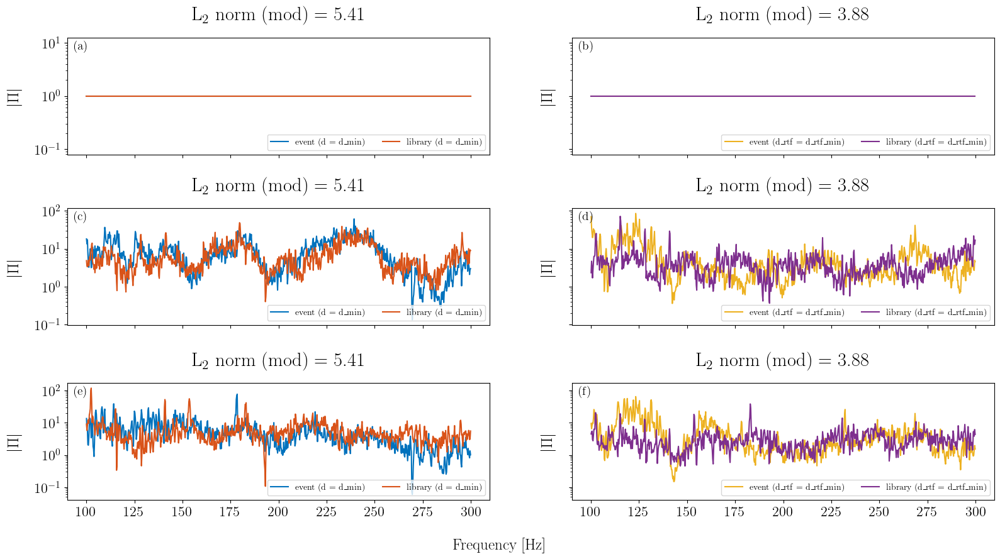

Matching with distance: norm_L2_normalized
Matching original datasets
Compute L2 norm normalized with ref RTF (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


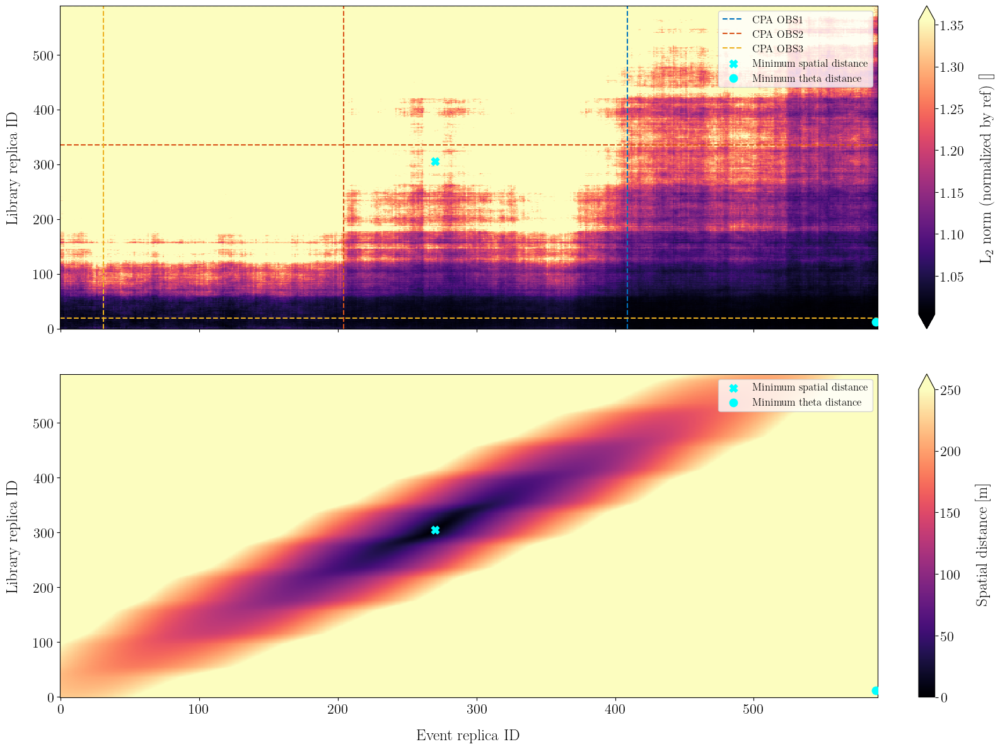

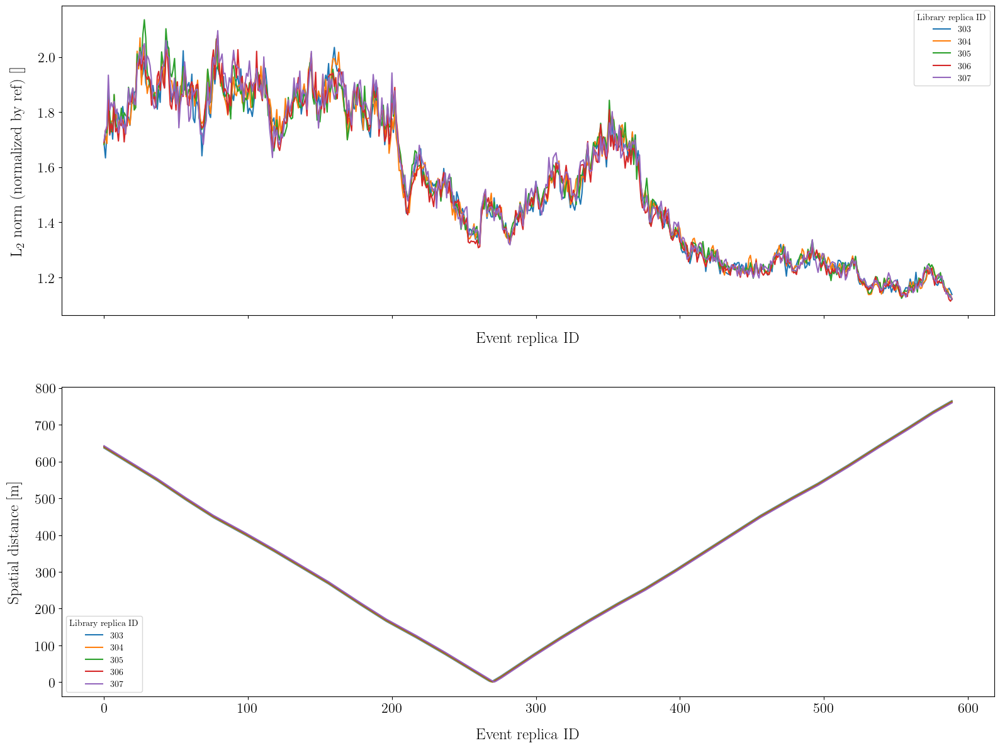

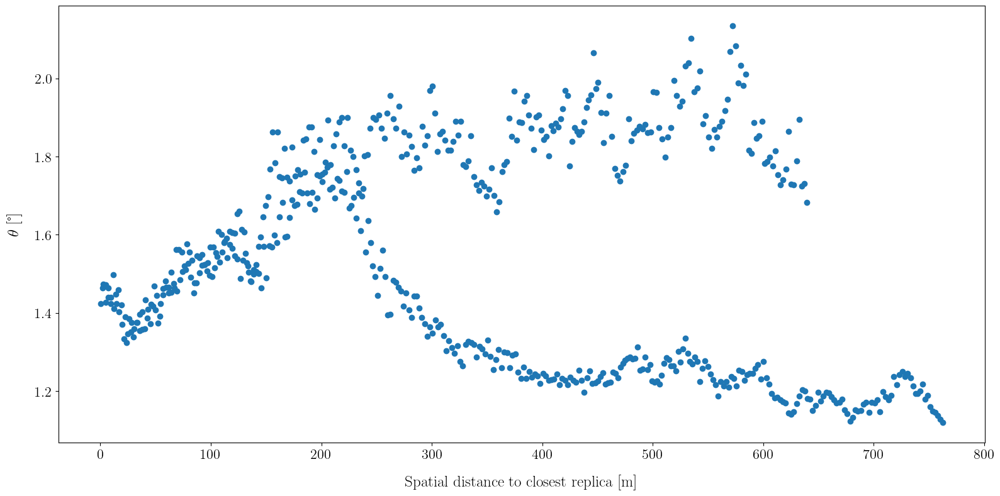

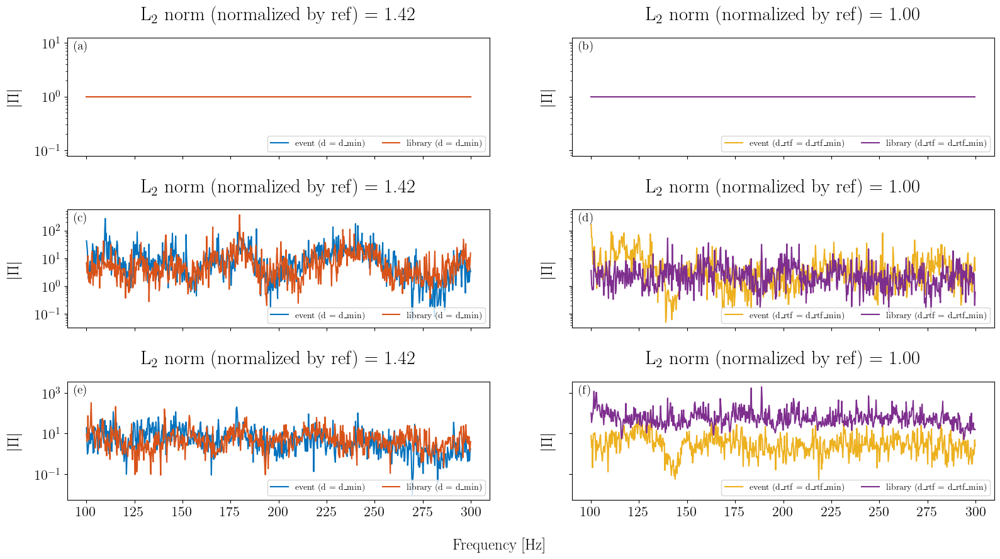

Matching smoothed datasets
Compute L2 norm normalized with ref RTF (in C^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


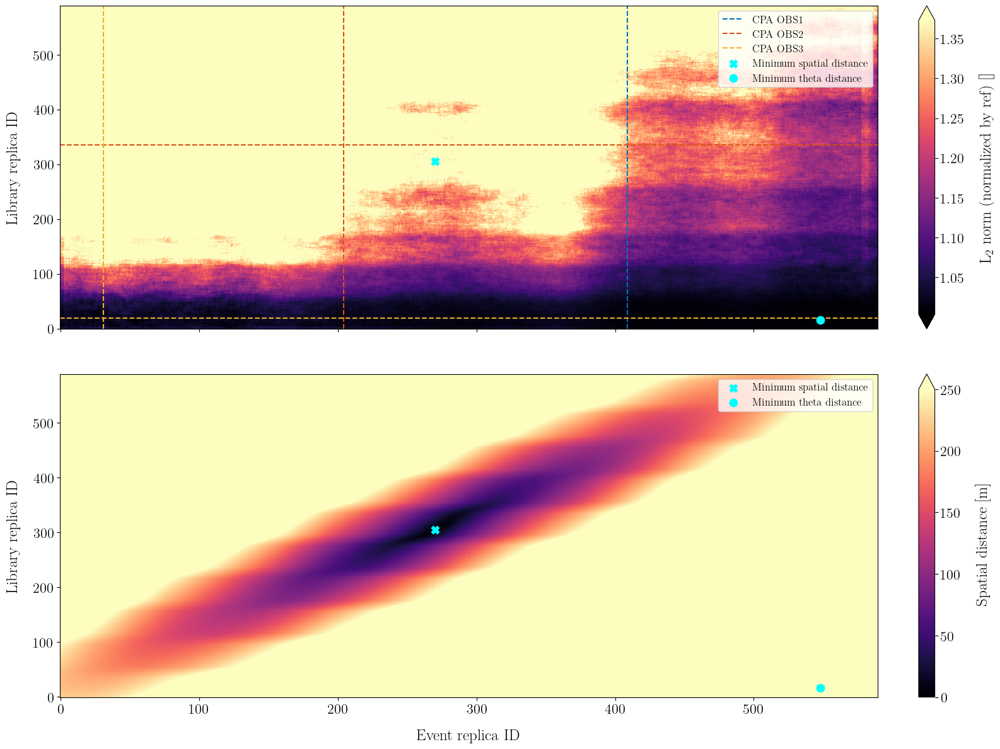

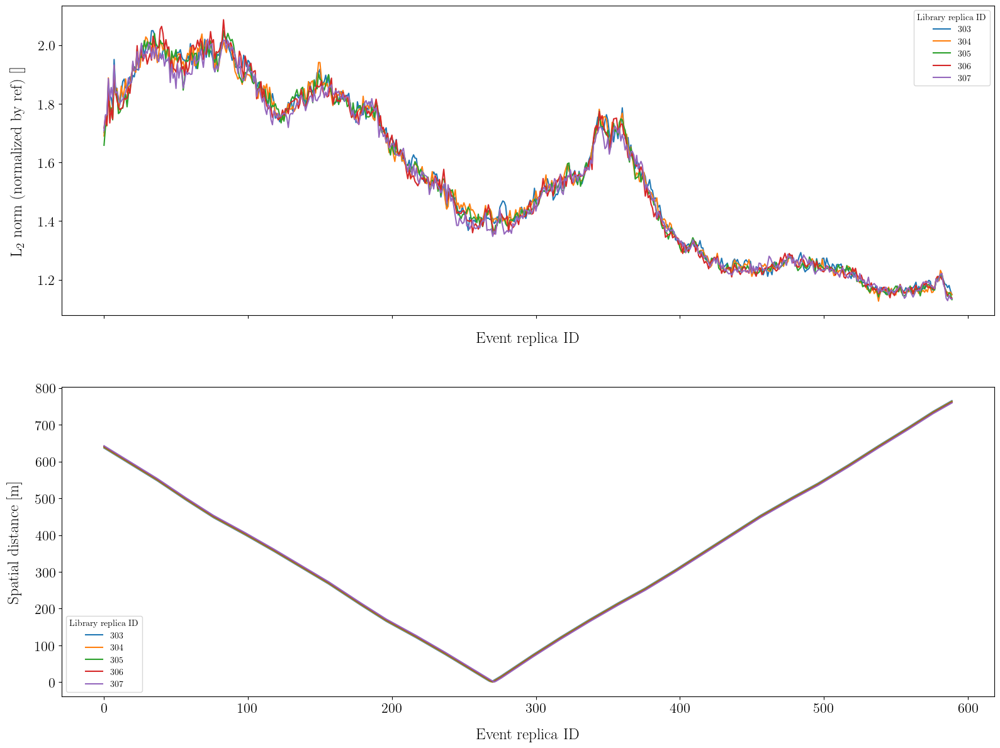

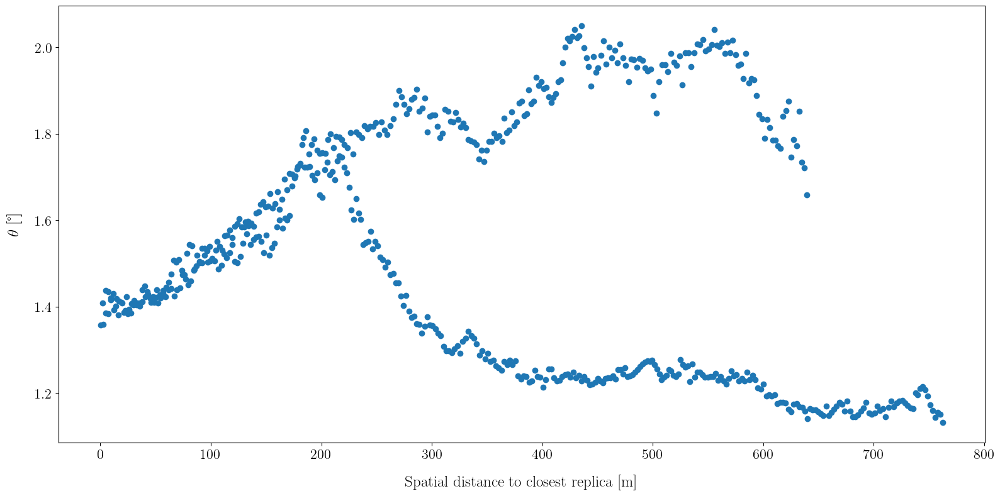

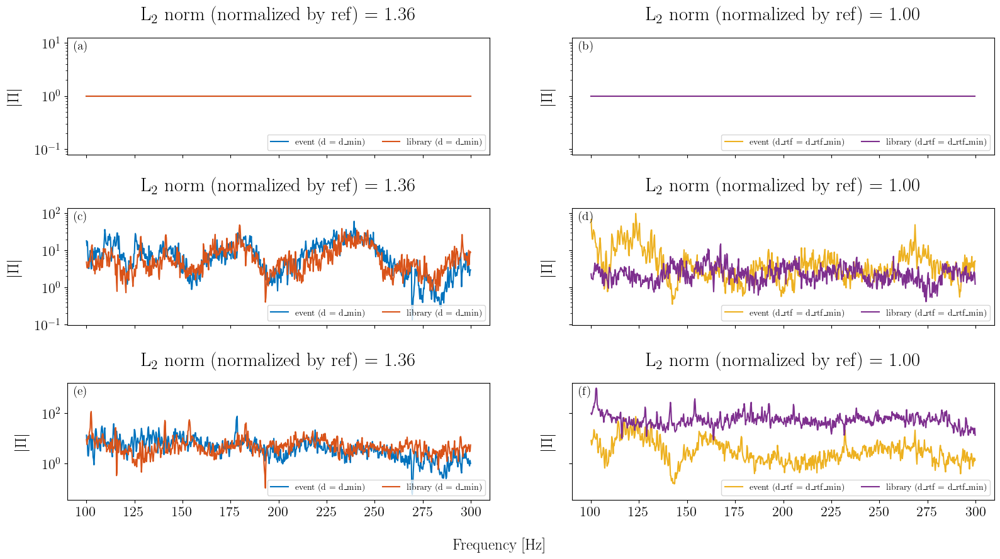

Matching with distance: norm_L2_module_normalized
Matching original datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


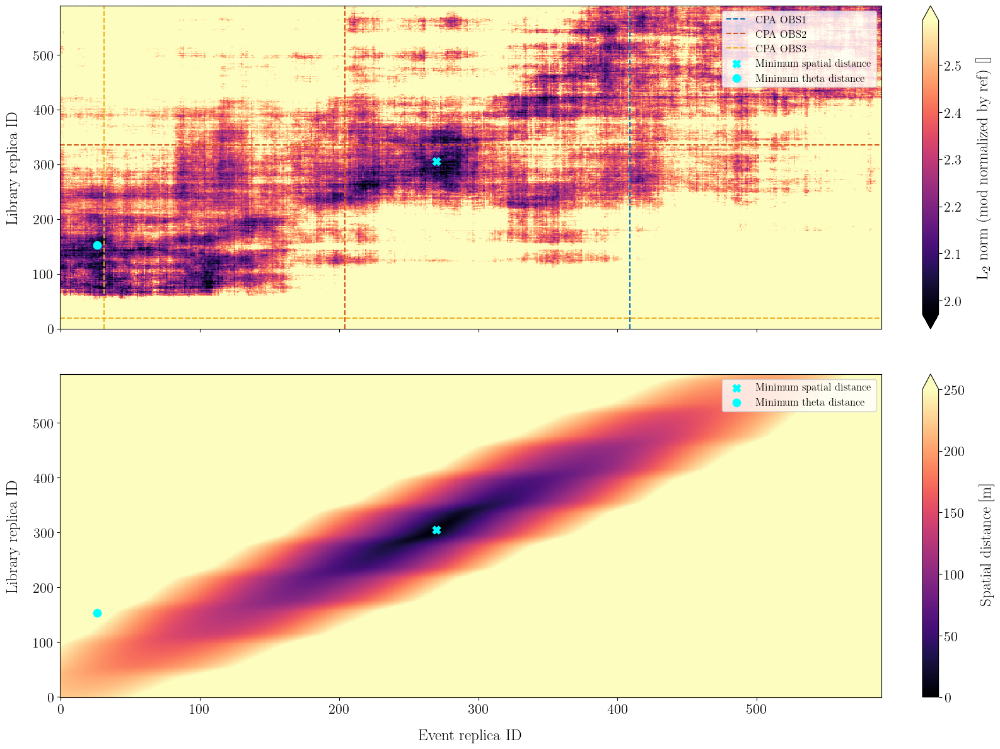

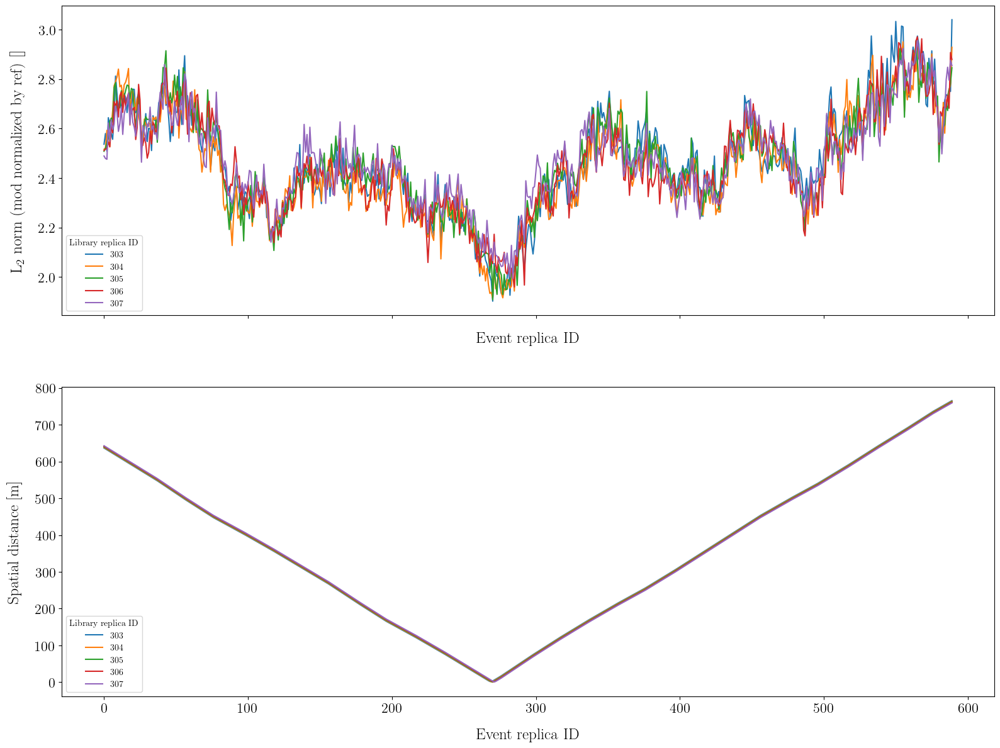

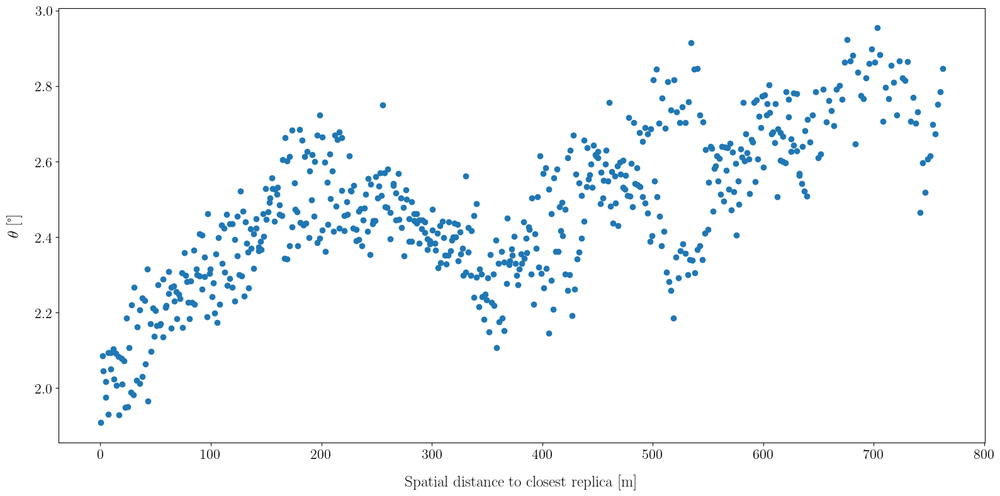

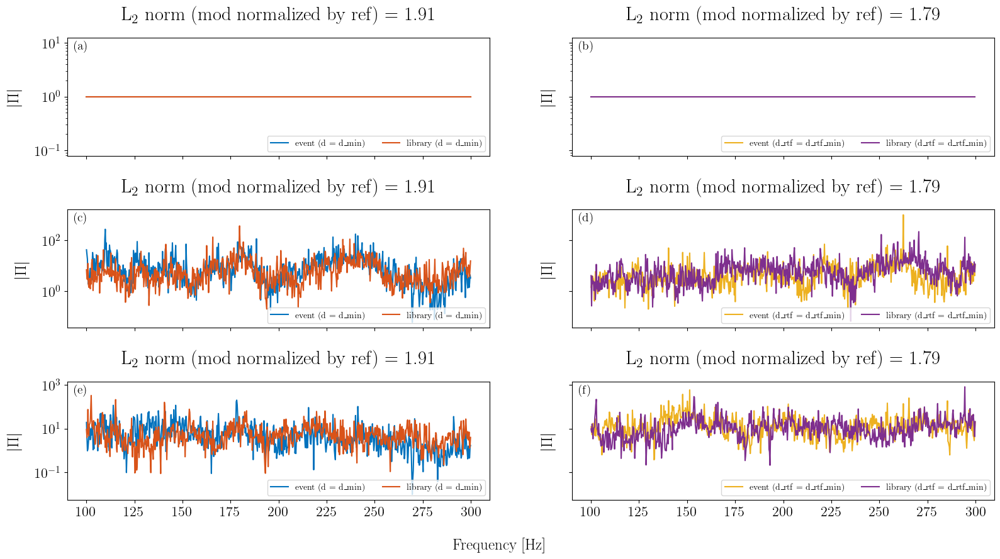

Matching smoothed datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


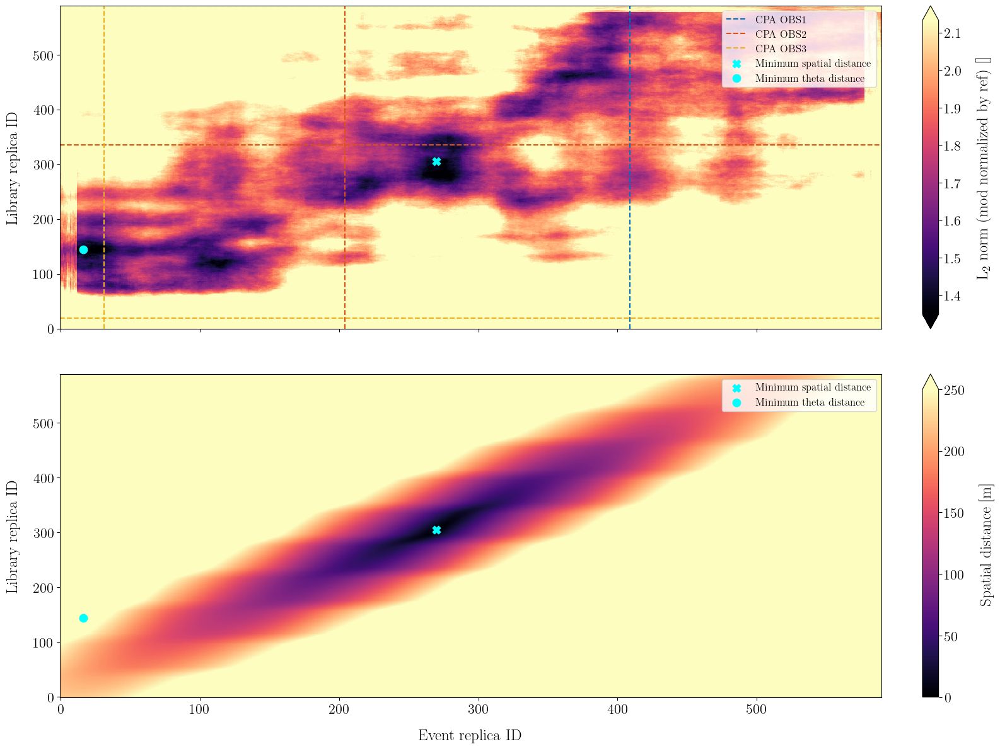

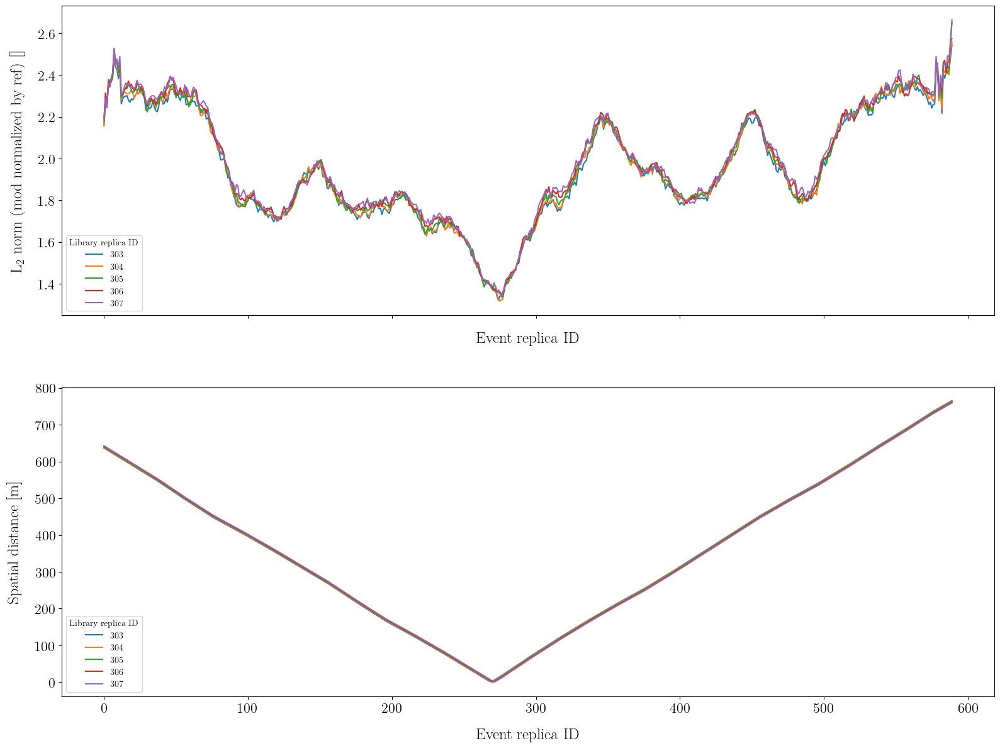

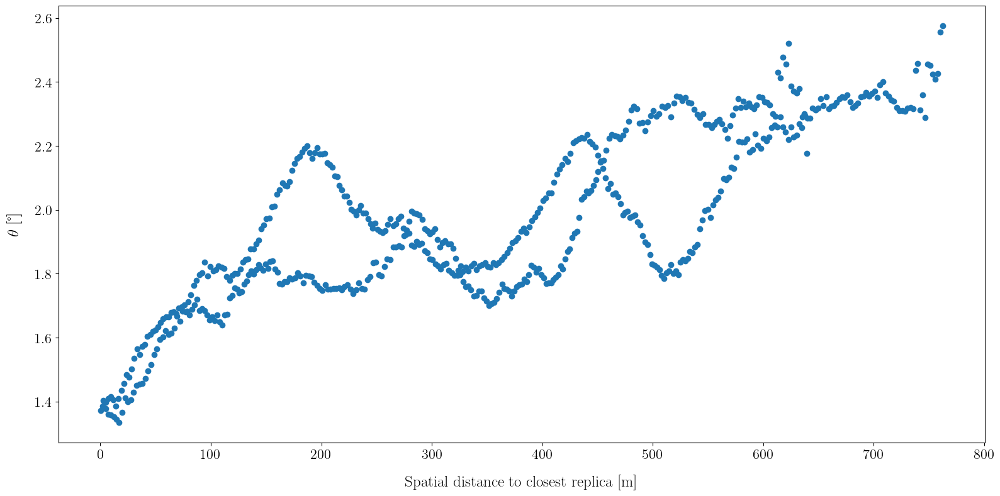

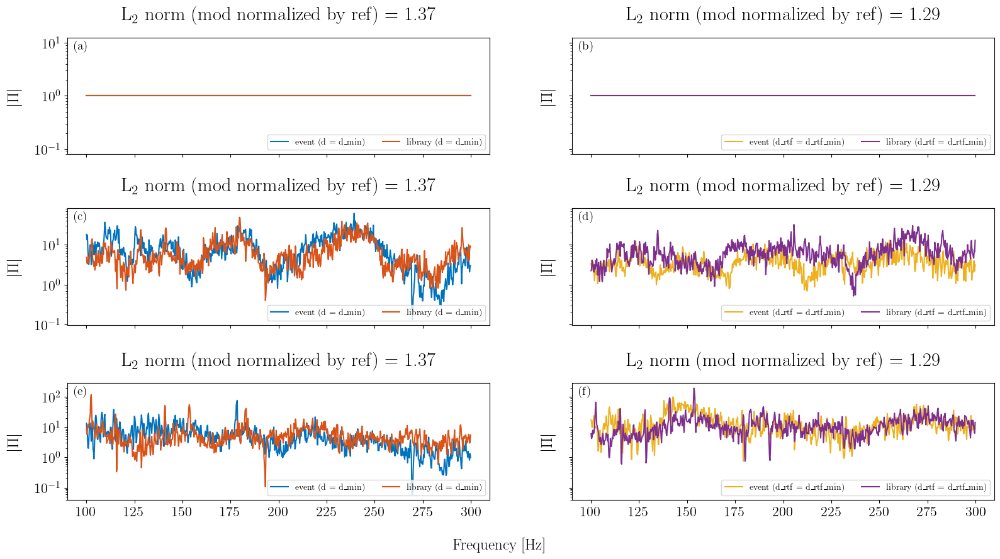

Matching with distance: intercorr_max
Matching original datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


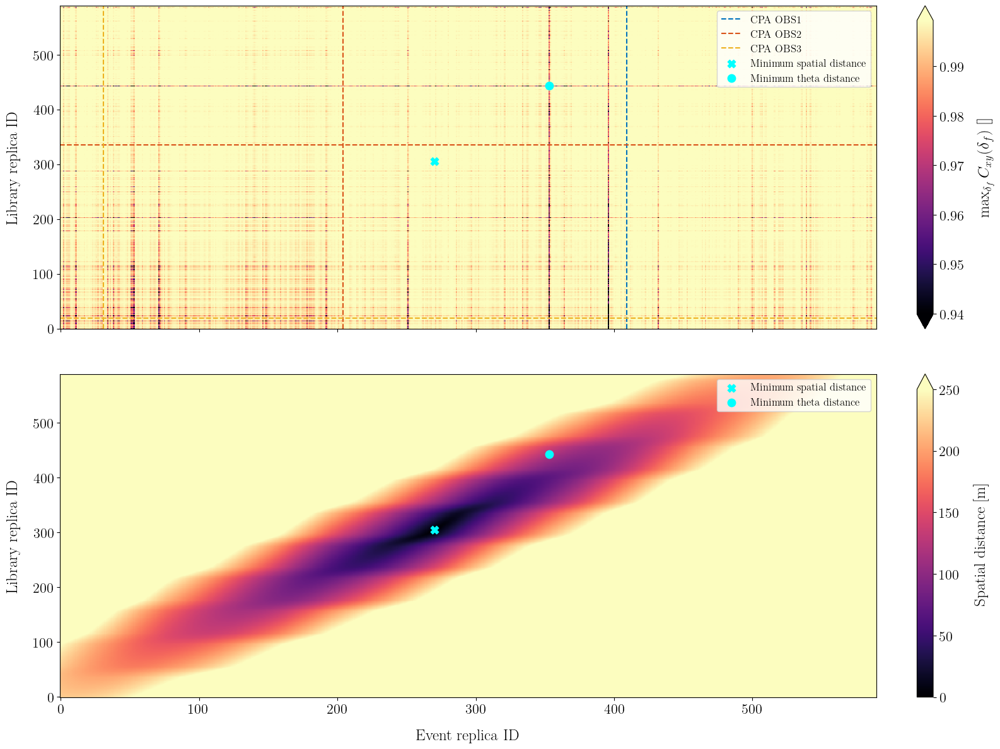

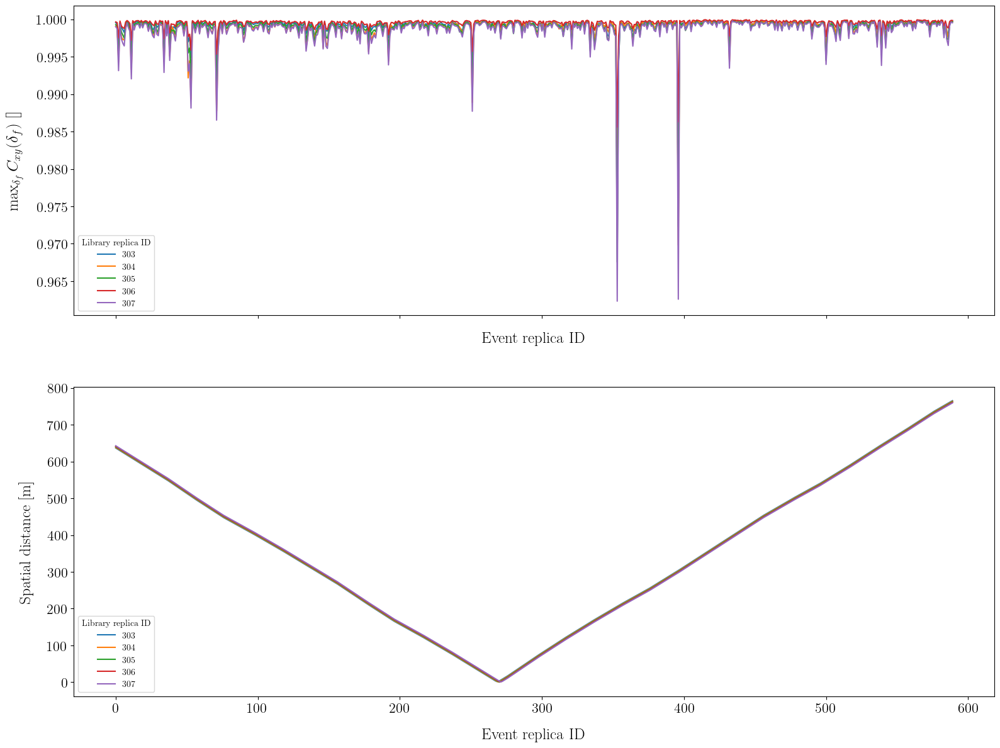

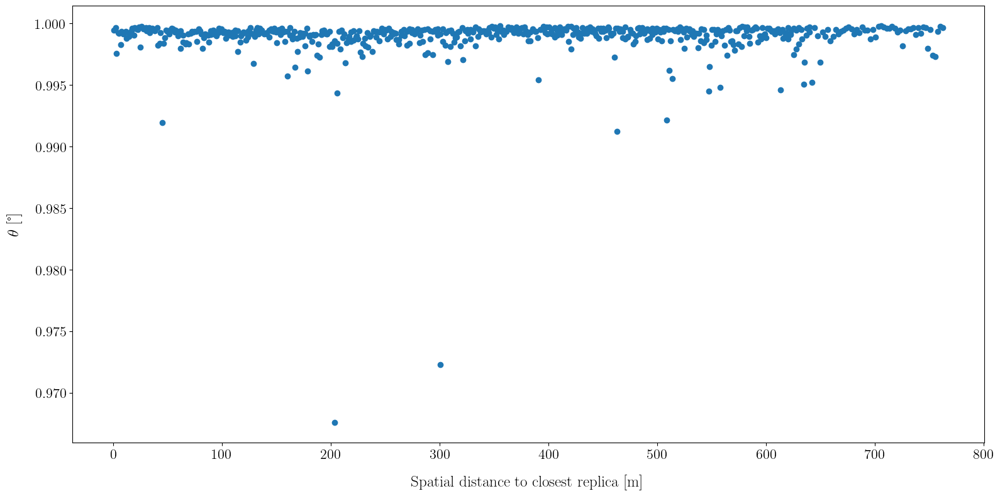

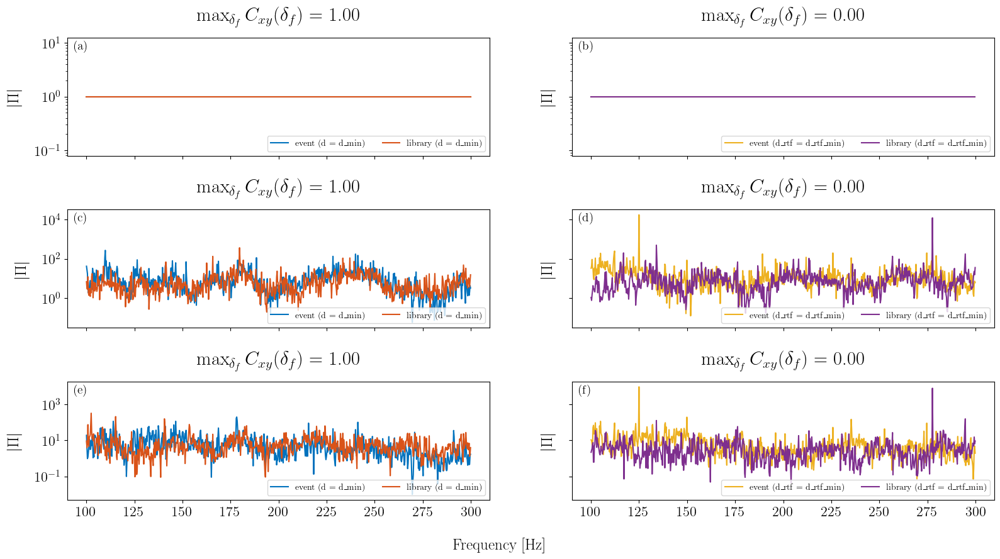

Matching smoothed datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


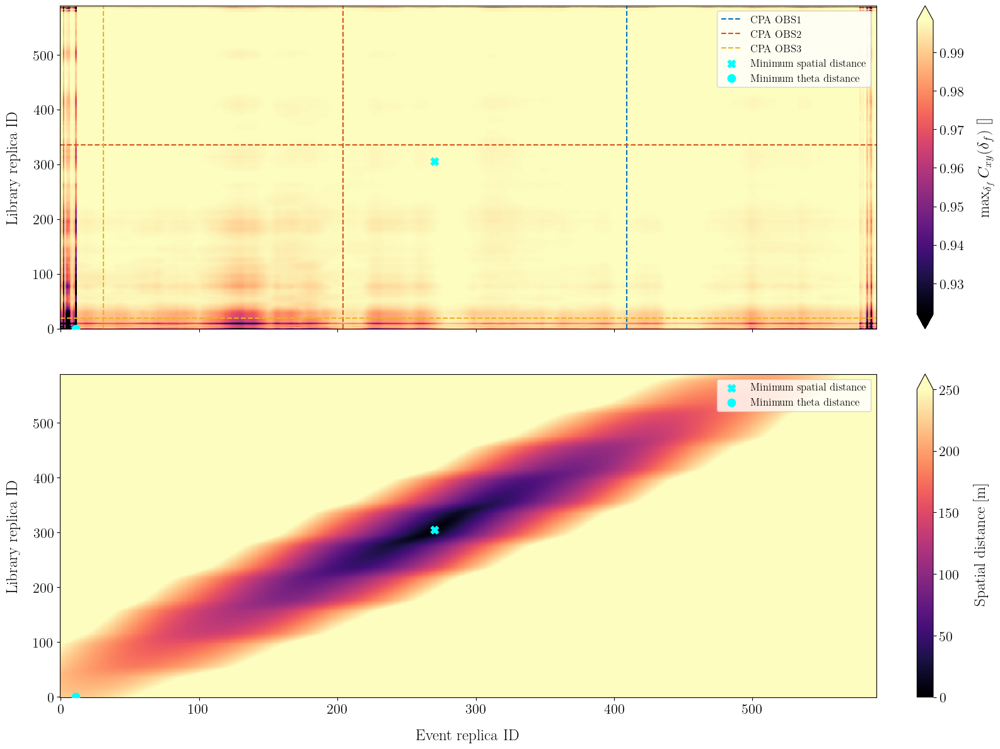

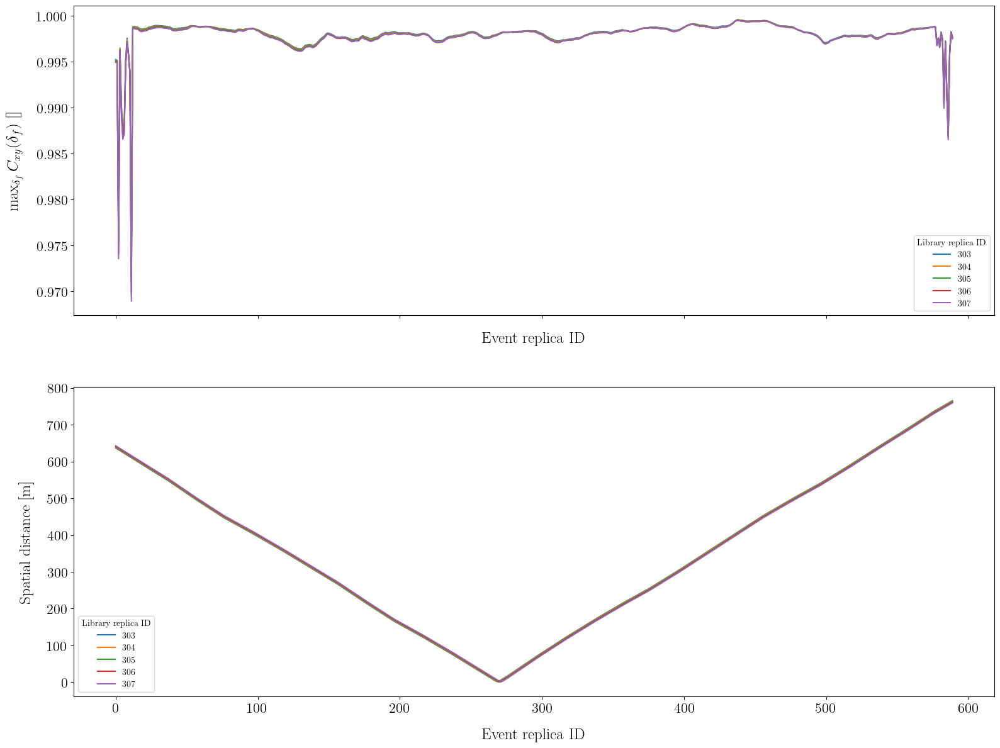

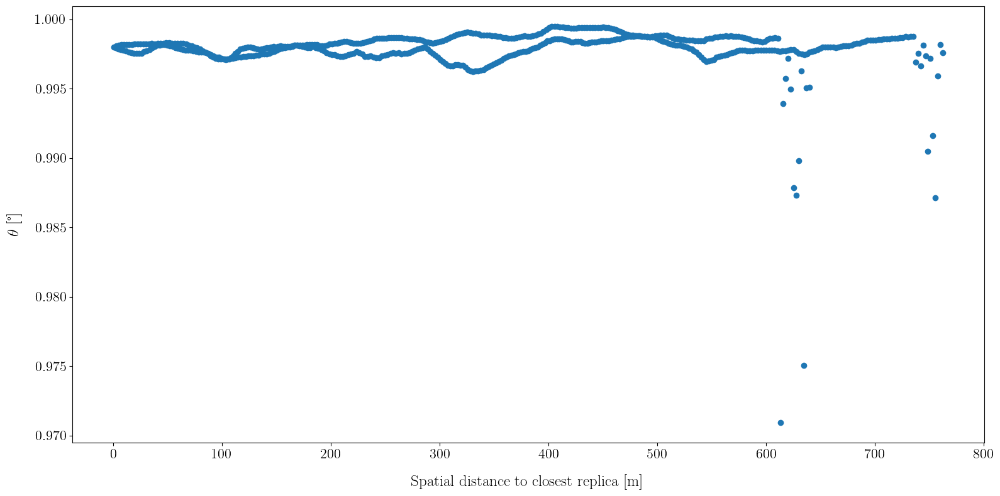

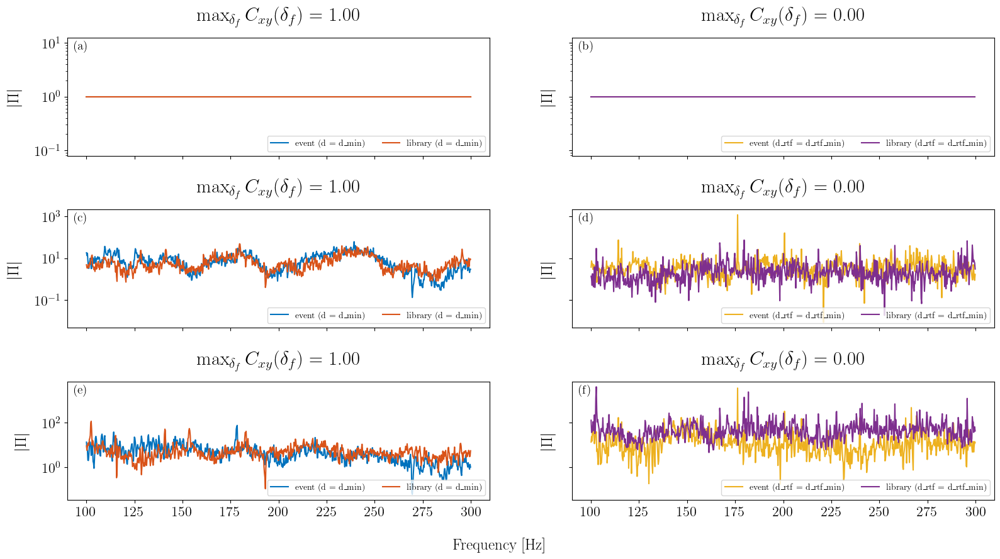

In [27]:
###########################
# Matching library and event features
###########################
root_img = os.path.join(
    rtf_mfp_processor.root_results_fig, f"library_{id_library}_event_{id_event}", "result_smooth_k"
)
os.makedirs(root_img, exist_ok=True)


fmin = 100
fmax = 300
dist_args = {
    "fmin": fmin,
    "fmax": fmax,
    "dist_type": None,
    "use_weighted_mean": False,
}

plot_args = {
    "plot_lib_pos": False,
    "plot_event_pos": False,
    "plot_lib_and_event_pos": True, 
    "plot_dist_matrices": True,
    "plot_dist_around_sptial_min_dist": True,
    "plot_feature_details": True,
    "plot_feature_details_module": True,
    "plot_feature_details_phase": False,
    "plot_feature_details_theta": False,
}

distances = [
    "hermitian_angle",
    "hermitian_angle_module",
    "hermitian_angle_along_freq",
    "norm_L1",
    "norm_L1_module",
    "norm_L2",
    "norm_L2_module",
    "norm_L2_normalized",
    "norm_L2_module_normalized",
    "intercorr_max"
]

init = True
for distance in distances:
    dist_args["dist_type"] = distance
    print(f"Matching with distance: {distance}")

    print(f"Matching original datasets")

    root_img_1 = os.path.join(
        root_img, f"distance_{distance}_original"
    )
    os.makedirs(root_img_1, exist_ok=True)

    rtf_mfp_processor.match(
        ds_library=ds_lib, ds_event=ds_event, dist_args=dist_args, plot_args=plot_args, root_img=root_img_1
    )
    plt.show()
    print(f"Matching smoothed datasets")

    if init:
        plot_args["plot_lib_and_event_pos"] = False
        init = False

    root_img_2 = os.path.join(
        root_img, f"distance_{distance}_smooth_k"
    )

    rtf_mfp_processor.match(
        ds_library=ds_lib_smooth,
        ds_event=ds_event_smooth,
        dist_args=dist_args,
        plot_args=plot_args,
        root_img=root_img_2
    )
    plt.show()

    plt.close("all")

Matching with distance: norm_L1_module
Matching original datasets


Compute L1 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


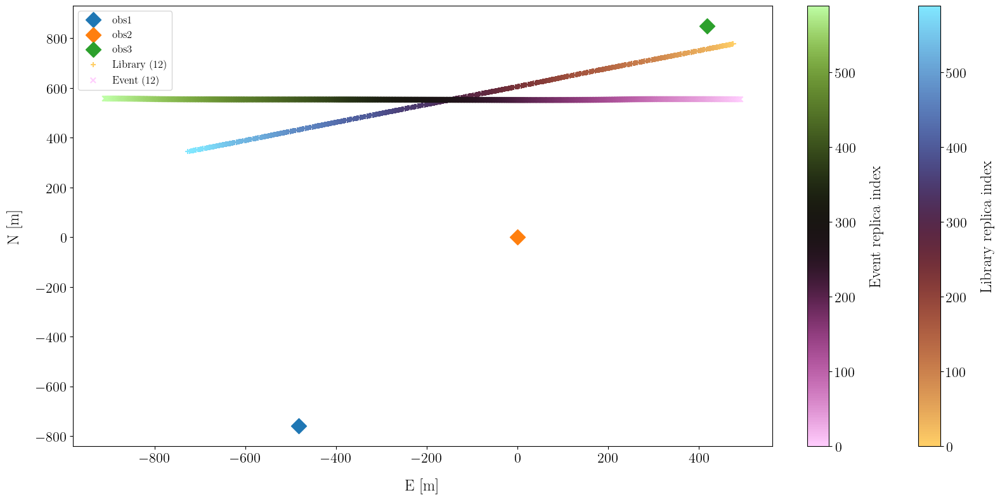

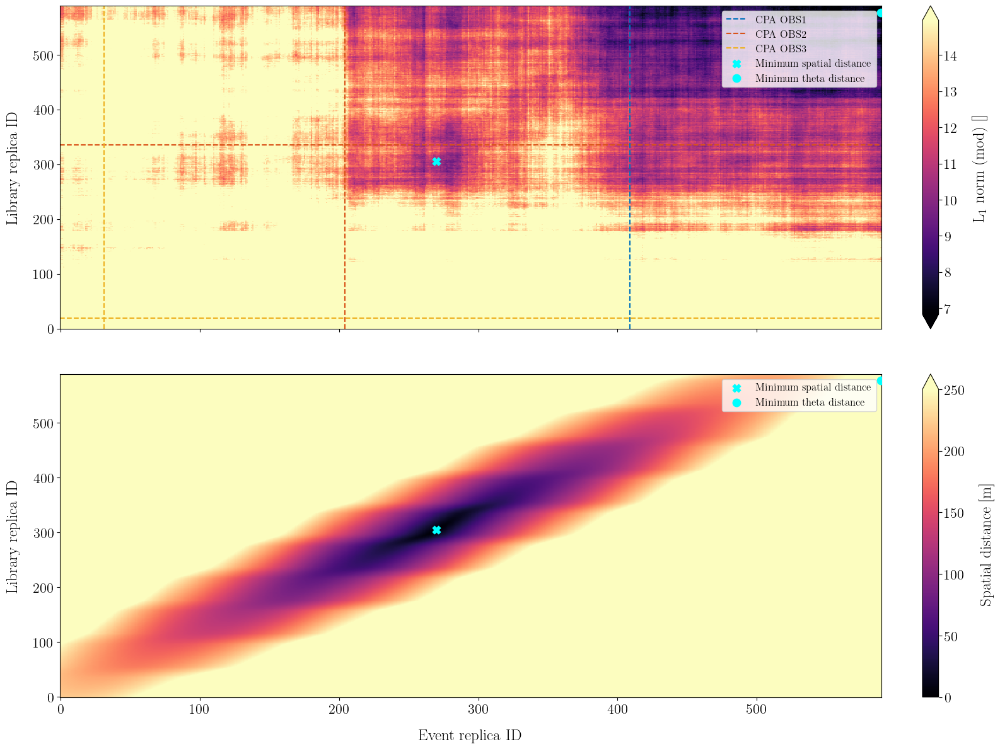

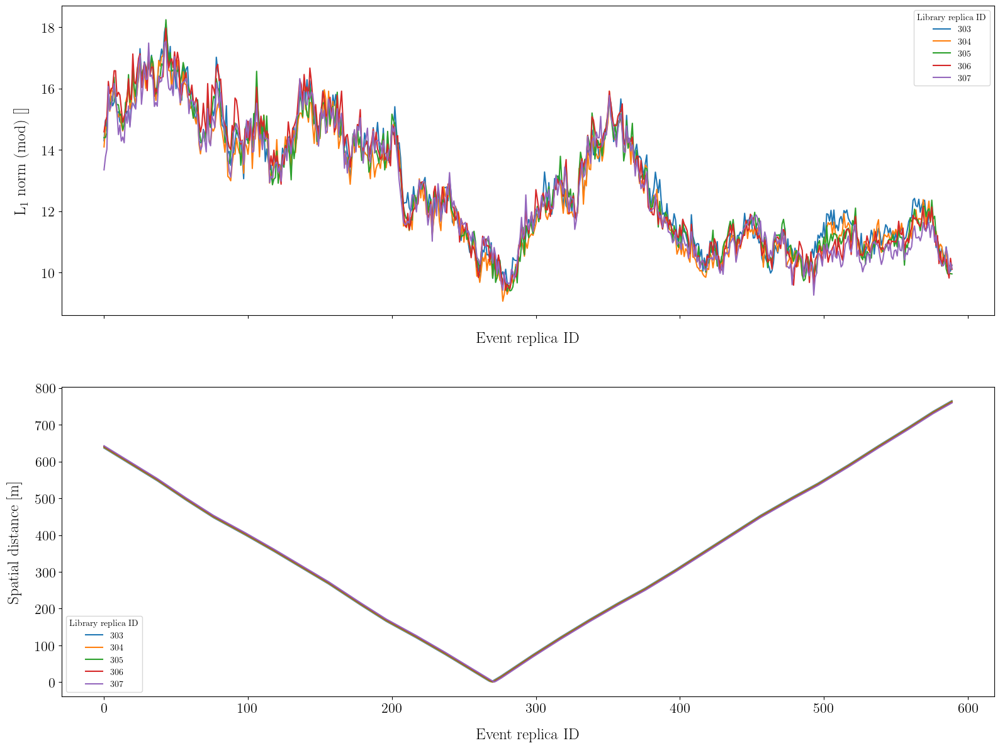

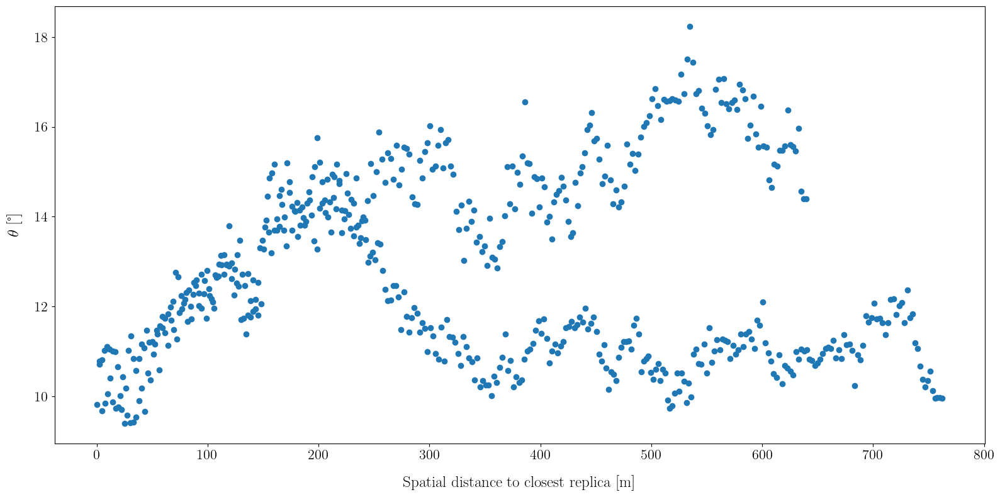

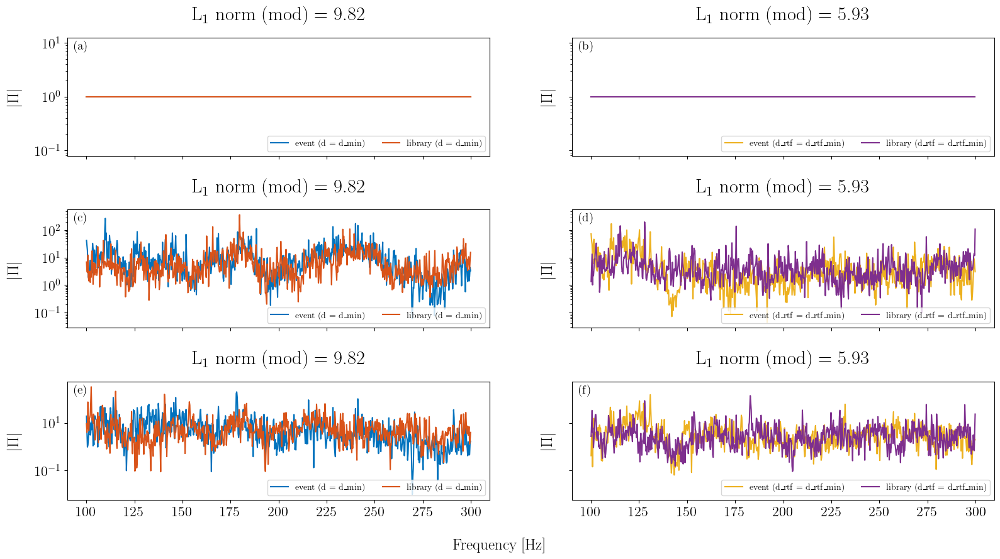

Matching smoothed datasets
Compute L1 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


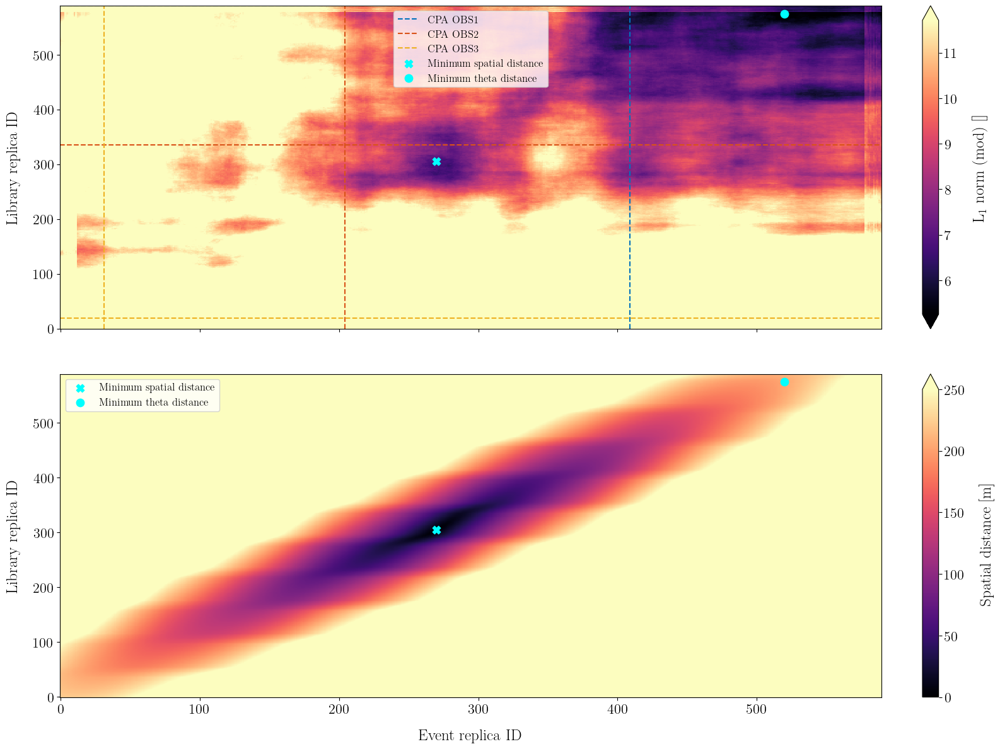

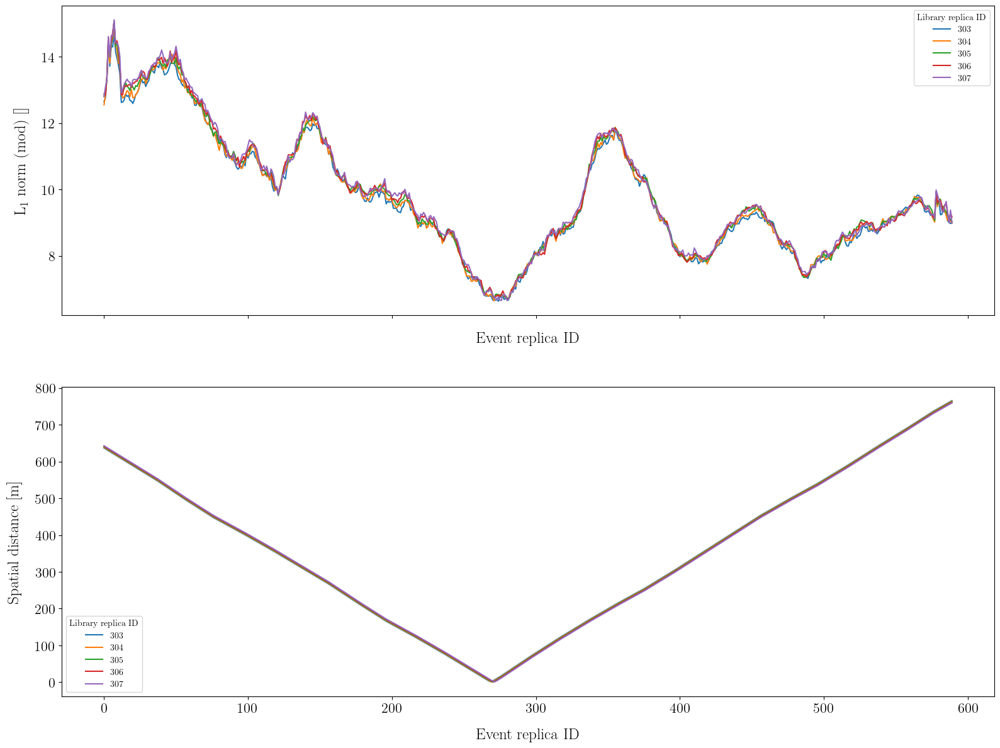

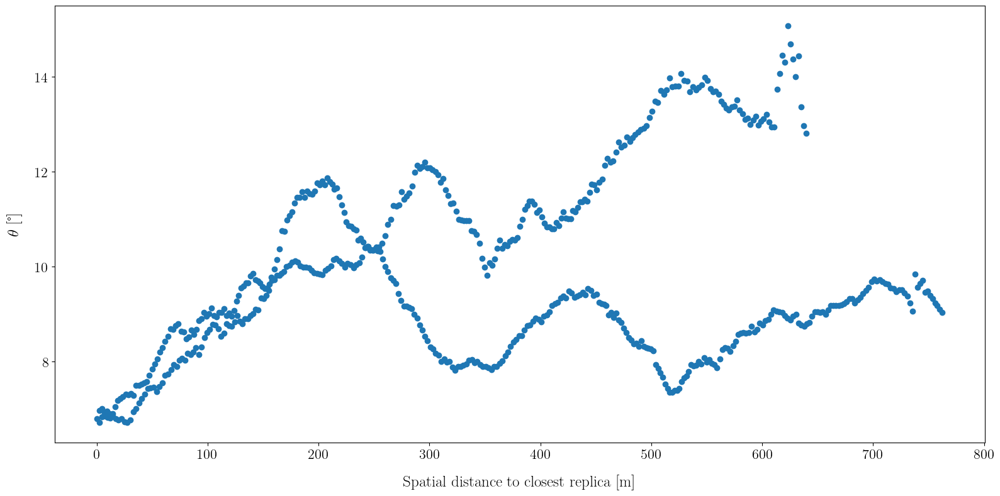

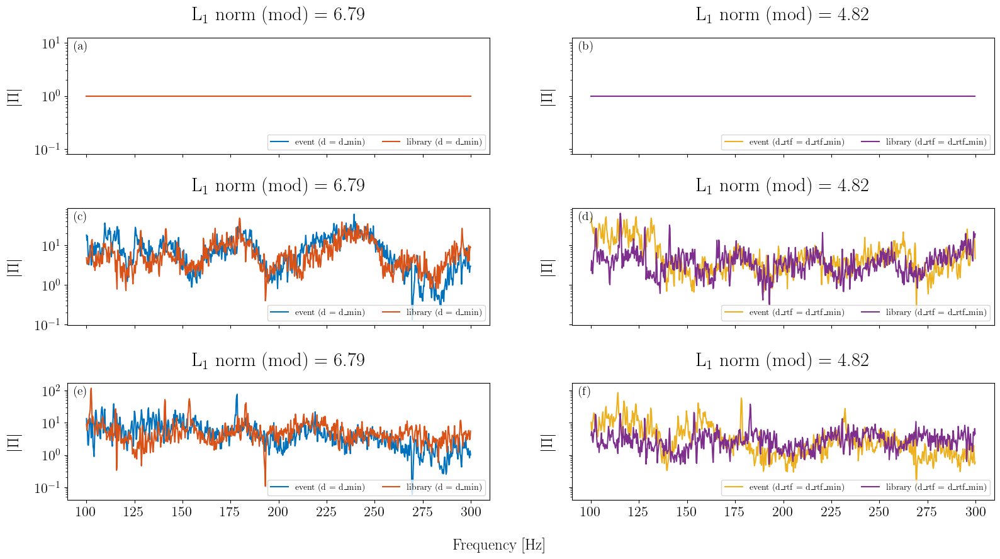

Matching with distance: norm_L2_module
Matching original datasets
Compute L2 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


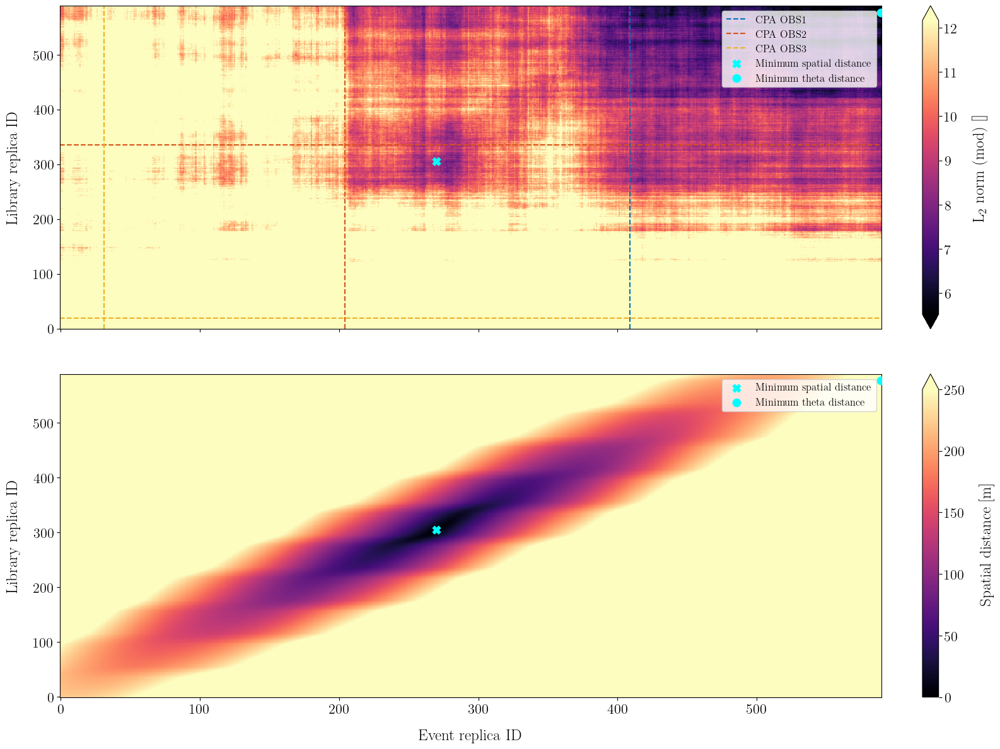

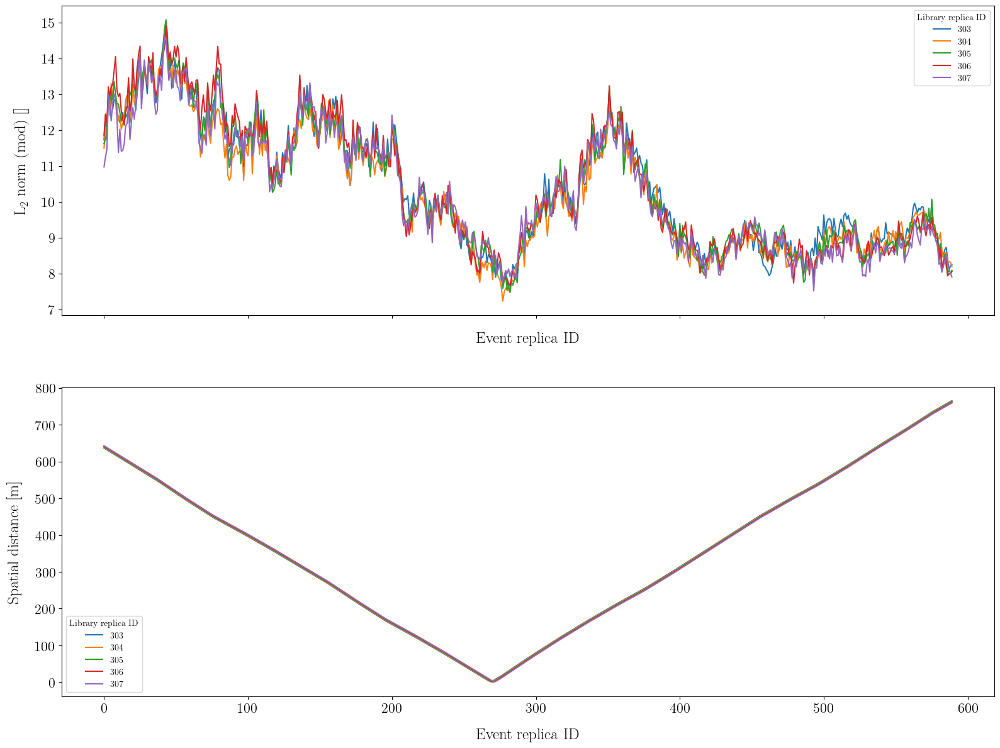

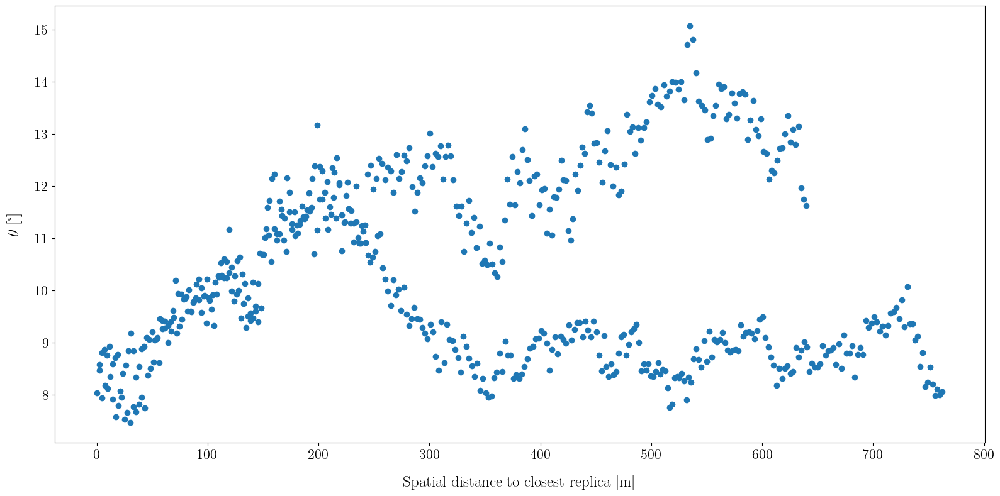

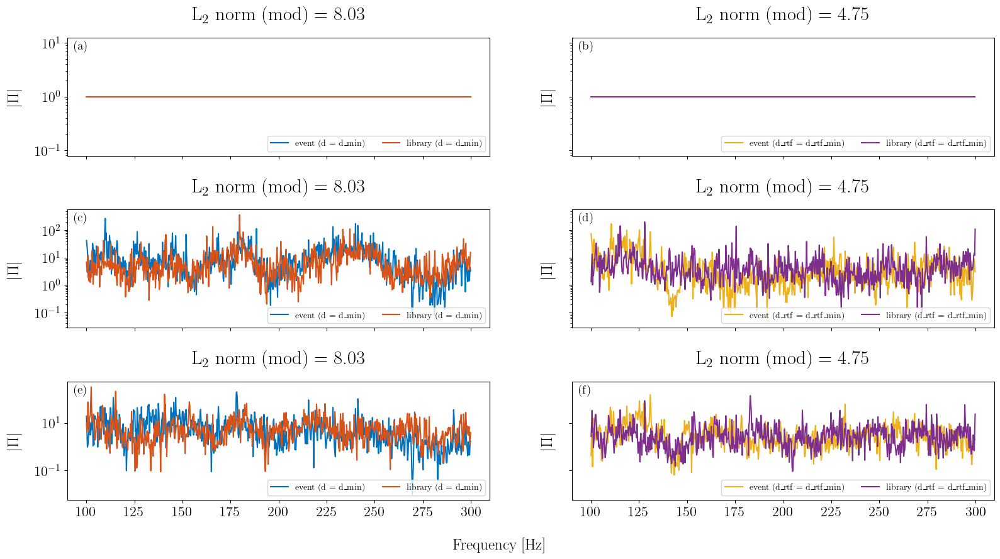

Matching smoothed datasets
Compute L2 norm for RTF module (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


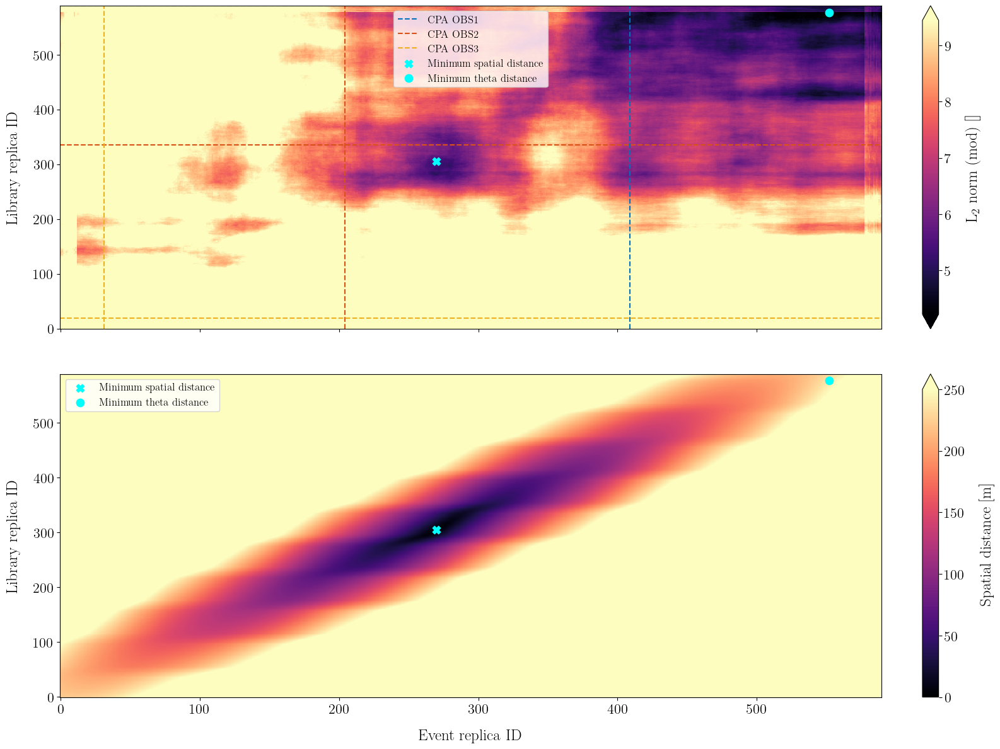

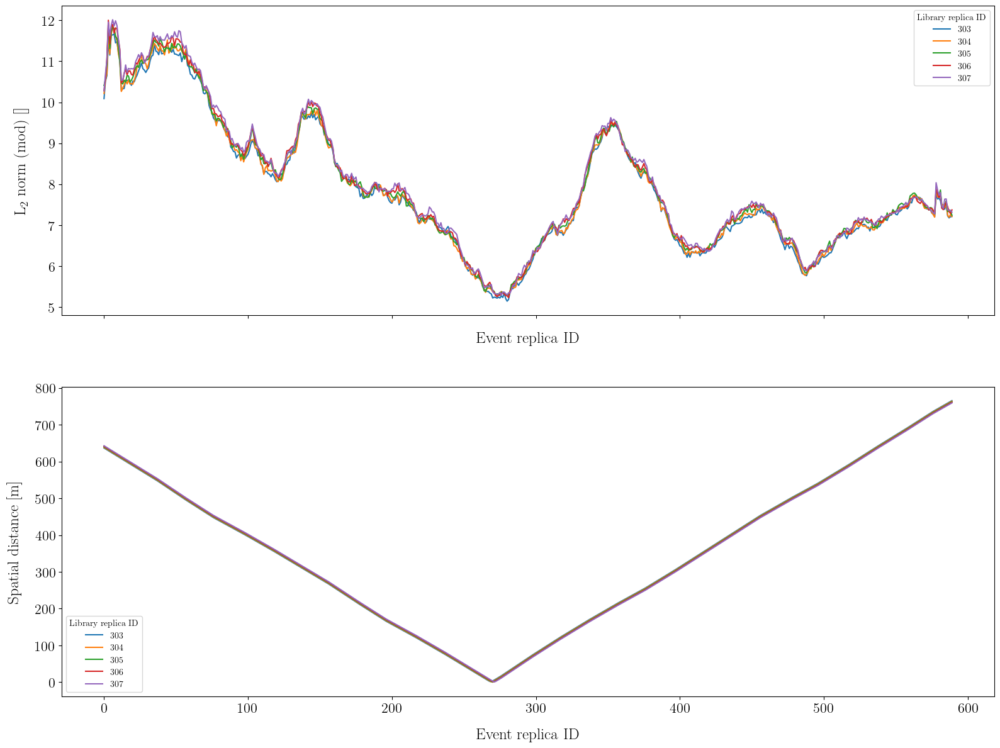

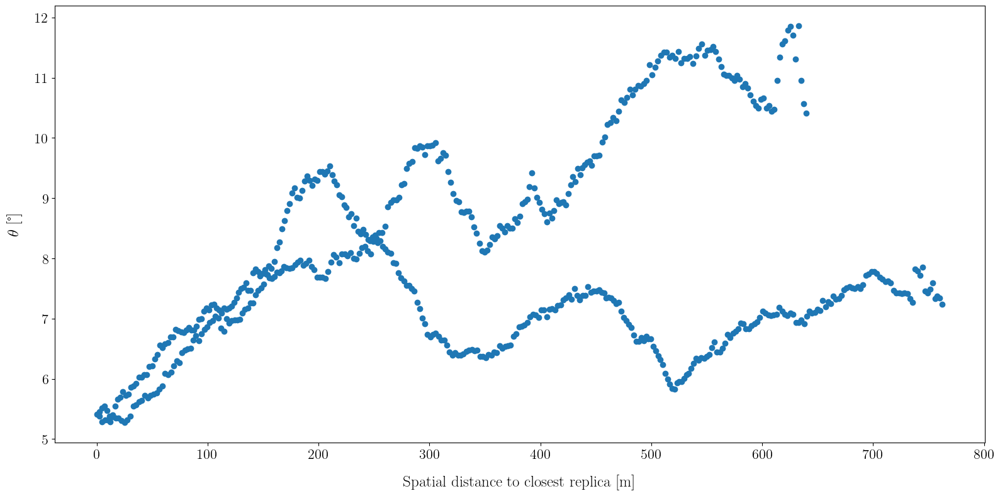

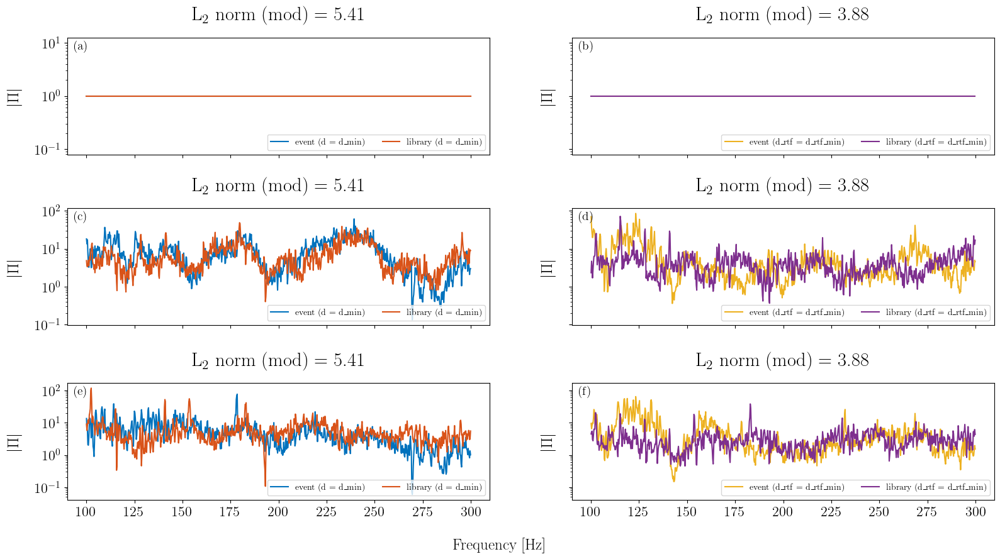

Matching with distance: norm_L2_module_normalized
Matching original datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


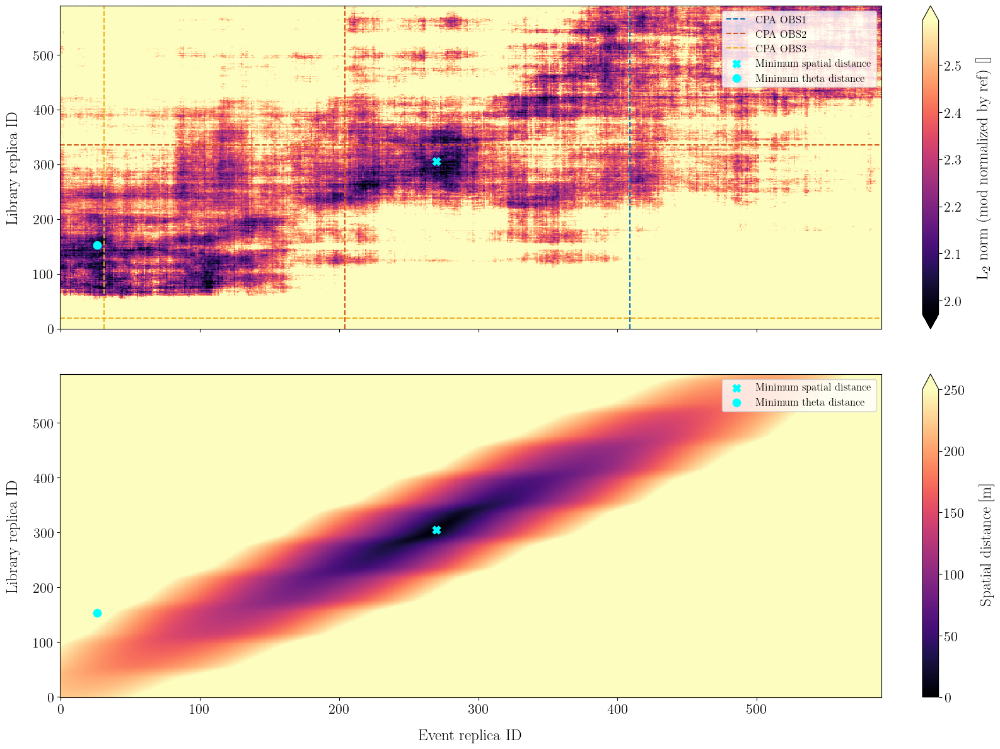

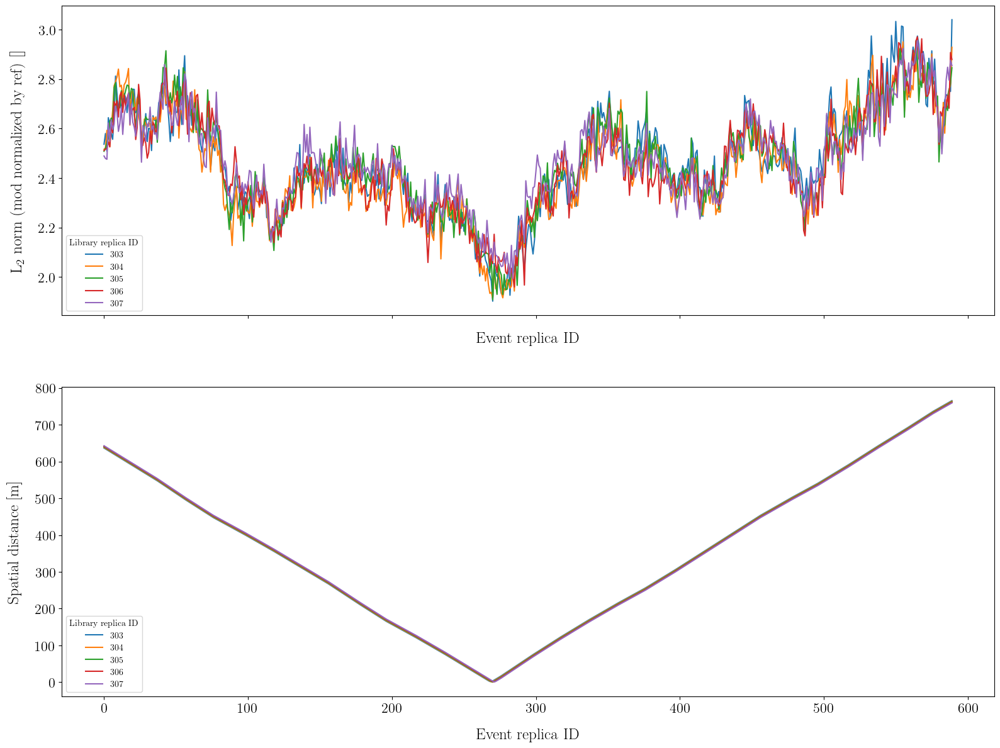

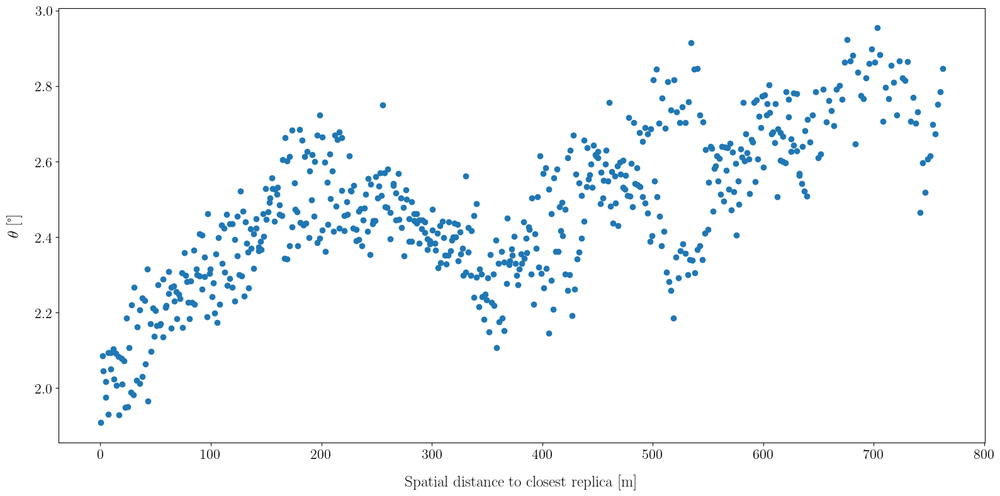

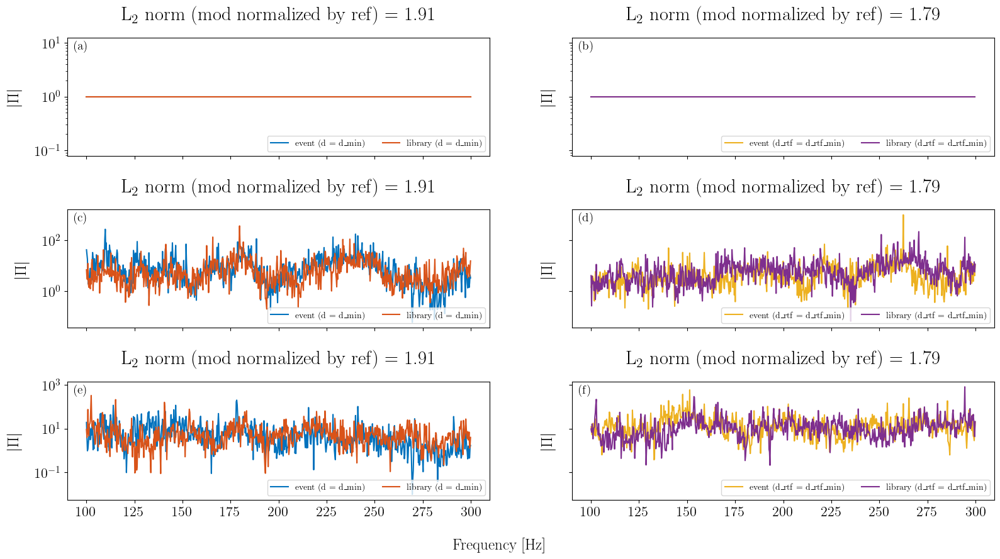

Matching smoothed datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


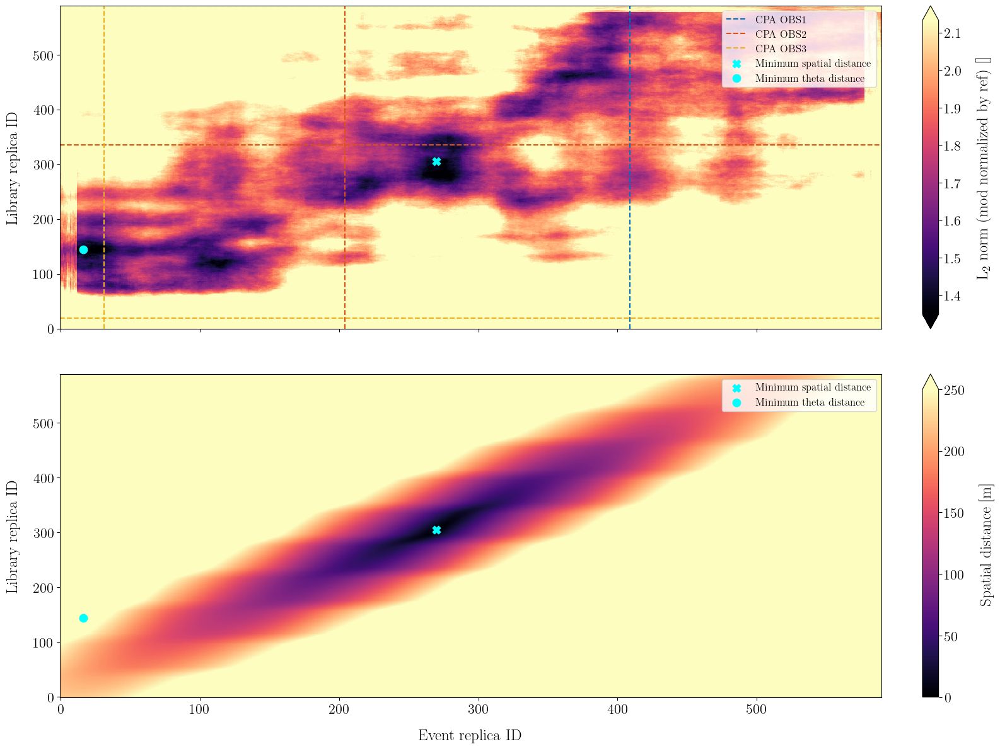

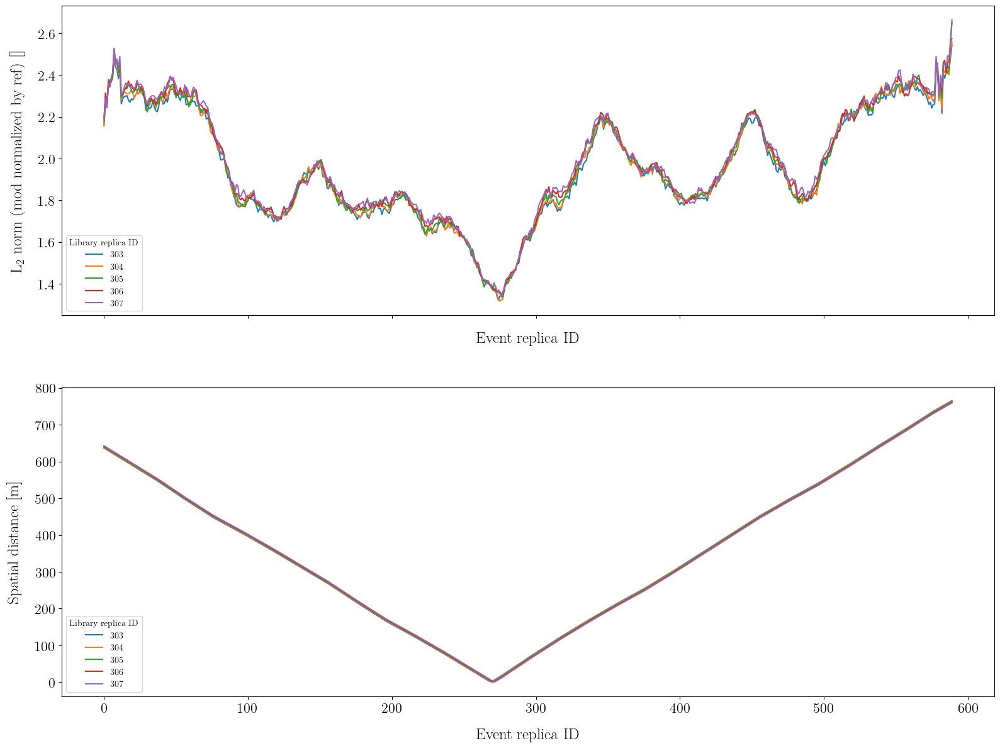

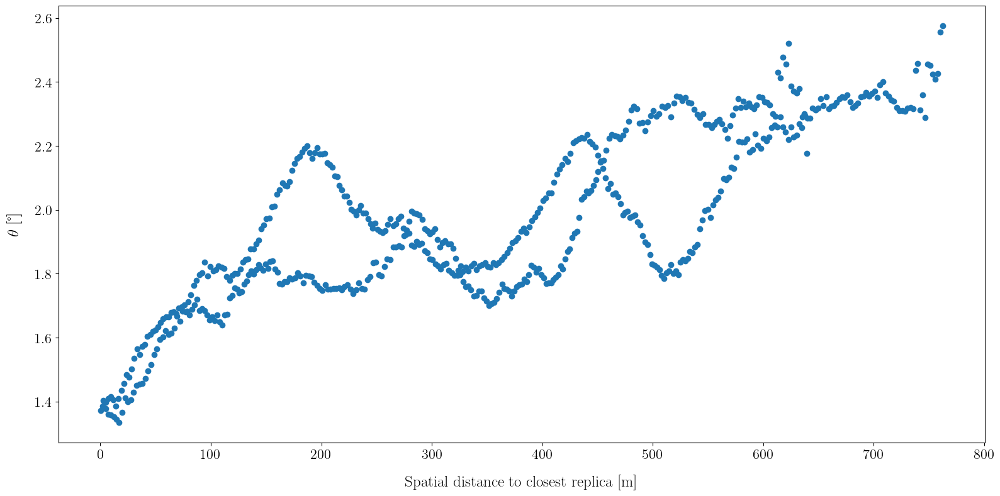

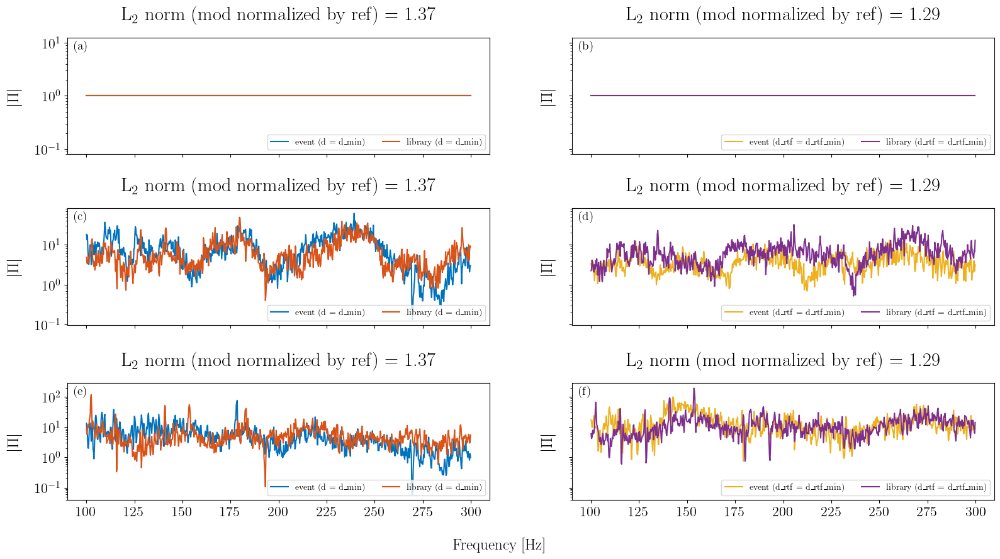

Matching with distance: combined_norm_L2_module_normalized_hermitian_angle_module
Matching original datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
Compute distance using euclidian angle between RTF modules (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


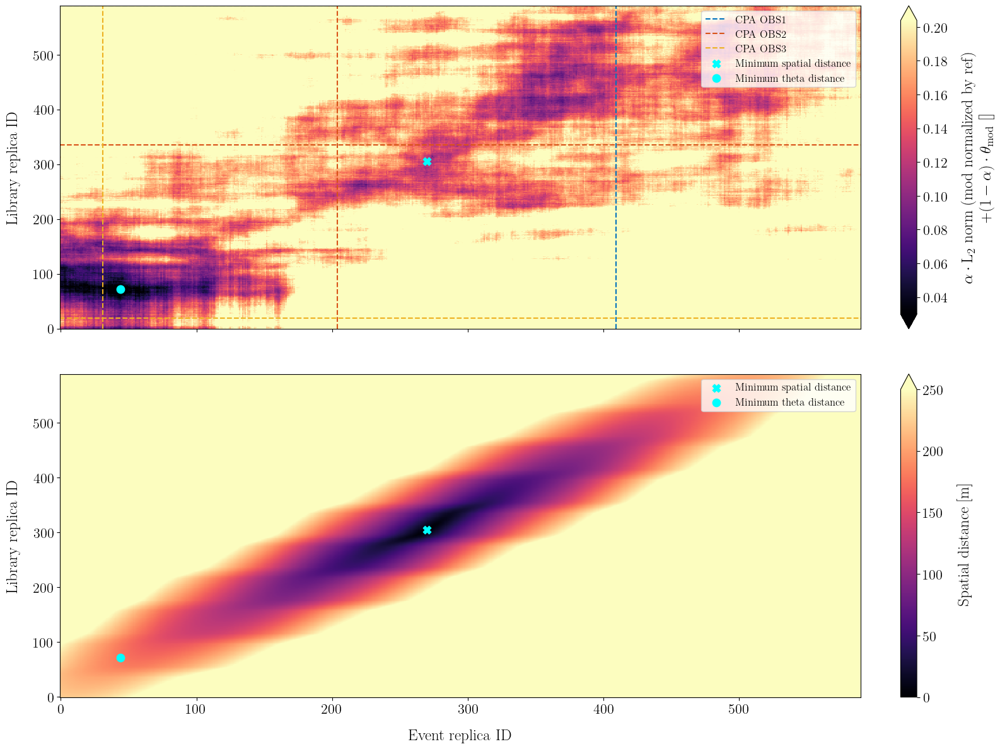

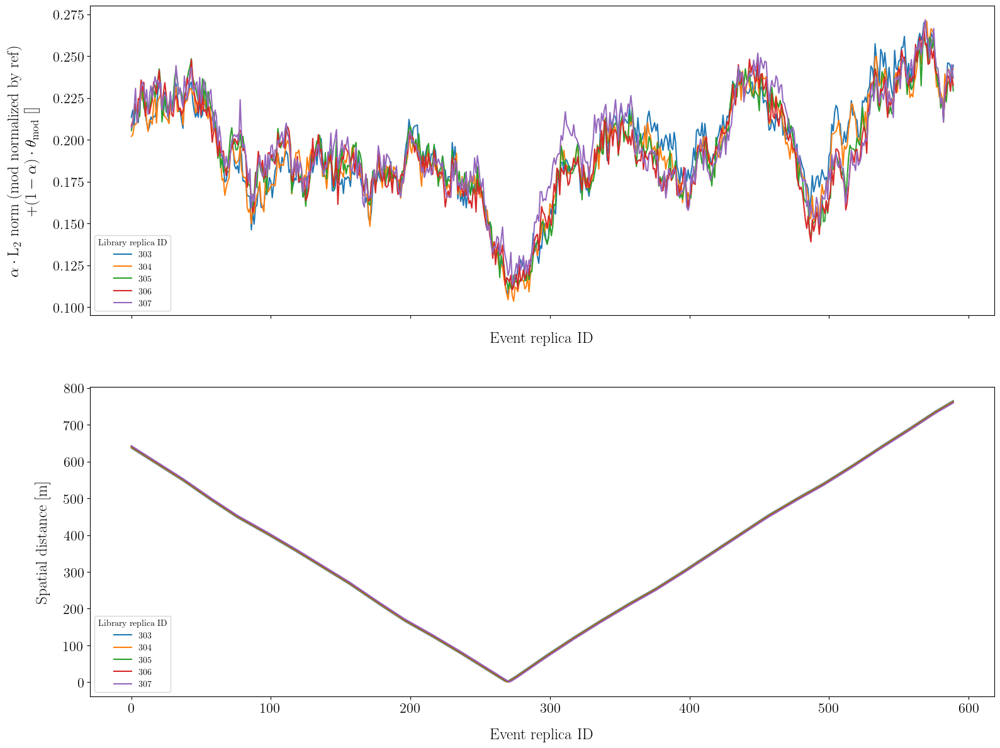

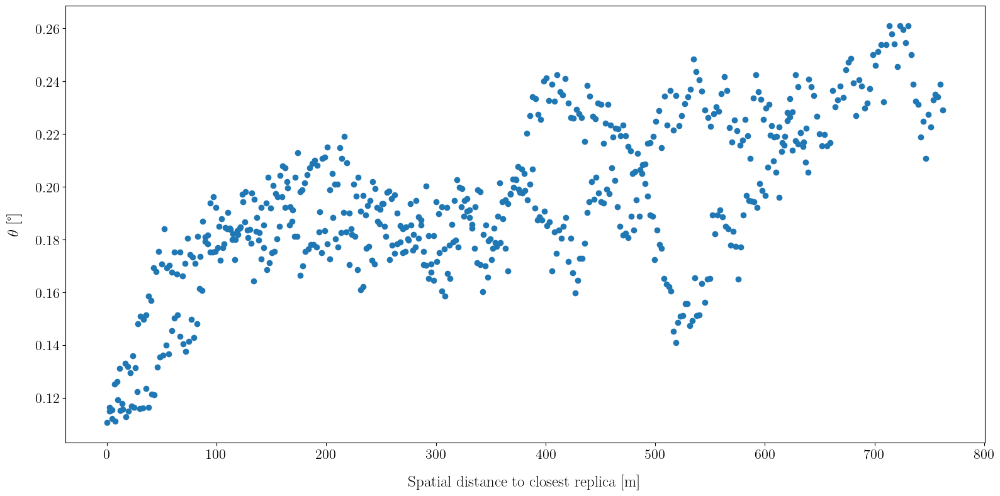

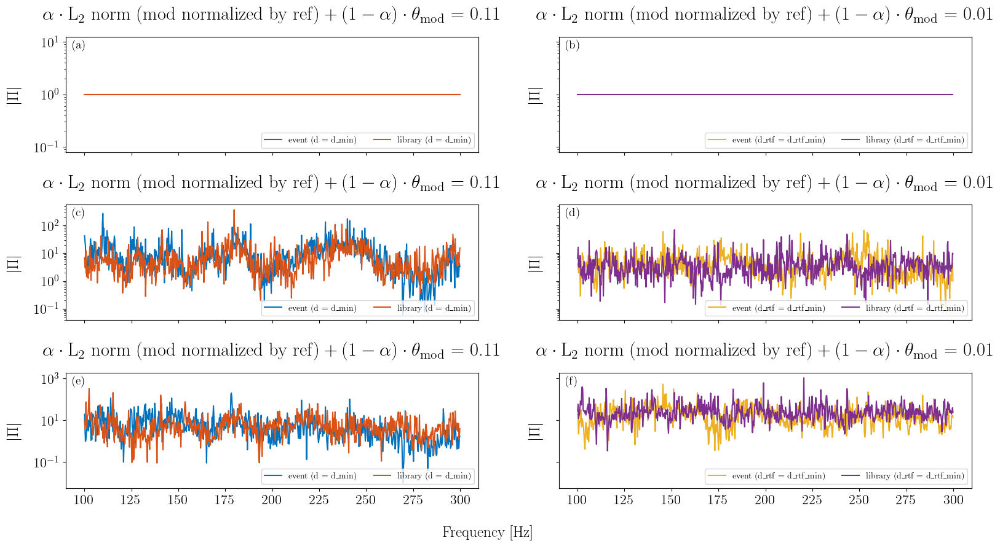

Matching smoothed datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
Compute distance using euclidian angle between RTF modules (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


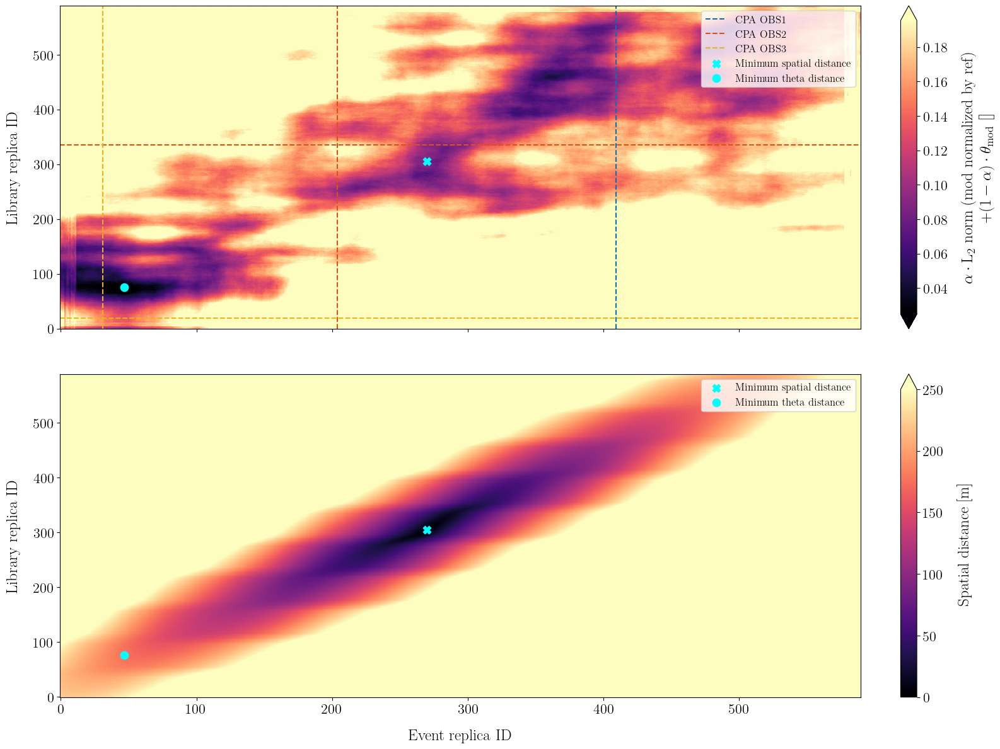

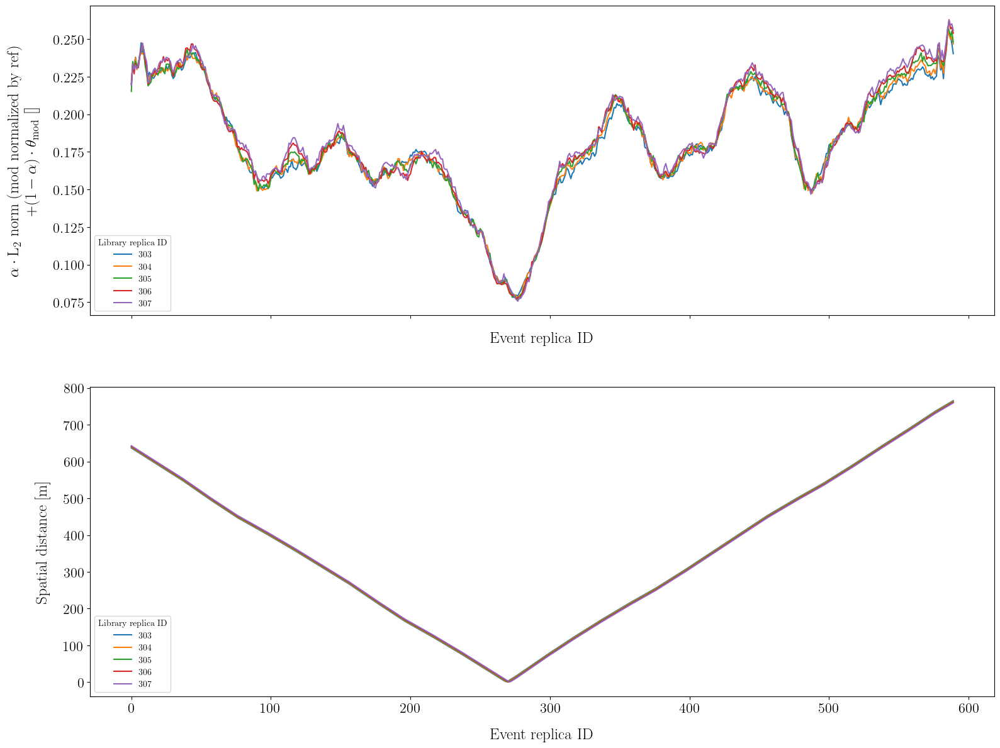

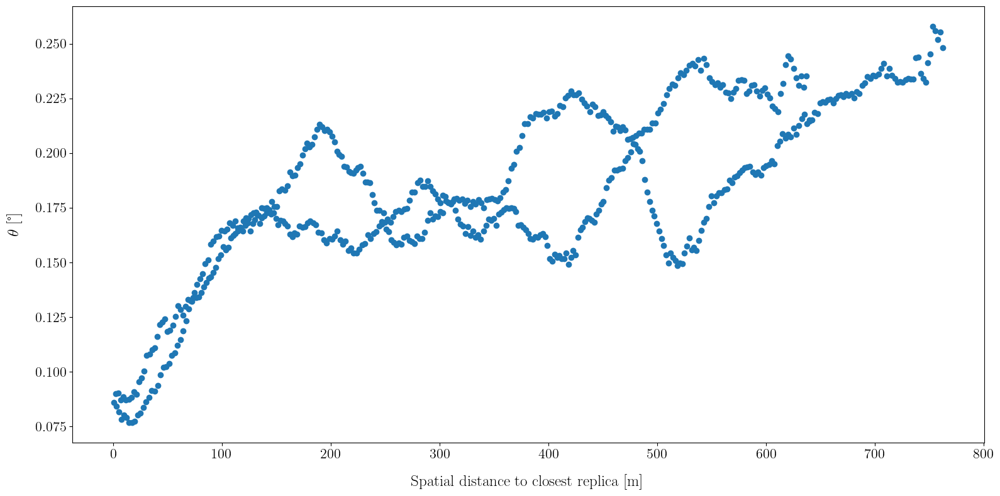

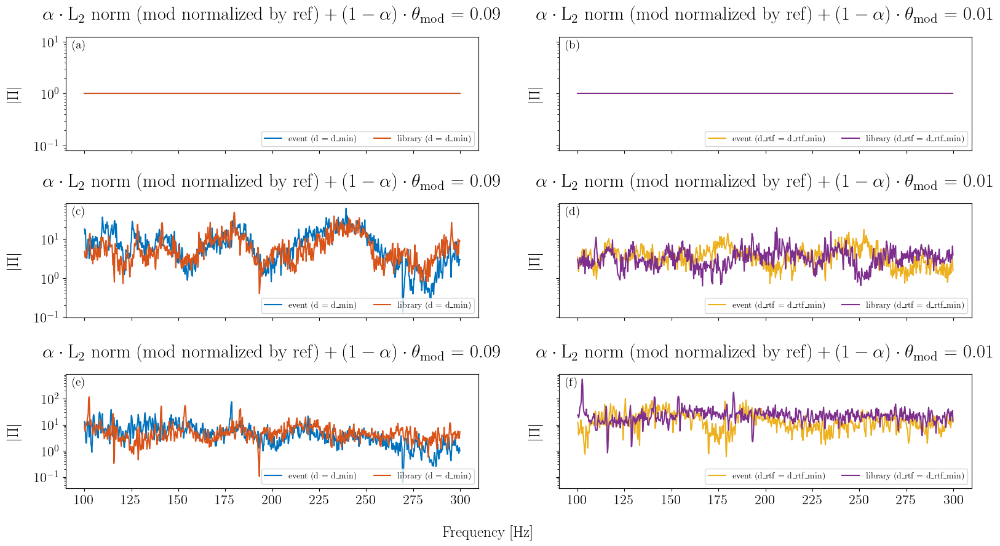

In [28]:
###########################
# Matching library and event features
###########################
fmin = 100
fmax = 300
dist_args = {
    "fmin": fmin,
    "fmax": fmax,
    "dist_type": None,
    "use_weighted_mean": False,
}

plot_args = {
    "plot_lib_pos": False,
    "plot_event_pos": False,
    "plot_lib_and_event_pos": True,
    "plot_dist_matrices": True,
    "plot_dist_around_sptial_min_dist": True,
    "plot_feature_details": True,
    "plot_feature_details_module": True,
    "plot_feature_details_phase": False,
    "plot_feature_details_theta": False,
}

distances = [
    # # "hermitian_angle",
    # "hermitian_angle_module",
    # # "hermitian_angle_along_freq",
    # # "norm_L1",
    "norm_L1_module",
    # # "norm_L2",
    "norm_L2_module",
    # # "norm_L2_normalized",
    "norm_L2_module_normalized",
    "combined_norm_L2_module_normalized_hermitian_angle_module",
]

init = True
for distance in distances:
    dist_args["dist_type"] = distance
    print(f"Matching with distance: {distance}")

    print(f"Matching original datasets")
    rtf_mfp_processor.match(
        ds_library=ds_lib, ds_event=ds_event, dist_args=dist_args, plot_args=plot_args
    )
    plt.show()
    print(f"Matching smoothed datasets")

    if init:
        plot_args["plot_lib_and_event_pos"] = False
        init = False

    rtf_mfp_processor.match(
        ds_library=ds_lib_smooth,
        ds_event=ds_event_smooth,
        dist_args=dist_args,
        plot_args=plot_args,
    )
    plt.show()

    plt.close("all")

Text(0.02, 0.5, 'Replica ID')

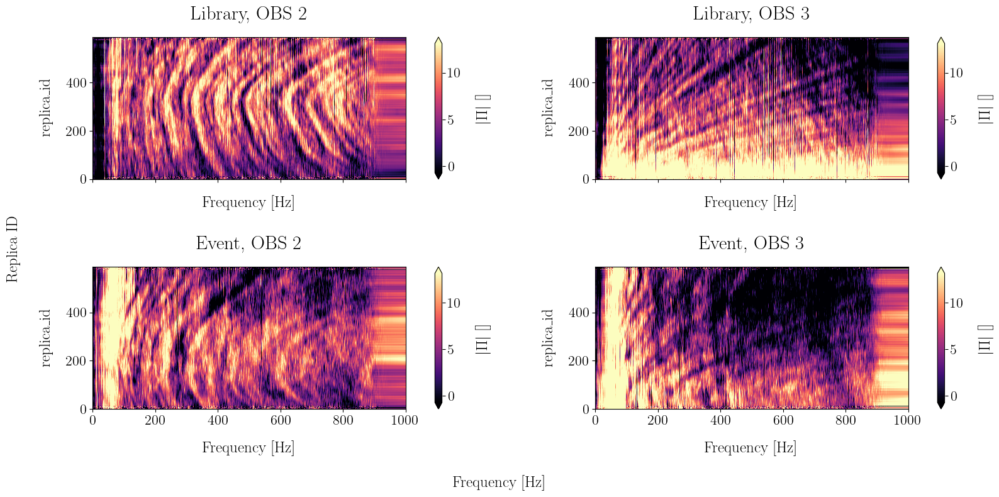

In [29]:
# Plot comparison between event and lib smooth

idx_rcvs = [
    idx
    for idx in ds_event_smooth.h_index.values
    if idx != ds_event_smooth.reference_receiver_id
]

fig, axs = plt.subplots(2, 2, sharex=True)

vmin = max(
    np.percentile(10 * np.log10(ds_lib_smooth.rtf_amp), 5),
    np.percentile(10 * np.log10(ds_event_smooth.rtf_amp), 5),
)
vmax = min(
    np.percentile(10 * np.log10(ds_lib_smooth.rtf_amp), 95),
    np.percentile(10 * np.log10(ds_event_smooth.rtf_amp), 95),
)
for i_col, idx_rcv in enumerate(idx_rcvs):
    lib_mod = 10 * np.log10(ds_lib_smooth.rtf_amp.sel(h_index=idx_rcv))
    lib_mod.plot(x="f_rtf", ax=axs[0, i_col], cmap="magma", vmin=vmin, vmax=vmax)
    axs[0, i_col].set_title(f"Library, OBS {idx_rcv}")
    event_mod = 10 * np.log10(ds_event_smooth.rtf_amp.sel(h_index=idx_rcv)) 
    event_mod.plot(x="f_rtf", ax=axs[1, i_col], cmap="magma", vmin=vmin, vmax=vmax)
    axs[1, i_col].set_title(f"Event, OBS {idx_rcv}")

fig.supxlabel("Frequency [Hz]")
fig.supylabel("Replica ID")
# plt.xlim([0, 200])

In [30]:
def filter_tauk(ds, P=12):
    n_r = ds.replica_id.size

    # Define the size of the Iq windows
    n_overlap_I = 1
    n_I = 2 * P + 1
    # size_I_r = n_I * dr

    print(f"Selected window I size:  n_I = {n_I} samples")

    # Compute the number of I_q windows Q
    Q = int(np.floor((n_r + n_overlap_I - n_I) / n_overlap_I))
    # Q = 100
    print(f"Number of available segments I : Q = {Q}")

    # Apply smoothing
    f = ds.f_rtf.values
    qth = 99.5

    idx_rcvs = [idx for idx in ds.h_index.values if idx != ds.reference_receiver_id]

    smooth_data = np.ones_like(ds.rtf_amp)
    for idx_rcv in idx_rcvs:

        rtf_mod = ds.rtf_amp.sel(h_index=idx_rcv)
        rtf_mod_smooth = rtf_mod.copy().values

        for q in range(0, Q):
            I_q_inf = q * n_overlap_I
            I_q_sup = q * n_overlap_I + n_I
            I_q_center = q * n_overlap_I + P  # P = n_I // 2
            # print(I_q_inf, I_q_sup)
            # Select I_q
            rtf_I_q = rtf_mod.isel(replica_id=slice(I_q_inf, I_q_sup))
            # Apply filter
            rtf_I_q = 10 * np.log10(rtf_I_q**2)

            # plt.figure()
            # rtf_I_q.plot(x="f_rtf", cmap="magma")
            # plt.savefig("test1")
            # Apply 2D FFT

            # Perform 2D fourier and shift the result to centre

            # # rFFT 2D
            # rtf_I_q_fft2 = np.fft.rfft2(rtf_I_q)
            # tau = np.fft.rfftfreq(rtf_I_q.shape[0], d=f[1] - f[0])  # Time lags
            # k = np.fft.rfftfreq(rtf_I_q.shape[1], d=1)  # Wavenumbers

            # vmin = np.percentile(np.abs(rtf_I_q_fft2), 10)
            # vmax = np.percentile(np.abs(rtf_I_q_fft2), 90)
            # plt.figure()
            # plt.pcolormesh(
            #     tau,
            #     k,
            #     np.abs(rtf_I_q_fft2).T,
            #     cmap="magma",
            #     vmax=vmax,
            #     vmin=vmin,
            # )
            # plt.xlabel(r"$\tau$ [s]")
            # plt.ylabel("k [1/m]")
            # plt.colorbar(label="Magnitude")
            # plt.xlim([0, np.max(tau)])
            # plt.ylim([0, np.max(k)])
            # plt.savefig("test2")

            # FFT 2D
            rtf_I_q_fft2 = np.fft.fft2(rtf_I_q)
            # delta_tau = 1 / (rtf_I_q.shape[0] * (f[1] - f[0]))  # Time resolution in tau-space
            # delta_k = 1 / (rtf_I_q.shape[1] * (f[1] - f[0]))  # Frequency resolution in k-space
            tau = np.fft.fftfreq(rtf_I_q.shape[0], d=f[1] - f[0])  # Time lags
            k = np.fft.fftfreq(rtf_I_q.shape[1], d=1)  # Wavenumbers    

            tau_shifted = np.fft.fftshift(tau)
            k_shifted = np.fft.fftshift(k)
            rtf_I_q_fft2shift = np.fft.fftshift(rtf_I_q_fft2)

            # vmin = np.percentile(np.abs(rtf_I_q_fft2shift), 10)
            # vmax = np.percentile(np.abs(rtf_I_q_fft2shift), 90)
            # plt.figure()
            # plt.pcolormesh(
            #     tau_shifted, k_shifted, np.abs(rtf_I_q_fft2shift).T, cmap="magma", vmax=vmax, vmin=vmin
            # )
            # plt.xlabel(r"$\tau$ [s]")
            # plt.ylabel("k [1/m]")
            # plt.colorbar(label="Magnitude")
            # # plt.xlim([0, np.max(tau_shifted)])
            # # plt.ylim([0, np.max(k_shifted)])
            # plt.savefig("test")

            # TODO change this
            # x_qth[:] = 0.035
            k_th = k[0]
            tau_th = 0.5

            # # Filter desired k
            rtf_I_q_fft2shift_filt = np.copy(rtf_I_q_fft2shift)  # ntau, nk
            # Define dedicated mask
            kk, tautau = np.meshgrid(k_shifted, tau_shifted)

            mask_tauk = np.logical_and((np.abs(kk) <= k_th), (np.abs(tautau) <= tau_th))

            # Apply mask
            rtf_I_q_fft2shift_filt[~mask_tauk] = 0
            rtf_I_q_fft2shift_filt = np.fft.ifftshift(rtf_I_q_fft2shift_filt)
            rtf_I_q_filt = np.fft.ifft2(
                rtf_I_q_fft2shift_filt, s=rtf_I_q.shape
            )
            rtf_I_q_filt = np.real(rtf_I_q_filt)
            rtf_I_q_filt = 10 ** (rtf_I_q_filt / 20)

            if q == 0:
                # q1 = np.percentile(rtf_I_q_psd, 25, axis=1)
                # q2 = np.percentile(rtf_I_q_psd, 50, axis=1)
                # q3 = np.percentile(rtf_I_q_psd, 75, axis=1)

                # # Q1
                # dx_q1 = np.abs(rtf_I_q_psd - q1[:, np.newaxis])  #
                # idx_xq1 = np.argmin(dx_q1, axis=1)
                # x_q1 = k[idx_xq1]
                # # Q2
                # dx_q2 = np.abs(rtf_I_q_psd - q2[:, np.newaxis])
                # idx_xq2 = np.argmin(dx_q2, axis=1)
                # x_q2 = k[idx_xq2]
                # # Q3
                # dx_q3 = np.abs(rtf_I_q_psd - q3[:, np.newaxis])
                # idx_xq3 = np.argmin(dx_q3, axis=1)
                # x_q3 = k[idx_xq3]

                # plt.figure()
                # plt.plot(k, rtf_I_q_psd[0, :])
                # plt.axvline(x_q1[0], color=color(1), label="Q1")
                # plt.axvline(x_q2[0], color=color(2), label="Q2")
                # plt.axvline(x_q3[0], color=color(3), label="Q3")
                # plt.axvline(x_qth[0], color=color(4), label="Qth")
                # plt.legend()

                plt.figure()
                plt.title("Mask k")
                plt.pcolormesh(
                    tau_shifted, k_shifted, (np.abs(kk) > k_th).T, cmap="Greys"
                    )

                plt.figure()
                plt.title("Mask tau")
                plt.pcolormesh(
                    tau_shifted, k_shifted, (np.abs(tautau) > tau_th).T, cmap="Greys"
                )
                plt.figure()
                plt.title("Mask tau_k")
                plt.pcolormesh(tau_shifted, k_shifted, mask_tauk.T, cmap="Greys")

                # plt.figure()
                # rtf_I_q.plot(x="replica_id", cmap="magma")

                # plt.figure()
                # rtf_I_q_psd = np.abs(rtf_I_q_fft2shift) ** 2
                # vmin = np.percentile(rtf_I_q_psd, 10)
                # vmax = np.percentile(rtf_I_q_psd, 90)
                # plt.pcolormesh(tau_shifted, k_shifted, rtf_I_q_psd.T, cmap="magma", vmax=vmax, vmin=vmin)
                # plt.axhline(k_th, color="cyan", zorder=10)
                # plt.axvline(tau_th, color="cyan", zorder=10)
                # plt.colorbar()
                # plt.xlabel(r"$\tau$ [s]")
                # plt.ylabel("k [1/m]")
                # plt.legend()
                # plt.xlim([0, np.max(tau_shifted)])
                # plt.ylim([0, np.max(k_shifted)])

                # plt.figure()
                # rtf_I_q_fft2shift_filt_psd = np.abs(rtf_I_q_fft2shift_filt) ** 2
                # vmin = np.percentile(rtf_I_q_fft2shift_filt_psd, 10)
                # vmax = np.percentile(rtf_I_q_fft2shift_filt_psd, 90)
                # plt.pcolormesh(
                #     tau_shifted,
                #     k_shifted,
                #     np.abs(rtf_I_q_fft2shift_filt_psd).T,
                #     cmap="magma",
                #     vmax=vmax,
                #     vmin=vmin,
                # )
                # plt.axhline(k_th, color="cyan", zorder=10)
                # plt.axvline(tau_th, color="cyan", zorder=10)
                # plt.colorbar()
                # plt.xlabel(r"$\tau$ [s]")
                # plt.ylabel("k [1/m]")
                # plt.legend()

                plt.figure()
                rtf_I_q_filt_xr = xr.zeros_like(rtf_I_q)
                rtf_I_q_filt_xr.data = rtf_I_q_filt
                rtf_I_q_filt_plot = 10 * np.log10(rtf_I_q_filt_xr**2)
                rtf_I_q_filt_plot.plot(x="replica_id", cmap="magma")

                # print(I_q_center)

            # Store modified rtf
            rtf_mod_smooth[:, I_q_center] = rtf_I_q_filt[:, P]
            # rtf_I_q_filt_P = rtf_I_q_filt[:, P]     # Center of the box
            # smooth_rtfs.append(rtf_I_q_filt_P)

        i_rcv = np.argmin(np.abs(ds_lib.h_index.values - idx_rcv))
        smooth_data[i_rcv, ...] = rtf_mod_smooth

    ds_smooth = ds.copy()
    ds_smooth.rtf_amp.data = smooth_data

    dist_rcv = get_dist_to_rcv(ds=ds)

    # Plot comparison
    plot_rtf_mod_along_sequence(
        ds,
        dist_rcv,
        obs_cpa_idx,
        reps,
        fig_folder,
        replica_id_slice=slice(0, 500),
        fmin=fmin,
        fmax=fmax,
    )

    plot_rtf_mod_along_sequence(
        ds_smooth,
        dist_rcv,
        obs_cpa_idx,
        reps,
        fig_folder,
        replica_id_slice=slice(0, 500),
        fmin=fmin,
        fmax=fmax,
    )

    before_smooth = 10 * np.log10(ds.rtf_amp.sel(h_index=idx_rcv))
    after_smooth = 10 * np.log10(ds_smooth.rtf_amp.sel(h_index=idx_rcv))

    sel_reps = [50, 100, 150]
    for i_rep, rep in enumerate(sel_reps):
        before_smooth_rs = before_smooth.sel(replica_id=rep, method="nearest")
        after_smooth_rs = after_smooth.sel(replica_id=rep, method="nearest")

        plt.figure()
        before_smooth_rs.plot(
            x="f_rtf",
            label=f"Original (rep = {before_smooth_rs.replica_id.values:.2f})",
        )
        after_smooth_rs.plot(
            x="f_rtf", label=f"Smooth (rep = {after_smooth_rs.replica_id.values:.2f})"
        )
        # plt.xscale("log")
        plt.legend()

        plt.xlim([100, 300])

    print(f"Processing bootstrap for original dataset")
    # process_bootstrap(ds=ds)
    print(f"Processing bootstrap for smoothed dataset")
    # process_bootstrap(ds=ds_smooth)

    return ds_smooth

Selected window I size:  n_I = 25 samples
Number of available segments I : Q = 566
Processing bootstrap for original dataset
Processing bootstrap for smoothed dataset
Selected window I size:  n_I = 25 samples
Number of available segments I : Q = 566


C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_18776\4174223112.py:190: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


Processing bootstrap for original dataset
Processing bootstrap for smoothed dataset


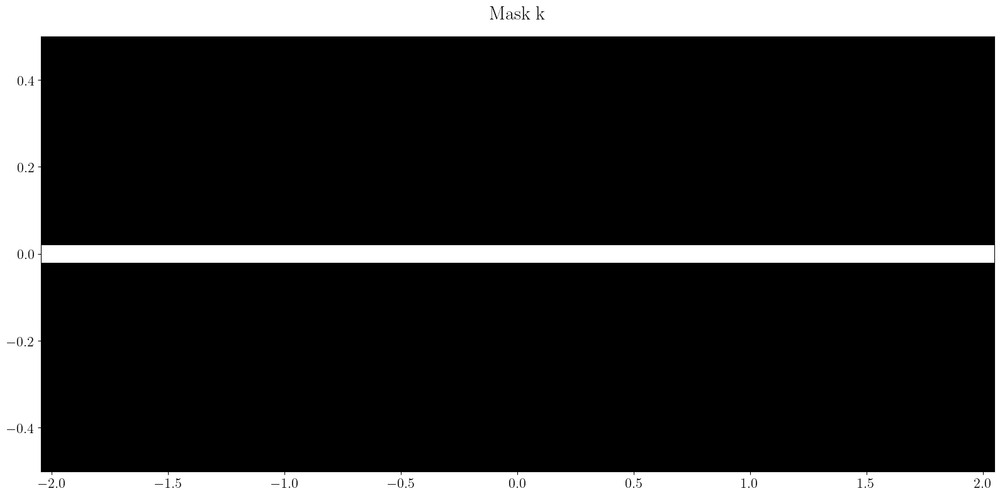

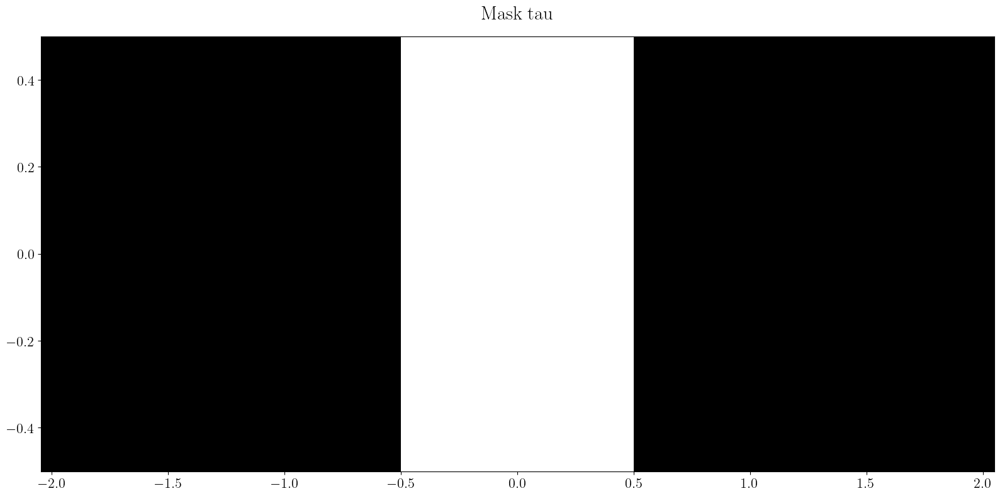

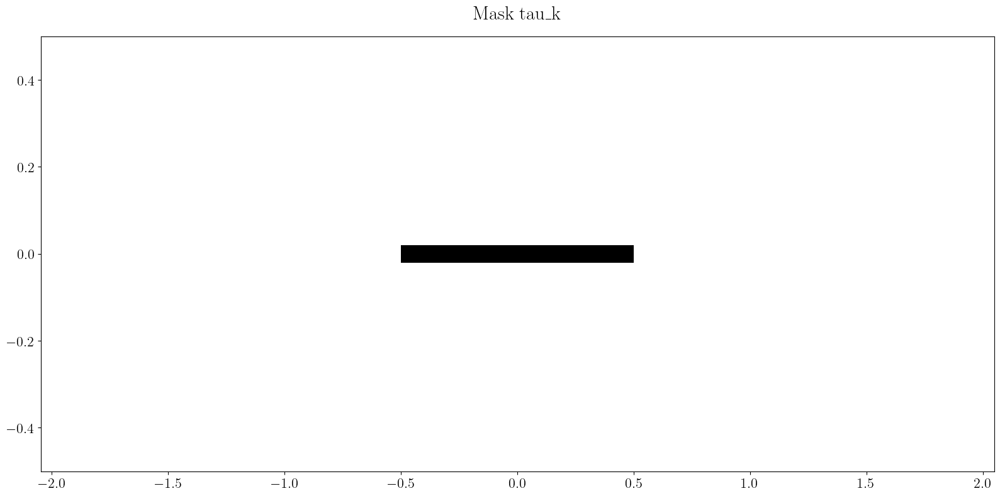

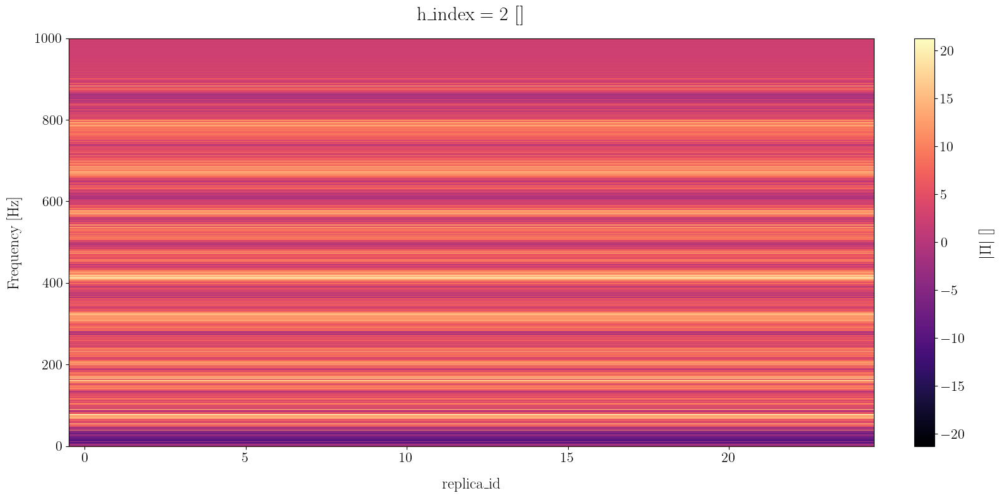

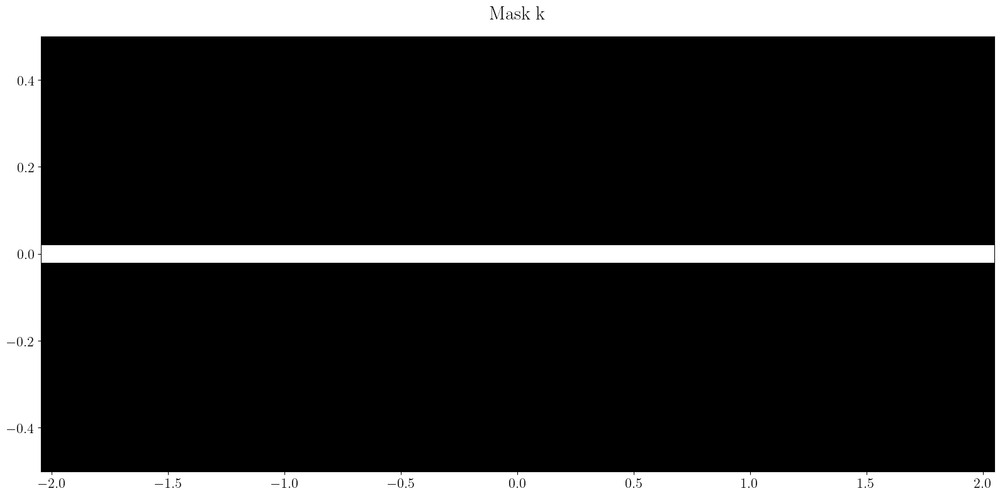

...

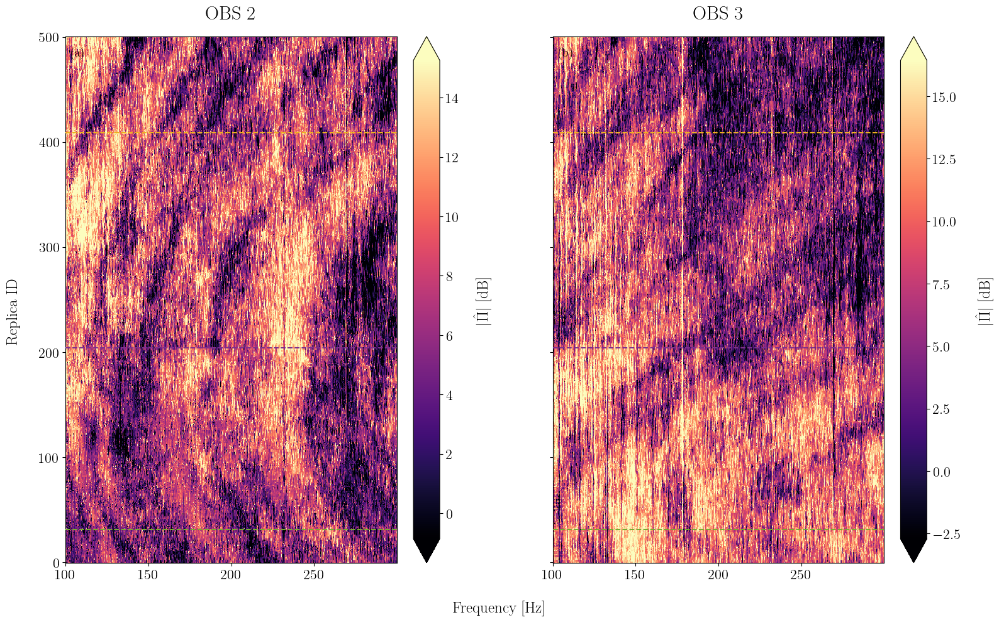

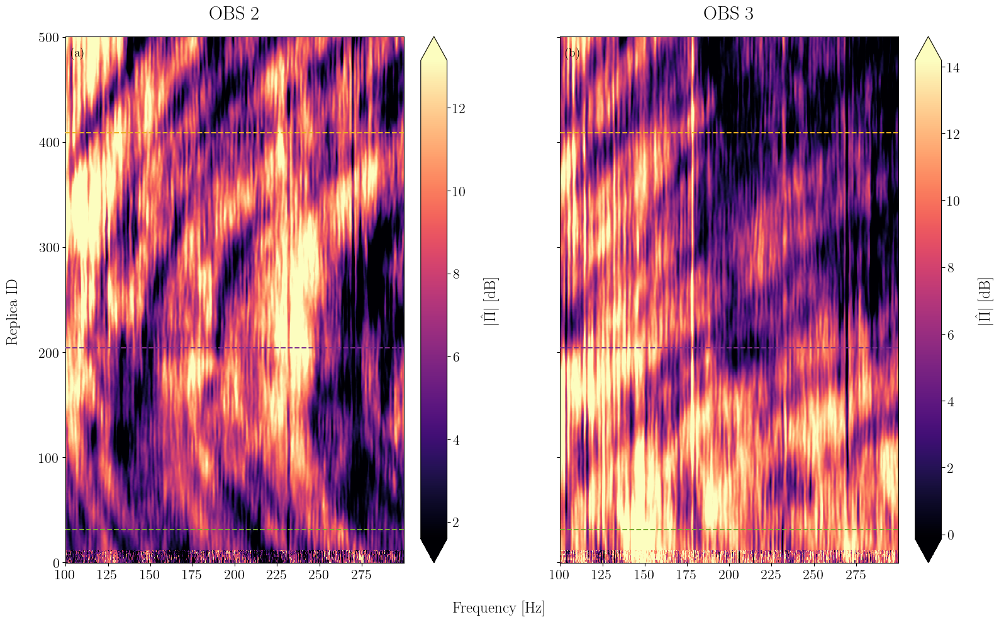

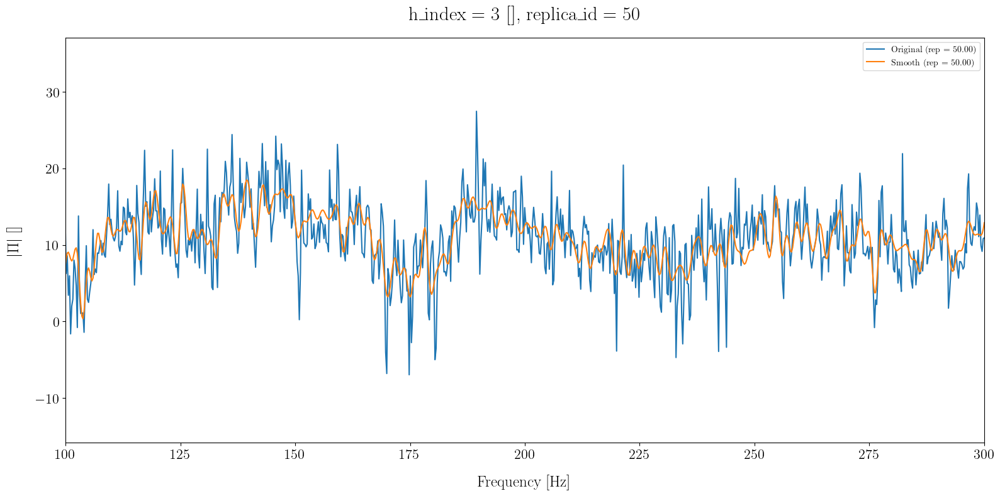

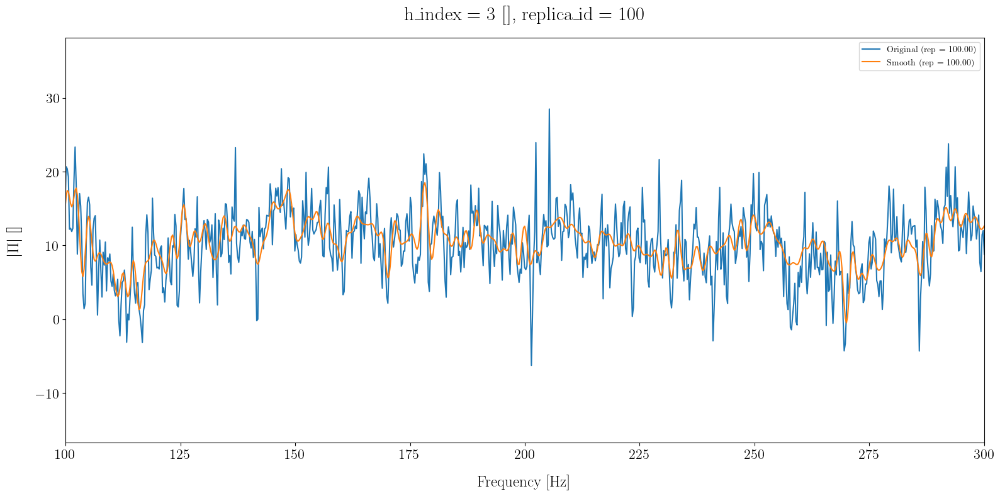

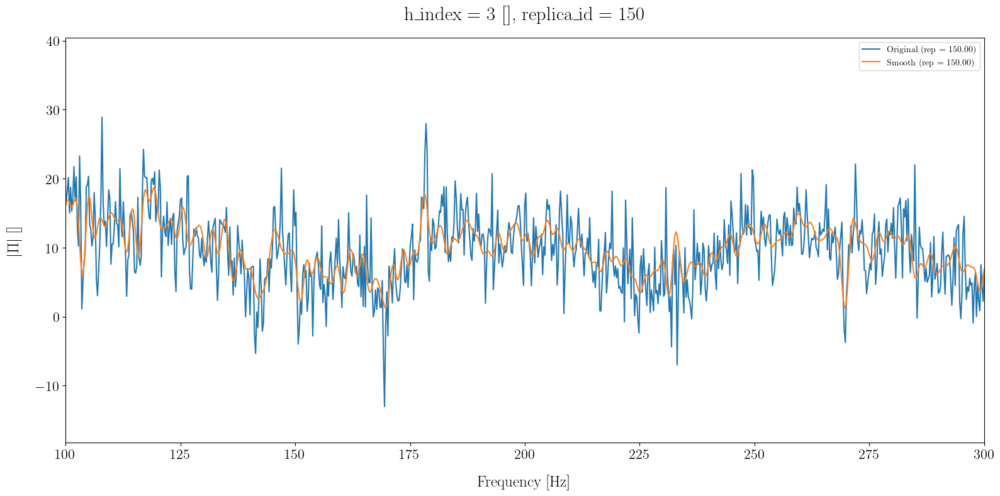

In [31]:
ds_lib_smooth_tauk = filter_tauk(ds_lib, P=P)
ds_event_smooth_tauk = filter_tauk(ds_event, P=P)

Text(0.02, 0.5, 'Replica ID')

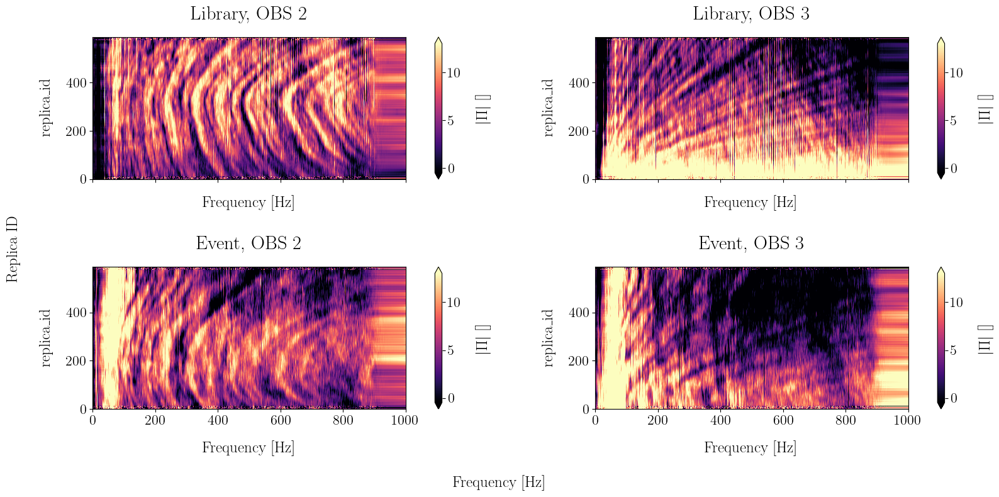

In [32]:
# Plot comparison between event and lib smooth
idx_rcvs = [
    idx
    for idx in ds_event_smooth_tauk.h_index.values
    if idx != ds_event_smooth_tauk.reference_receiver_id
]

fig, axs = plt.subplots(2, 2, sharex=True)

vmin = max(
    np.percentile(10 * np.log10(ds_lib_smooth_tauk.rtf_amp), 5),
    np.percentile(10 * np.log10(ds_event_smooth_tauk.rtf_amp), 5),
)
vmax = min(
    np.percentile(10 * np.log10(ds_lib_smooth_tauk.rtf_amp), 95),
    np.percentile(10 * np.log10(ds_event_smooth_tauk.rtf_amp), 95),
)
for i_col, idx_rcv in enumerate(idx_rcvs):
    lib_mod = 10 * np.log10(ds_lib_smooth_tauk.rtf_amp.sel(h_index=idx_rcv))
    lib_mod.plot(x="f_rtf", ax=axs[0, i_col], cmap="magma", vmin=vmin, vmax=vmax)
    axs[0, i_col].set_title(f"Library, OBS {idx_rcv}")
    event_mod = 10 * np.log10(ds_event_smooth_tauk.rtf_amp.sel(h_index=idx_rcv))
    event_mod.plot(x="f_rtf", ax=axs[1, i_col], cmap="magma", vmin=vmin, vmax=vmax)
    axs[1, i_col].set_title(f"Event, OBS {idx_rcv}")

fig.supxlabel("Frequency [Hz]")
fig.supylabel("Replica ID")
# plt.xlim([0, 200])

Matching with distance: norm_L2_module_normalized
Matching original datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


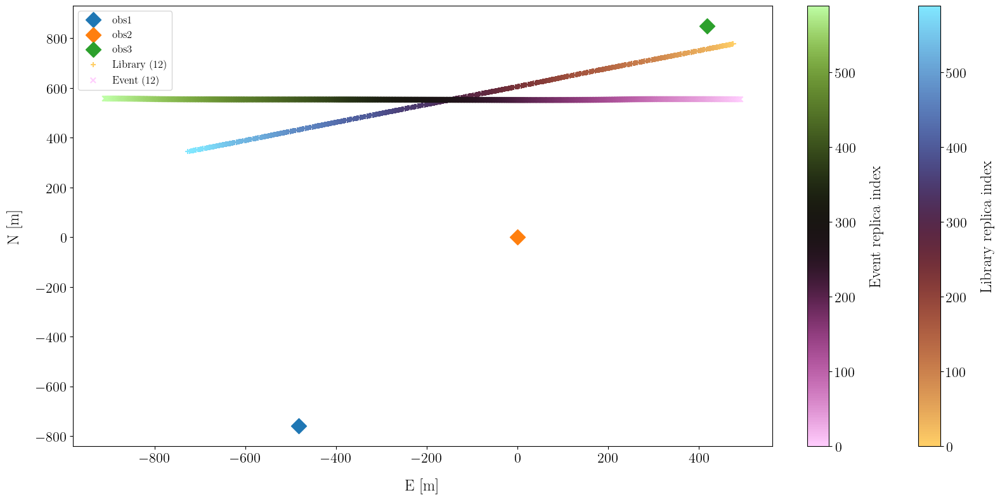

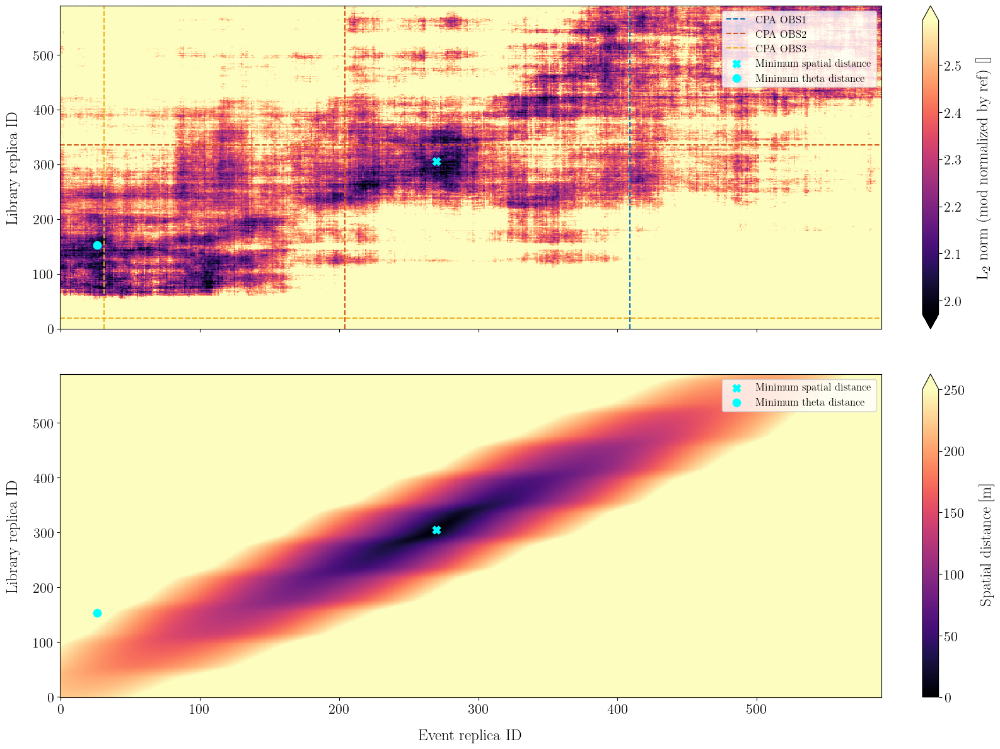

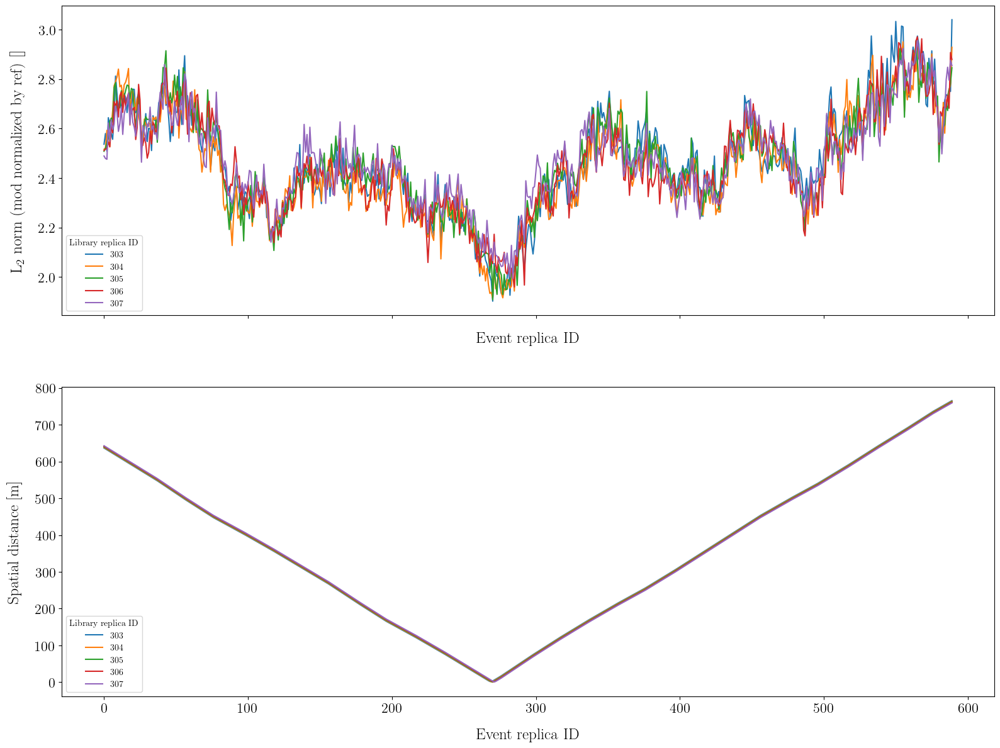

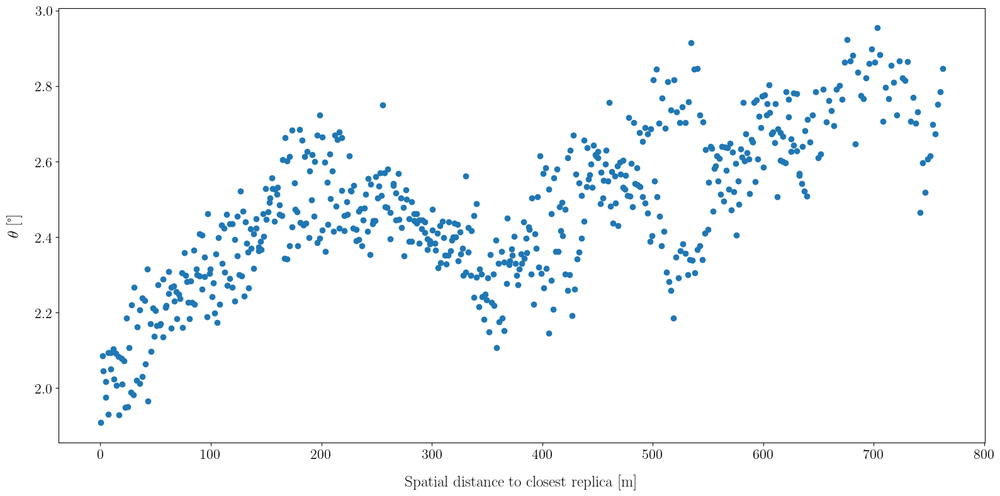

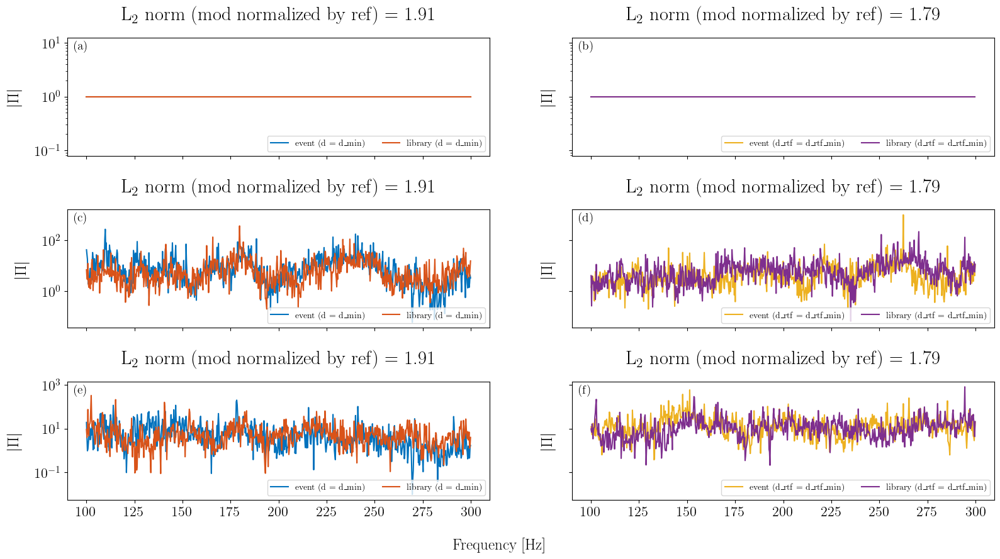

Matching smoothed datasets
Compute L2 norm for RTF module normalized with ref RTF (in R^Nrcv)
	Plotting RTF distance vs spatial distance


C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\src\localisation\rtf\rtf_mfp.py:2517: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(fpath, bbox_inches="tight")


	Plotting RTF distance vs spatial distance (sorted by distance)


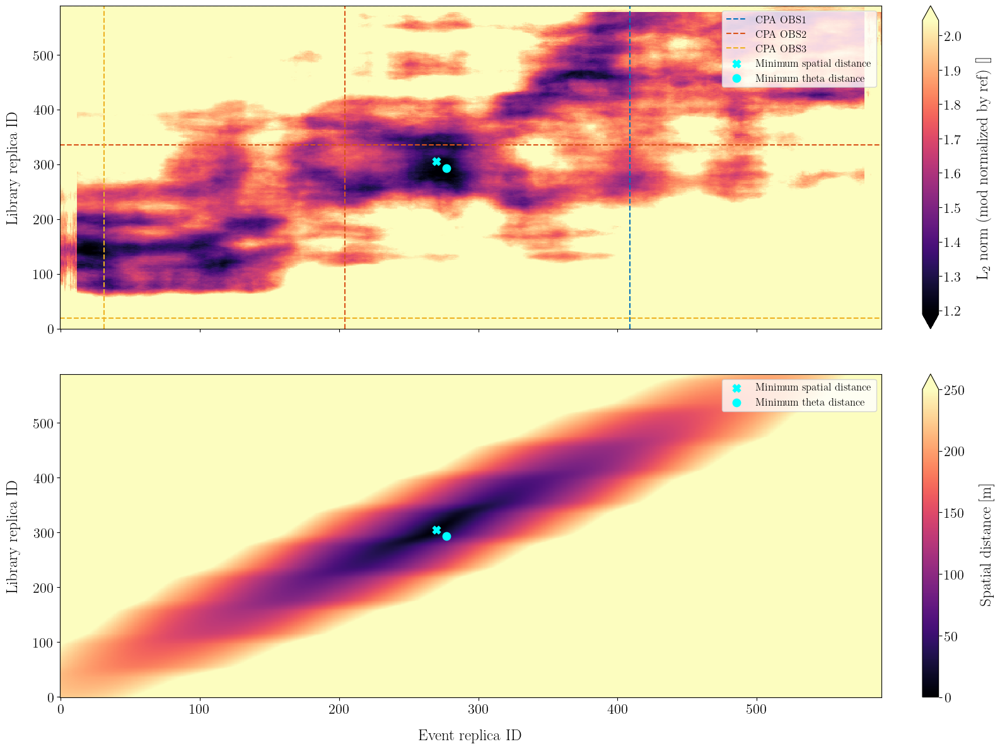

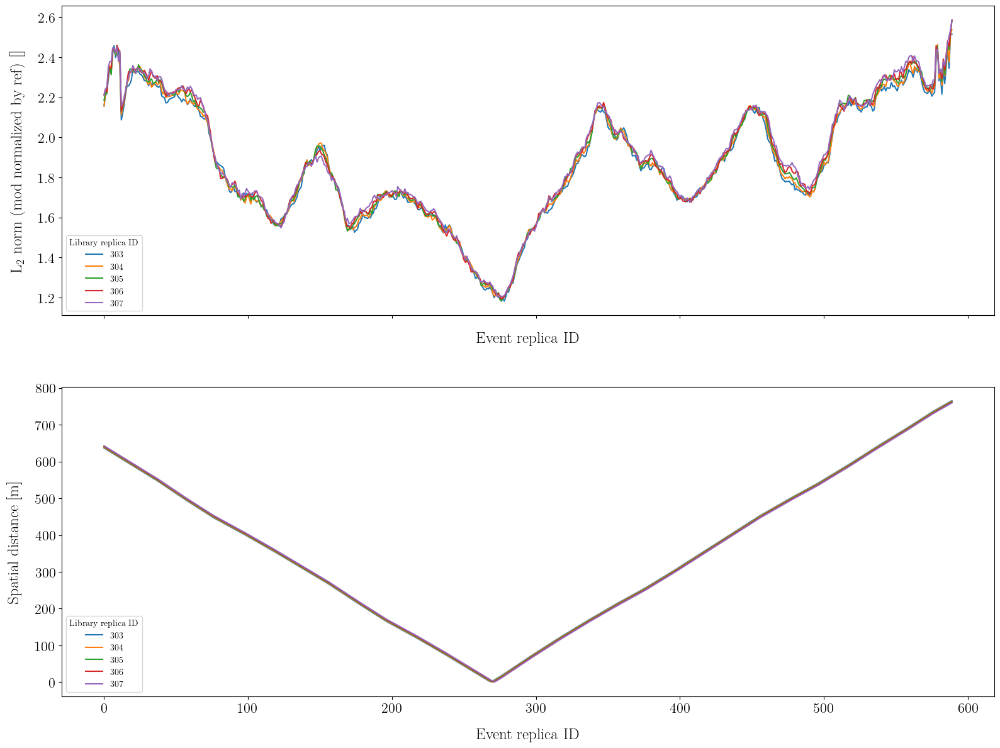

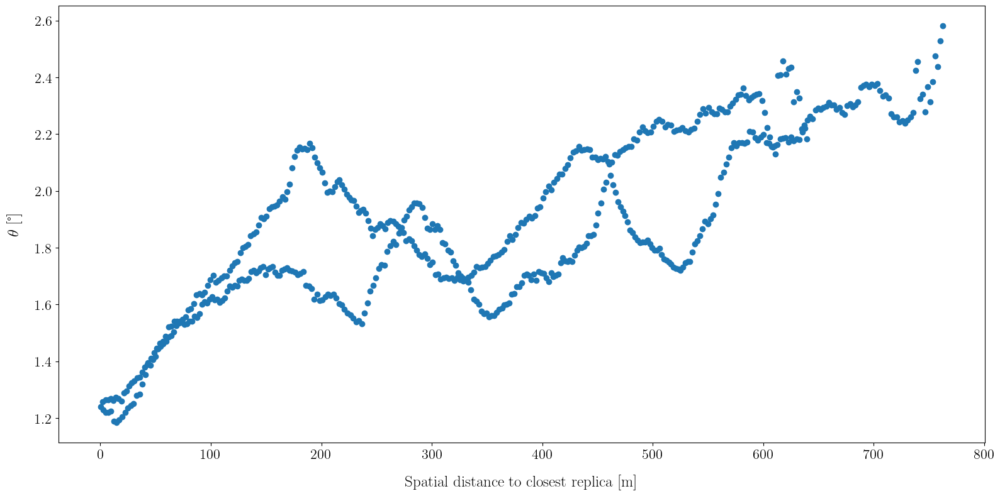

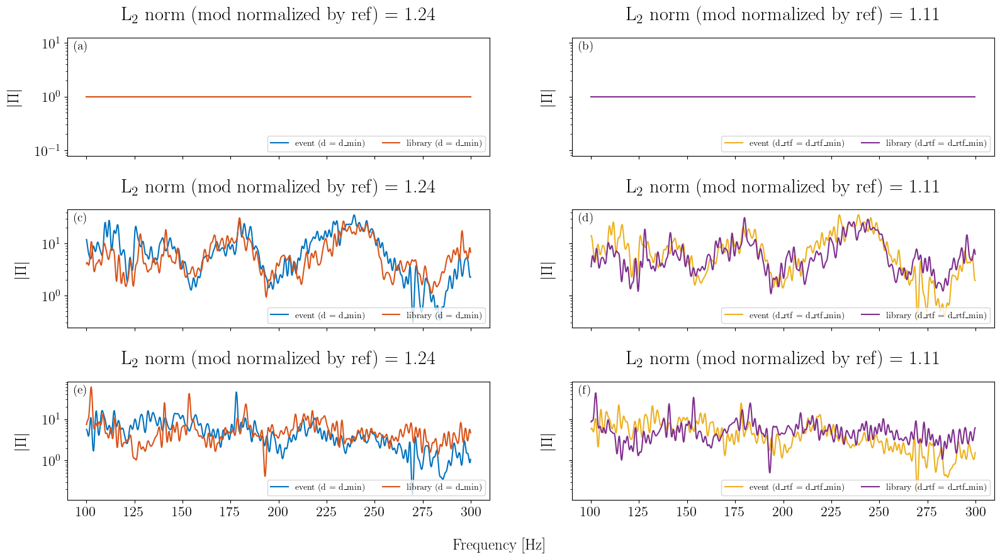

In [33]:
# # Load or compute
# load_precomputed = True

# P = 12
# root_ = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data"

# fpath_event_smooth = os.path.join(root_, "event", f"event_{ds_event.id}_smooth_P{P}.nc")
# fpath_library_smooth = os.path.join(
#     root_, "library", f"library_{ds_lib.id}_smooth_P{P}.nc"
# )

# if load_precomputed:
#     ds_event_smooth = xr.open_dataset(fpath_event_smooth)
#     ds_lib_smooth = xr.open_dataset(fpath_library_smooth)
# else:

#     ds_lib_smooth = process_smooth(ds_lib, P=P)
#     plt.show()
#     plt.close("all")
#     ds_event_smooth = process_smooth(ds_event, P=P)
#     plt.show()
#     plt.close("all")
#     # Save smooth
#     ds_event_smooth.to_netcdf(fpath_event_smooth)
#     ds_lib_smooth.to_netcdf(fpath_library_smooth)

###########################
# Matching library and event features
###########################
fmin = 100
fmax = 300
dist_args = {
    "fmin": fmin,
    "fmax": fmax,
    "dist_type": None,
    "use_weighted_mean": False,
}

plot_args = {
    "plot_lib_pos": False,
    "plot_event_pos": False,
    "plot_lib_and_event_pos": True,
    "plot_dist_matrices": True,
    "plot_dist_around_sptial_min_dist": True,
    "plot_feature_details": True,
    "plot_feature_details_module": True,
    "plot_feature_details_phase": False,
    "plot_feature_details_theta": False,
}

distances = [
    # "hermitian_angle",
    # "hermitian_angle_module",
    # "hermitian_angle_along_freq",
    # "norm_L1",
    # "norm_L1_module",
    # "norm_L2",
    # "norm_L2_module",
    # "norm_L2_normalized",
    "norm_L2_module_normalized",
]

init = True
for distance in distances:
    dist_args["dist_type"] = distance
    print(f"Matching with distance: {distance}")

    print(f"Matching original datasets")
    rtf_mfp_processor.match(
        ds_library=ds_lib, ds_event=ds_event, dist_args=dist_args, plot_args=plot_args
    )
    plt.show()
    print(f"Matching smoothed datasets")

    if init:
        plot_args["plot_lib_and_event_pos"] = False
        init = False

    rtf_mfp_processor.match(
        ds_library=ds_lib_smooth_tauk,
        ds_event=ds_event_smooth_tauk,
        dist_args=dist_args,
        plot_args=plot_args,
    )
    plt.show()

    plt.close("all")